<a href="https://colab.research.google.com/github/PattiAlves/Modelagem_IA/blob/main/1.%20TRATAMENTO%20E%20AN%C3%81LISE%20DE%20DADOS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **1. TRATAMENTO E ANÁLISE DE DADOS**

### **1.1 Conversão de arquivos de precipitação .txt em planilha de dados**

In [ ]:
# 1. Montar o Google Drive (execute apenas se estiver rodando no Google Colab)
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import glob
import os
import pandas as pd

# 1. Montar o Google Drive (ignora se já estiver montado)
try:
  from google.colab import drive

  drive.mount('/content/drive')
except:
  pass

# 2. Caminho da pasta no Drive
pasta_txt = '/content/drive/MyDrive/PUC/EQM2118/CHUVA_2010_2026'

lista_dfs = []
arquivos_txt = glob.glob(os.path.join(pasta_txt, '*.txt'))

# Período estrito da Etapa 1
data_inicio = pd.to_datetime('2010-07-14 17:40:00')
data_fim = pd.to_datetime('2024-10-31 23:59:59')

if not arquivos_txt:
  print('Nenhum arquivo .txt encontrado na pasta especificada.')
else:
  for arquivo in arquivos_txt:
    try:
      # Leitura por largura fixa (fwf) baseada estritamente no layout visual do TXT:
      # 01 a 10: Dia
      # 12 a 20: Hora
      # 35 a 41: Coluna de 01 h (precip_1h)
      colspecs = [(0, 10), (12, 20), (35, 41)]
      names = ['Dia', 'Hora', 'precip_1h']

      df = pd.read_fwf(
          arquivo,
          skiprows=5,
          colspecs=colspecs,
          names=names,
          encoding='latin1',
      )

      df = df.dropna(how='all')
      if df.empty:
        continue

      # Filtra apenas linhas onde a coluna 'Dia' começa com o formato de data (DD/MM/AAAA)
      df = df[df['Dia'].astype(str).str.contains(r'^\d{2}/\d{2}/\d{4}', na=False)]
      if df.empty:
        continue

      # Criação da coluna datetime combinando Dia e Hora
      df['datetime'] = pd.to_datetime(
          df['Dia'].astype(str) + ' ' + df['Hora'].astype(str),
          format='%d/%m/%Y %H:%M:%S',
          errors='coerce',
      )

      # Converte precip_1h para numérico
      df['precip_1h'] = pd.to_numeric(df['precip_1h'], errors='coerce')

      # Seleciona estritamente as colunas desejadas
      df_final = df[['datetime', 'precip_1h']].copy()
      lista_dfs.append(df_final)

    except Exception as e:
      print(f'Erro ao processar o arquivo {os.path.basename(arquivo)}: {e}')

  if lista_dfs:
    # Concatena todos os DataFrames
    df_consolidado = pd.concat(lista_dfs, ignore_index=True)

    # Remove nulos, elimina duplicadas e ordena cronologicamente
    df_consolidado = (
        df_consolidado.dropna(subset=['datetime'])
        .drop_duplicates(subset=['datetime'])
        .sort_values('datetime')
        .reset_index(drop=True)
    )

    # Aplica o filtro temporal estrito da Etapa 1
    df_consolidado = df_consolidado[
        (df_consolidado['datetime'] >= data_inicio)
        & (df_consolidado['datetime'] <= data_fim)
    ]

    # Salva o arquivo final da Etapa 1 no Google Drive
    caminho_saida = os.path.join(
        pasta_txt, 'banco_precipitacoes_etapa1_2010_2024.xlsx'
    )
    df_consolidado.to_excel(caminho_saida, index=False)

    print(
        f'Etapa 1 concluída com sucesso! Arquivo salvo em: {caminho_saida} ('
        f'{len(df_consolidado)} registros)'
    )

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Etapa 1 concluída com sucesso! Arquivo salvo em: /content/drive/MyDrive/PUC/EQM2118/CHUVA_2010_2026/banco_precipitacoes_etapa1_2010_2024.xlsx (499641 registros)


### **1.2 Interpolação de dados de chuva para frequência de 10min**

In [ ]:
import os
import pandas as pd

# 1. Caminho da pasta no Google Drive
pasta_txt = '/content/drive/MyDrive/PUC/EQM2118/CHUVA_2010_2026'
caminho_etapa1 = os.path.join(
    pasta_txt, 'banco_precipitacoes_etapa1_2010_2024.xlsx'
)

# 2. Carrega a base gerada na Etapa 1
df_etapa1 = pd.read_excel(caminho_etapa1)

# Converte datetime para o tipo adequado e define como índice
df_etapa1['datetime'] = pd.to_datetime(df_etapa1['datetime'])
df_etapa1 = df_etapa1.sort_values('datetime').reset_index(drop=True)

# 3. Define a data de início exata solicitada (14/07/2010 18:00:00)
data_inicio = pd.to_datetime('2010-07-14 18:00:00')
df_etapa1 = df_etapa1[df_etapa1['datetime'] >= data_inicio]

# 4. Criação do novo grid temporal de 10 em 10 minutos
data_fim = df_etapa1['datetime'].max()
grid_10min = pd.date_range(start=data_inicio, end=data_fim, freq='10min')

# Cria um DataFrame temporário com o grid de 10 min
df_10min = pd.DataFrame({'datetime': grid_10min})

# 5. Mesclagem e interpolação dos dados para a frequência de 10 minutos
# Como a precipitação acumulada de 1h varia suavemente ou pode ser distribuída uniformemente/linearmente:
df_merged = pd.merge_asof(
    df_10min, df_etapa1, on='datetime', direction='nearest'
)

# Se preferir interpolação linear dos valores de 1h para estimar os passos intermediários de 10 min:
df_merged['precip_1h_interpolada'] = df_merged['precip_1h'].interpolate(
    method='linear'
)

# Para obter a precipitação de 10 min (precip_10min), divide-se a taxa horária proporcionalmente por 6
# ou aplica-se o método de desagregação desejado:
df_merged['precip_10min'] = df_merged['precip_1h_interpolada'] / 6.0

# Seleciona as colunas finais solicitadas: 'datetime', 'precip_10min' e 'precip_1h'
df_final_10min = df_merged[['datetime', 'precip_10min', 'precip_1h_interpolada']].copy()
df_final_10min.rename(columns={'precip_1h_interpolada': 'precip_1h'}, inplace=True)

# 6. Salva a nova base interpolada de 10 minutos no Google Drive
caminho_saida_10min = os.path.join(
    pasta_txt, 'banco_precipitacoes_10min_2010_2024.xlsx'
)
df_final_10min.to_excel(caminho_saida_10min, index=False)

print(f'Etapa 2 concluída com sucesso! Arquivo salvo em: {caminho_saida_10min}')
print(f'Total de registros de 10 min gerados: {len(df_final_10min)}')

Etapa 2 concluída com sucesso! Arquivo salvo em: /content/drive/MyDrive/PUC/EQM2118/CHUVA_2010_2026/banco_precipitacoes_10min_2010_2024.xlsx
Total de registros de 10 min gerados: 752147


In [ ]:
import os
import pandas as pd

# Caminho da base gerada na Etapa 2
pasta_txt = '/content/drive/MyDrive/PUC/EQM2118/CHUVA_2010_2026'
caminho_10min = os.path.join(
    pasta_txt, 'banco_precipitacoes_10min_2010_2024.xlsx'
)

# Carrega a base de 10 minutos
df = pd.read_excel(caminho_10min)
df['datetime'] = pd.to_datetime(df['datetime'])

print('--- 1. ESTATÍSTICAS BÁSICAS ---')
print(df[['precip_10min', 'precip_1h']].describe())

print('\n--- 2. VERIFICAÇÃO DE VALORES NEGATIVOS ---')
negativos = (df['precip_10min'] < 0).sum()
print(f'Quantidade de valores negativos encontrados: {negativos}')

print('\n--- 3. TESTE DE CONSERVAÇÃO DE VOLUME (POR HORA) ---')
# Agrupa os valores de 10 min por hora e compara com a média/soma esperada
df['hora_truncada'] = df['datetime'].dt.floor('h')
comparacao = (
    df.groupby('hora_truncada')
    .agg({'precip_10min': 'sum', 'precip_1h': 'mean'})
    .reset_index()
)

print(comparacao.head(10))

--- 1. ESTATÍSTICAS BÁSICAS ---
        precip_10min      precip_1h
count  752147.000000  752147.000000
mean        0.019723       0.118335
std         0.173295       1.039770
min         0.000000       0.000000
25%         0.000000       0.000000
50%         0.000000       0.000000
75%         0.000000       0.000000
max        18.266667     109.600000

--- 2. VERIFICAÇÃO DE VALORES NEGATIVOS ---
Quantidade de valores negativos encontrados: 0

--- 3. TESTE DE CONSERVAÇÃO DE VOLUME (POR HORA) ---
        hora_truncada  precip_10min  precip_1h
0 2010-07-14 18:00:00      0.766667   0.766667
1 2010-07-14 19:00:00      0.666667   0.666667
2 2010-07-14 20:00:00      1.866667   1.866667
3 2010-07-14 21:00:00      0.900000   0.900000
4 2010-07-14 22:00:00      0.300000   0.300000
5 2010-07-14 23:00:00      0.733333   0.733333
6 2010-07-15 00:00:00      0.100000   0.100000
7 2010-07-15 01:00:00      0.000000   0.000000
8 2010-07-15 02:00:00      0.000000   0.000000
9 2010-07-15 03:00:00      0

### **1.3 Consolidação dados de chuva de 2010 a 2026**

In [ ]:
import glob
import os
import pandas as pd

# 1. Montar o Google Drive (ignora se já estiver montado)
try:
  from google.colab import drive

  drive.mount('/content/drive')
except Exception:
  pass

# 2. Caminho da pasta no Drive
pasta_txt = '/content/drive/MyDrive/PUC/EQM2118/CHUVA_2010_2026'

lista_dfs_novos = []
arquivos_txt = sorted(glob.glob(os.path.join(pasta_txt, '*.txt')))

# Período dos dados com frequência real de 5 minutos a partir de 01/11/2024
data_inicio_etapa2 = pd.to_datetime('2024-11-01 00:00:00')
data_fim_etapa2 = pd.to_datetime('2026-09-19 23:59:59')

if not arquivos_txt:
  print('Nenhum arquivo .txt encontrado na pasta especificada.')
else:
  for arquivo in arquivos_txt:
    try:
      with open(arquivo, 'r', encoding='latin1') as f:
        linhas = f.readlines()

      header_tokens = None
      for l in linhas:
        if 'Dia' in l and 'Hora' in l:
          raw_tokens = l.strip().split()
          header_tokens = []
          i = 0
          while i < len(raw_tokens):
            t = raw_tokens[i]
            if (
                t in ['05', '10', '15']
                and i + 1 < len(raw_tokens)
                and raw_tokens[i + 1] == 'min'
            ):
              header_tokens.append(f'{t} min')
              i += 2
            elif (
                t in ['01', '04', '24', '96']
                and i + 1 < len(raw_tokens)
                and raw_tokens[i + 1] == 'h'
            ):
              header_tokens.append(f'{t} h')
              i += 2
            else:
              header_tokens.append(t)
              i += 1
          break

      if not header_tokens:
        continue

      dados_arquivo = []
      for linha in linhas:
        parts = linha.strip().split()
        if len(parts) >= 2 and '/' in parts[0] and ':' in parts[1]:
          dia = parts[0]
          hora = parts[1]
          has_hbv = len(parts) > 2 and parts[2] == 'HBV'
          start_idx = 3 if has_hbv else 2
          data_tokens = parts[start_idx:]

          row_dict = {'Dia': dia, 'Hora': hora}
          for idx, col in enumerate(header_tokens[2:]):
            row_dict[col] = data_tokens[idx] if idx < len(data_tokens) else None
          dados_arquivo.append(row_dict)

      if not dados_arquivo:
        continue

      df = pd.DataFrame(dados_arquivo)
      # Suporta tanto HH:MM:SS quanto HH:MM
      dt_com_seg = pd.to_datetime(
          df['Dia'].astype(str) + ' ' + df['Hora'].astype(str),
          format='%d/%m/%Y %H:%M:%S',
          errors='coerce',
      )
      dt_sem_seg = pd.to_datetime(
          df['Dia'].astype(str) + ' ' + df['Hora'].astype(str),
          format='%d/%m/%Y %H:%M',
          errors='coerce',
      )
      df['datetime'] = dt_com_seg.fillna(dt_sem_seg)

      # Filtra estritamente o período de 01/11/2024 em diante (frequência de 5 min)
      df = df[
          (df['datetime'] >= data_inicio_etapa2)
          & (df['datetime'] <= data_fim_etapa2)
      ].dropna(subset=['datetime'])

      if df.empty:
        continue

      # Extrai chuva de 5 min e chuva de 1 h
      if '05 min' in df.columns:
        df['precip_05min'] = pd.to_numeric(
            df['05 min'].astype(str).str.replace(',', '.'), errors='coerce'
        )
      elif '10 min' in df.columns:
        # Fallback caso algum arquivo traga 10 min direto
        df['precip_05min'] = pd.to_numeric(
            df['10 min'].astype(str).str.replace(',', '.'), errors='coerce'
        ) / 2.0
      else:
        continue

      if '01 h' in df.columns:
        df['precip_1h'] = pd.to_numeric(
            df['01 h'].astype(str).str.replace(',', '.'), errors='coerce'
        )
      else:
        df['precip_1h'] = float('nan')

      df_final = df[['datetime', 'precip_05min', 'precip_1h']].copy()
      lista_dfs_novos.append(df_final)

    except Exception as e:
      print(f'Erro ao processar o arquivo {os.path.basename(arquivo)}: {e}')

  if lista_dfs_novos:
    df_5min = (
        pd.concat(lista_dfs_novos, ignore_index=True)
        .sort_values('datetime')
        .drop_duplicates(subset=['datetime'], keep='last')
        .set_index('datetime')
    )

    # Grade alvo contínua de 10 minutos
    grade_10min = pd.date_range(
        start=data_inicio_etapa2.floor('10min'),
        end=data_fim_etapa2.ceil('10min'),
        freq='10min',
    )

    # Agrega diretamente em blocos de 10 min a partir da frequência de 5 min e alinha à grade
    precip_10min_alinhada = (
        df_5min['precip_05min']
        .resample('10min', label='right', closed='right')
        .sum(min_count=1)
        .reindex(grade_10min)
    )

    # Alinha precip_1h à grade de 10 minutos (pega o último registro válido de cada bloco de 10 min, se existir)
    precip_1h_alinhada = (
        df_5min['precip_1h']
        .resample('10min', label='right', closed='right')
        .last()
        .reindex(grade_10min)
    )

    df_etapa2 = pd.DataFrame({
        'datetime': grade_10min,
        'precip_10min': precip_10min_alinhada.values,
        'precip_1h': precip_1h_alinhada.values,
    })

    # Carrega a base anterior de 10 minutos (2010–2024)
    caminho_10min_antigo = os.path.join(
        pasta_txt, 'banco_precipitacoes_10min_2010_2024.xlsx'
    )

    if os.path.exists(caminho_10min_antigo):
      df_base_antiga = pd.read_excel(caminho_10min_antigo)
      df_base_antiga['datetime'] = pd.to_datetime(df_base_antiga['datetime'])

      # Concatena a base anterior com a nova base convertida de 5 min para 10 min
      df_completo = pd.concat(
          [df_base_antiga, df_etapa2], ignore_index=True
      )

      # Limpeza final, remoção de duplicadas e ordenação
      df_completo = (
          df_completo.dropna(subset=['datetime'])
          .sort_values('datetime')
          .drop_duplicates(subset=['datetime'], keep='last')
          .reset_index(drop=True)
      )

      # Salva o arquivo unificado final
      caminho_saida_final = os.path.join(
          pasta_txt, 'banco_precipitacoes_completo_2010_2026.csv'
      )
      df_completo.to_csv(caminho_saida_final, index=False)

      print(
          'Processo concluído com sucesso! Base completa unificada salva em:'
          f' {caminho_saida_final} ({len(df_completo)} registros totais)'
      )
    else:
      print(
          'O arquivo da base anterior não foi encontrado em:'
          f' {caminho_10min_antigo}'
      )

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Processo concluído com sucesso! Base completa unificada salva em: /content/drive/MyDrive/PUC/EQM2118/CHUVA_2010_2026/banco_precipitacoes_completo_2010_2026.csv (851220 registros totais)


### *1.3.1 Análise da consistência dos dados do banco de chuva consolidado de 2010 a 2026*

In [ ]:
import os
import pandas as pd

try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except Exception:
    pass

pasta_chuva = '/content/drive/MyDrive/PUC/EQM2118/CHUVA_2010_2026'
caminho_csv = os.path.join(pasta_chuva, 'banco_precipitacoes_completo_2010_2026.csv')

# 1. Carregar base consolidada
df = pd.read_csv(caminho_csv)
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
df = df.dropna(subset=['datetime']).sort_values('datetime').reset_index(drop=True)

print("=== 1. VISÃO GERAL E INTEGRIDADE TEMPORAL ===")
print(f"Total de linhas: {len(df)}")
print(f"Início: {df['datetime'].min()} | Fim: {df['datetime'].max()}")
print(f"Timestamps duplicados: {df['datetime'].duplicated().sum()}")

diffs = df['datetime'].diff().dropna()
saltos = diffs[diffs != pd.Timedelta(minutes=10)]
print(f"Intervalos diferentes de 10 min: {len(saltos)}")
if not saltos.empty:
    print(saltos.value_counts().head(10))

# 2. Valores ausentes (NaN) e zeros
print("\n=== 2. AUSÊNCIAS (NaN) E ZEROS ===")
for col in [c for c in ['precip_10min', 'precip_1h'] if c in df.columns]:
    n_nan = df[col].isna().sum()
    pct_nan = 100 * n_nan / len(df)
    n_zero = (df[col] == 0).sum()
    pct_zero = 100 * n_zero / len(df)
    print(f"{col}: {n_nan} NaNs ({pct_nan:.2f}%) | {n_zero} zeros ({pct_zero:.2f}%)")

# 3. Valores negativos e maiores extremos
print("\n=== 3. VALORES NEGATIVOS E MAIORES EXTREMOS ===")
if 'precip_10min' in df.columns:
    neg_10 = df[df['precip_10min'] < 0]
    print(f"precip_10min < 0: {len(neg_10)} registros")
    if not neg_10.empty:
        print(neg_10[['datetime', 'precip_10min']].head(10))

    print("\nTop 15 maiores valores de precip_10min:")
    print(df.nlargest(15, 'precip_10min')[['datetime', 'precip_10min', 'precip_1h'] if 'precip_1h' in df.columns else ['datetime', 'precip_10min']])

if 'precip_1h' in df.columns:
    neg_1h = df[df['precip_1h'] < 0]
    print(f"\nprecip_1h < 0: {len(neg_1h)} registros")
    print("\nTop 15 maiores valores de precip_1h:")
    print(df.nlargest(15, 'precip_1h')[['datetime', 'precip_10min', 'precip_1h'] if 'precip_10min' in df.columns else ['datetime', 'precip_1h']])

# 4. Inconsistência entre precip_10min e precip_1h
if 'precip_10min' in df.columns and 'precip_1h' in df.columns:
    incons_10_gt_1h = df[df['precip_10min'] > df['precip_1h']]
    print(f"\n=== 4. CASOS COM precip_10min > precip_1h: {len(incons_10_gt_1h)} ===")
    if not incons_10_gt_1h.empty:
        print(incons_10_gt_1h[['datetime', 'precip_10min', 'precip_1h']].head(15))

# 5. Resumo anual (% de NaN e acumulado anual)
if 'precip_10min' in df.columns:
    df['ano'] = df['datetime'].dt.year
    resumo_ano = df.groupby('ano').agg(
        total_registros=('precip_10min', 'size'),
        nan_10min=('precip_10min', lambda s: s.isna().sum()),
        pct_nan_10min=('precip_10min', lambda s: 100 * s.isna().mean()),
        soma_10min_mm=('precip_10min', 'sum'),
        max_10min_mm=('precip_10min', 'max')
    )
    print("\n=== 5. RESUMO ANUAL (precip_10min) ===")
    print(resumo_ano.round(2))

=== 1. VISÃO GERAL E INTEGRIDADE TEMPORAL ===
Total de linhas: 851220
Início: 2010-07-14 18:00:00 | Fim: 2026-09-20 00:00:00
Timestamps duplicados: 0
Intervalos diferentes de 10 min: 1
datetime
0 days 00:20:00    1
Name: count, dtype: int64

=== 2. AUSÊNCIAS (NaN) E ZEROS ===
precip_10min: 297 NaNs (0.03%) | 795662 zeros (93.47%)
precip_1h: 240 NaNs (0.03%) | 786878 zeros (92.44%)

=== 3. VALORES NEGATIVOS E MAIORES EXTREMOS ===
precip_10min < 0: 0 registros

Top 15 maiores valores de precip_10min:
                  datetime  precip_10min  precip_1h
761779 2025-01-06 21:20:00     30.400000       23.2
762148 2025-01-09 10:50:00     24.000000       41.6
774359 2025-04-04 06:00:00     23.000000       26.8
772145 2025-03-19 21:00:00     21.800000       23.4
762149 2025-01-09 11:00:00     21.200000       49.8
813351 2025-12-31 00:40:00     20.600000       17.8
818918 2026-02-07 16:30:00     20.400000       13.4
399210 2018-02-15 01:00:00     18.266667      109.6
758444 2024-12-14 17:30:00  

### *1.3.2 Tratamento dos dados inexistentes (identificação e coluna substituta com valores nulos)*

In [ ]:
import os
import pandas as pd

pasta_chuva = '/content/drive/MyDrive/PUC/EQM2118/CHUVA_2010_2026'
caminho_csv = os.path.join(pasta_chuva, 'banco_precipitacoes_completo_2010_2026.csv')

df = pd.read_csv(caminho_csv)
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.sort_values('datetime').reset_index(drop=True)

# 1. Flag explícita indicando onde havia dado faltante em precip_10min
df['flag_nan_precip_10min'] = df['precip_10min'].isna().astype(int)

# 2. Série auxiliar apenas para modelos que não aceitam NaN (mantendo 'precip_10min' original intacta)
df['precip_10min_modelo'] = df['precip_10min'].fillna(0.0)

# Salva versão tratada com flag
caminho_tratado = os.path.join(pasta_chuva, 'banco_precipitacoes_tratado_2010_2026.csv')
df.to_csv(caminho_tratado, index=False)

print("Total de registros com flag de NaN:", df['flag_nan_precip_10min'].sum())
print("Arquivo salvo em:", caminho_tratado)

Total de registros com flag de NaN: 297
Arquivo salvo em: /content/drive/MyDrive/PUC/EQM2118/CHUVA_2010_2026/banco_precipitacoes_tratado_2010_2026.csv


### *1.3.3 Tratamento de dados de chuva da estação Rio Centro para complementação de dados faltantes da estação Cidade de Deus*

In [10]:
import glob
from io import StringIO
import os
import re
import numpy as np
import pandas as pd

# 1. Montar o Google Drive (ignora se já estiver montado)
try:
  from google.colab import drive

  if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
except Exception:
  pass

# 2. Caminhos de entrada e saída na pasta AUXILIAR
pasta_auxiliar = '/content/drive/MyDrive/PUC/EQM2118/AUXILIAR'
caminho_saida_unico = os.path.join(
    pasta_auxiliar, 'precip_RioCentro_10min_1h_202401_202609.csv'
)

# Regex para linhas da tabela com: Dia Hora [HBV] 05min 10min 15min 01h ...
padrao_10min_layout = re.compile(
    r'^\s*(\d{2}/\d{2}/\d{4})\s+(\d{2}:\d{2}:\d{2})\s+'
    r'(?:[A-Za-z0-9_-]+\s+)?'
    r'([-+]?\d+(?:[.,]\d+)?|NaN|nan|-)\s+'  # 05 min
    r'([-+]?\d+(?:[.,]\d+)?|NaN|nan|-)\s+'  # 10 min
    r'([-+]?\d+(?:[.,]\d+)?|NaN|nan|-)\s+'  # 15 min
    r'([-+]?\d+(?:[.,]\d+)?|NaN|nan|-)'  # 01 h
)


def _limpar_num(val_str):
  if val_str is None:
    return np.nan
  s_val = str(val_str).strip().replace(',', '.')
  if s_val.lower() in ('', 'nan', '-', 'none', 'null'):
    return np.nan
  try:
    return float(s_val)
  except ValueError:
    return np.nan


def ler_arquivo_txt_hibrido(caminho_arq):
  """Lê arquivos .txt de Barra/Riocentro suportando layout de 15 min (jan-out/2024)

  e layout com 05 min / 10 min / 15 min / 01 h (nov/2024-set/2026).
  """
  with open(caminho_arq, 'r', encoding='utf-8', errors='replace') as f:
    linhas = [l.rstrip('\r\n') for l in f]

  idx_cab = None
  for i, linha in enumerate(linhas):
    if 'Dia' in linha and 'Hora' in linha:
      idx_cab = i
      break

  if idx_cab is None:
    return pd.DataFrame(columns=['datetime', 'p_15min', 'p_10min', 'p_01h'])

  cabecalho_linha = linhas[idx_cab]
  tem_05min = '05 min' in cabecalho_linha

  registros = []

  if tem_05min:
    for linha in linhas[idx_cab + 1 :]:
      m = padrao_10min_layout.match(linha)
      if m:
        dia, hora, _, v_10, v_15, v_01h = m.groups()
        registros.append({
            'dt_str': f'{dia} {hora}',
            'p_15min': _limpar_num(v_15),
            'p_10min': _limpar_num(v_10),
            'p_01h': _limpar_num(v_01h),
        })
  else:
    # Layout sem '05 min' (ex.: Dia Hora [HBV] 15 min 01 h 04 h 24 h 96 h)
    texto_tab = '\n'.join(linhas[idx_cab:])
    df_tab = pd.read_csv(
        StringIO(texto_tab), sep=r'\s+', engine='python', dtype=str
    )
    if df_tab.shape[1] >= 2:
      dt_series = (
          df_tab.iloc[:, 0].astype(str).str.strip()
          + ' '
          + df_tab.iloc[:, 1].astype(str).str.strip()
      )
      # Tenta localizar colunas numéricas após 'Hora'
      cols_num = [c for c in df_tab.columns[2:] if c != 'HBV']
      # Normalmente a primeira coluna de chuva após Dia/Hora/HBV é 15 min e a seguinte é 01 h
      c_15 = cols_num[0] if len(cols_num) >= 1 else None
      c_01h = cols_num[1] if len(cols_num) >= 2 else None

      for idx_r in range(len(df_tab)):
        dt_s = dt_series.iloc[idx_r]
        if re.match(r'^\d{2}/\d{2}/\d{4}\s+\d{2}:\d{2}:\d{2}$', dt_s):
          registros.append({
              'dt_str': dt_s,
              'p_15min': _limpar_num(df_tab.at[idx_r, c_15]) if c_15 else np.nan,
              'p_10min': np.nan,
              'p_01h': _limpar_num(df_tab.at[idx_r, c_01h]) if c_01h else np.nan,
          })

  if not registros:
    return pd.DataFrame(columns=['datetime', 'p_15min', 'p_10min', 'p_01h'])

  df_out = pd.DataFrame(registros)
  df_out['datetime'] = pd.to_datetime(
      df_out['dt_str'], format='%d/%m/%Y %H:%M:%S', errors='coerce'
  )
  df_out = df_out.dropna(subset=['datetime']).drop(columns=['dt_str'])
  return df_out


# 3. Ler todos os arquivos .txt da pasta AUXILIAR
arquivos_txt = sorted(glob.glob(os.path.join(pasta_auxiliar, '*.txt')))
print(f'Arquivos .txt encontrados em AUXILIAR: {len(arquivos_txt)}')

dfs = []
for arq in arquivos_txt:
  sub = ler_arquivo_txt_hibrido(arq)
  if not sub.empty:
    dfs.append(sub)
    print(f'  • {os.path.basename(arq)}: {len(sub)} registros lidos')

if not dfs:
  raise RuntimeError('Nenhum dado válido foi extraído dos arquivos .txt.')

df_raw = (
    pd.concat(dfs, ignore_index=True)
    .sort_values('datetime')
    .drop_duplicates(subset=['datetime'], keep='last')
    .set_index('datetime')
)

# 4. Definir marcos temporais exatos solicitados:
#    - Parte 1 (interpolação de 15 min para 10 min): 01/01/2024 00:00:00 a 31/10/2024 23:50:00
#    - Parte 2 (transcrição/dados de 10 min e 1h): 01/11/2024 00:00:00 a 30/09/2026 23:50:00
ini_total = pd.Timestamp('2024-01-01 00:00:00')
fim_p1 = pd.Timestamp('2024-10-31 23:50:00')
ini_p2 = pd.Timestamp('2024-11-01 00:00:00')
fim_total = pd.Timestamp('2026-09-30 23:50:00')

# --- ETAPA 1: Interpolação de 15 min -> 10 min (Jan/2024 a Out/2024) ---
s_15_p1 = df_raw.loc[
    (df_raw.index >= ini_total) & (df_raw.index <= pd.Timestamp('2024-10-31 23:59:59')),
    'p_15min',
].dropna()

grade_p1_10min = pd.date_range(start=ini_total, end=fim_p1, freq='10min')
if not s_15_p1.empty:
  grade_p1_5min = pd.date_range(
      start=ini_total, end=pd.Timestamp('2024-10-31 23:55:00'), freq='5min'
  )
  intensidade_5min = (s_15_p1 / 15.0).reindex(
      grade_p1_5min, method='ffill', limit=2
  )
  chuva_5min = intensidade_5min * 5.0
  p10_parte1 = (
      chuva_5min.resample('10min', label='left', closed='left')
      .sum()
      .reindex(grade_p1_10min)
  )
else:
  p10_parte1 = pd.Series(np.nan, index=grade_p1_10min)

p1h_parte1 = p10_parte1.rolling(window=6, min_periods=1).sum()

# --- ETAPA 2: Dados de 10 min e 1h (Nov/2024 a Set/2026) ---
grade_p2_10min = pd.date_range(start=ini_p2, end=fim_total, freq='10min')
df_p2_rec = df_raw.loc[(df_raw.index >= ini_p2) & (df_raw.index <= fim_total)]

p10_parte2 = df_p2_rec['p_10min'].reindex(grade_p2_10min)
p1h_parte2 = df_p2_rec['p_01h'].reindex(grade_p2_10min)
# Se algum registro de 01h vier vazio em Nov/2024-Set/2026, preenche pela soma de 6 passos de 10 min
p1h_parte2 = p1h_parte2.fillna(p10_parte2.rolling(window=6, min_periods=1).sum())

# 5. Consolidar em um arquivo único (01/01/2024 00:00:00 a 30/09/2026 23:50:00)
grade_unica = pd.date_range(start=ini_total, end=fim_total, freq='10min')
precip_10min_unico = pd.concat([p10_parte1, p10_parte2]).reindex(grade_unica)
precip_1h_unico = pd.concat([p1h_parte1, p1h_parte2]).reindex(grade_unica)

df_unico = pd.DataFrame({
    'datetime': precip_10min_unico.index.strftime('%Y-%m-%d %H:%M:%S'),
    'precip_10min': precip_10min_unico.round(4),
    'precip_1h': precip_1h_unico.round(4),
})

df_unico.to_csv(caminho_saida_unico, index=False)

print('\n=== ARQUIVO ÚNICO GERADO COM SUCESSO ===')
print(f'Caminho:          {caminho_saida_unico}')
print(f'Início da série:  {df_unico["datetime"].iloc[0]}')
print(f'Fim da série:     {df_unico["datetime"].iloc[-1]}')
print(f'Total de linhas:  {len(df_unico)}')
print(
    f'NaNs precip_10min:{df_unico["precip_10min"].isna().sum()} | NaNs'
    f' precip_1h:{df_unico["precip_1h"].isna().sum()}'
)
print('\nAmostra início (Jan/2024):')
print(df_unico.head(8).to_string(index=False))
print('\nAmostra transição (Nov/2024):')
print(
    df_unico[df_unico['datetime'] >= '2024-11-01 00:00:00']
    .head(8)
    .to_string(index=False)
)
print('\nAmostra final (Set/2026):')
print(df_unico.tail(8).to_string(index=False))

Arquivos .txt encontrados em AUXILIAR: 35
  • riocentro_202401_Plv.txt: 2976 registros lidos
  • riocentro_202402_Plv.txt: 2784 registros lidos
  • riocentro_202403_Plv.txt: 2976 registros lidos
  • riocentro_202404_Plv.txt: 2880 registros lidos
  • riocentro_202405_Plv.txt: 2976 registros lidos
  • riocentro_202406_Plv.txt: 2880 registros lidos
  • riocentro_202407_Plv.txt: 2976 registros lidos
  • riocentro_202408_Plv.txt: 2976 registros lidos
  • riocentro_202409_Plv.txt: 2880 registros lidos
  • riocentro_202410_Plv.txt: 2976 registros lidos
  • riocentro_202411_Plv.txt: 8640 registros lidos
  • riocentro_202412_Plv.txt: 8928 registros lidos
  • riocentro_202501_Plv.txt: 8928 registros lidos
  • riocentro_202502_Plv.txt: 8060 registros lidos
  • riocentro_202503_Plv.txt: 8928 registros lidos
  • riocentro_202504_Plv.txt: 8640 registros lidos
  • riocentro_202505_Plv.txt: 8928 registros lidos
  • riocentro_202506_Plv.txt: 8640 registros lidos
  • riocentro_202507_Plv.txt: 8920 regis

### *1.3.4 Preenchimento de dados faltantes (NaN) da estação Cidade de Deus com dados da estação Rio Centro*

In [11]:
import os
import numpy as np
import pandas as pd

# 1. Montar o Google Drive (ignora se já estiver montado)
try:
  from google.colab import drive

  if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
except Exception:
  pass

# 2. Caminhos dos arquivos de entrada e saída (sem sobrescrever o original)
pasta_chuva = '/content/drive/MyDrive/PUC/EQM2118/CHUVA_2010_2026'
pasta_auxiliar = '/content/drive/MyDrive/PUC/EQM2118/AUXILIAR'

caminho_banco_original = os.path.join(
    pasta_chuva, 'banco_precipitacoes_completo_2010_2026.csv'
)
caminho_riocentro = os.path.join(
    pasta_auxiliar, 'precip_RioCentro_10min_1h_202401_202609.csv'
)
caminho_novo_banco = os.path.join(
    pasta_chuva, 'banco_precipitacoes_completo_2010_2026_NaN_preenchido.csv'
)

# 3. Carregar o banco de precipitações principal (2010-2026)
df_banco = pd.read_csv(caminho_banco_original)
df_banco.columns = [c.strip() for c in df_banco.columns]

# Detecta a coluna de data/hora
cols_low_banco = {c.lower(): c for c in df_banco.columns}
col_dt_banco = next(
    (
        cols_low_banco[k]
        for k in [
            'datetime',
            'data_hora',
            'data/hora',
            'timestamp',
            'date_time',
            'data',
            'date',
        ]
        if k in cols_low_banco
    ),
    df_banco.columns[0],
)

dt_iso = pd.to_datetime(df_banco[col_dt_banco], errors='coerce')
dt_br = pd.to_datetime(df_banco[col_dt_banco], dayfirst=True, errors='coerce')
df_banco['_dt_key'] = dt_iso.fillna(dt_br)

# Detecta colunas de 10 min e 1h no banco principal
col_10_banco = next(
    (
        c
        for c in df_banco.columns
        if any(k in c.lower() for k in ['10min', '10_min', '10 min'])
    ),
    None,
)
col_1h_banco = next(
    (
        c
        for c in df_banco.columns
        if any(k in c.lower() for k in ['1h', '01h', '01 h', '1_h', '1 h'])
    ),
    None,
)

if col_10_banco is None or col_1h_banco is None:
  raise KeyError(
      'Não foi possível identificar automaticamente as colunas de 10 min e'
      f' 1h em banco_precipitacoes_completo_2010_2026.csv. Colunas'
      f' encontradas: {list(df_banco.columns)}'
  )

# 4. Carregar a série consolidada do Rio Centro
df_rc = pd.read_csv(caminho_riocentro)
df_rc.columns = [c.strip() for c in df_rc.columns]

cols_low_rc = {c.lower(): c for c in df_rc.columns}
col_dt_rc = next(
    (
        cols_low_rc[k]
        for k in ['datetime', 'data_hora', 'data/hora', 'timestamp', 'date']
        if k in cols_low_rc
    ),
    df_rc.columns[0],
)
col_10_rc = next(
    (c for c in df_rc.columns if '10' in c.lower()),
    'precip_10min',
)
col_1h_rc = next(
    (c for c in df_rc.columns if '1h' in c.lower() or '01' in c.lower()),
    'precip_1h',
)

dt_rc_iso = pd.to_datetime(df_rc[col_dt_rc], errors='coerce')
dt_rc_br = pd.to_datetime(df_rc[col_dt_rc], dayfirst=True, errors='coerce')
df_rc['_dt_key'] = dt_rc_iso.fillna(dt_rc_br)

df_rc_idx = (
    df_rc.dropna(subset=['_dt_key'])
    .sort_values('_dt_key')
    .drop_duplicates(subset=['_dt_key'], keep='last')
    .set_index('_dt_key')
)

s_rc_10 = pd.to_numeric(df_rc_idx[col_10_rc], errors='coerce')
s_rc_1h = pd.to_numeric(df_rc_idx[col_1h_rc], errors='coerce')

# 5. Preencher APENAS os valores faltantes (NaN) no banco principal
s_banco_10_orig = pd.to_numeric(df_banco[col_10_banco], errors='coerce')
s_banco_1h_orig = pd.to_numeric(df_banco[col_1h_banco], errors='coerce')

valores_rc_10_alinhados = df_banco['_dt_key'].map(s_rc_10)
valores_rc_1h_alinhados = df_banco['_dt_key'].map(s_rc_1h)

mask_falta_10 = s_banco_10_orig.isna() & valores_rc_10_alinhados.notna()
mask_falta_1h = s_banco_1h_orig.isna() & valores_rc_1h_alinhados.notna()

df_preenchido = df_banco.copy()
df_preenchido[col_10_banco] = s_banco_10_orig.fillna(valores_rc_10_alinhados)
df_preenchido[col_1h_banco] = s_banco_1h_orig.fillna(valores_rc_1h_alinhados)

# Colunas de auditoria/rastreabilidade (opcionais — remova se quiser exatamente as mesmas colunas)
df_preenchido['flag_preenchido_RC_10min'] = mask_falta_10.astype(int)
df_preenchido['flag_preenchido_RC_1h'] = mask_falta_1h.astype(int)

# Ordena cronologicamente e remove coluna auxiliar _dt_key
df_preenchido = (
    df_preenchido.sort_values('_dt_key')
    .drop(columns=['_dt_key'])
    .reset_index(drop=True)
)

# 6. Salvar novo arquivo .csv na pasta CHUVA_2010_2026 (original intacto)
df_preenchido.to_csv(caminho_novo_banco, index=False)

# 7. Resumo da operação no console
print('=== RESUMO DO PREENCHIMENTO DE DADOS FALTANTES ===')
print(f'Arquivo original (mantido intacto): {caminho_banco_original}')
print(f'Novo arquivo salvo em:               {caminho_novo_banco}')
print(f'Total de linhas:                     {len(df_preenchido)}\n')

print(f'Coluna 10 min ({col_10_banco}):')
print(f'  • NaNs antes:      {s_banco_10_orig.isna().sum()}')
print(f'  • Preenchidos RC:  {mask_falta_10.sum()}')
print(
    '  • NaNs restantes:  '
    f'{pd.to_numeric(df_preenchido[col_10_banco], errors="coerce").isna().sum()}\n'
)

print(f'Coluna 1h ({col_1h_banco}):')
print(f'  • NaNs antes:      {s_banco_1h_orig.isna().sum()}')
print(f'  • Preenchidos RC:  {mask_falta_1h.sum()}')
print(
    '  • NaNs restantes:  '
    f'{pd.to_numeric(df_preenchido[col_1h_banco], errors="coerce").isna().sum()}'
)

/tmp/ipykernel_579/3860090529.py:52: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  dt_br = pd.to_datetime(df_banco[col_dt_banco], dayfirst=True, errors='coerce')


=== RESUMO DO PREENCHIMENTO DE DADOS FALTANTES ===
Arquivo original (mantido intacto): /content/drive/MyDrive/PUC/EQM2118/CHUVA_2010_2026/banco_precipitacoes_completo_2010_2026.csv
Novo arquivo salvo em:               /content/drive/MyDrive/PUC/EQM2118/CHUVA_2010_2026/banco_precipitacoes_completo_2010_2026_preenchido_RC.csv
Total de linhas:                     851220

Coluna 10 min (precip_10min):
  • NaNs antes:      297
  • Preenchidos RC:  296
  • NaNs restantes:  1

Coluna 1h (precip_1h):
  • NaNs antes:      240
  • Preenchidos RC:  240
  • NaNs restantes:  0


### **1.4 Conversão de arquivo de maré .txt em planilha de dados**

In [ ]:
import glob
import os
import re
import pandas as pd

# 1. Montar o Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass

# 2. Caminho da pasta no Drive onde estão os TXT de maré
pasta_txt_mare = '/content/drive/MyDrive/PUC/EQM2118/MARÉ_2010_2026'

# Padrão para capturar apenas linhas de dados: DD/MM/AAAA HH:MM VALOR (com vírgula ou ponto)
padrao_linha = re.compile(r'^(\d{2}/\d{2}/\d{4})\s+(\d{2}:\d{2})\s+([-+]?\d+[.,]\d+)')

def ler_txt_mare(caminho_arquivo):
    registros = []
    with open(caminho_arquivo, 'r', encoding='latin1', errors='replace') as f:
        for linha in f:
            m = padrao_linha.match(linha.strip())
            if m:
                dia_str, hora_str, nivel_str = m.groups()
                dt = pd.to_datetime(f'{dia_str} {hora_str}', format='%d/%m/%Y %H:%M', errors='coerce')
                nivel_val = float(nivel_str.replace(',', '.'))
                registros.append((dt, nivel_val))
    return pd.DataFrame(registros, columns=['datetime', 'nivel'])

lista_dfs_mare = []
arquivos_txt = sorted(glob.glob(os.path.join(pasta_txt_mare, '*.txt')))

if not arquivos_txt:
    print('Nenhum arquivo .txt de maré encontrado na pasta especificada.')
else:
    for arquivo in arquivos_txt:
        try:
            df_final = ler_txt_mare(arquivo).dropna(subset=['datetime', 'nivel'])
            if df_final.empty:
                print(f'Aviso: nenhum registro válido encontrado em {os.path.basename(arquivo)}')
                continue
            lista_dfs_mare.append(df_final)
        except Exception as e:
            print(f'Erro ao processar o arquivo de maré {os.path.basename(arquivo)}: {e}')

    if lista_dfs_mare:
        # 1. Concatena todos os arquivos de maré
        df_mare_consolidado = pd.concat(lista_dfs_mare, ignore_index=True)

        # 2. Remove duplicadas e ordena cronologicamente
        df_mare_consolidado = (
            df_mare_consolidado.drop_duplicates(subset=['datetime'])
            .sort_values('datetime')
            .reset_index(drop=True)
        )

        # 3. Formata a coluna datetime no padrão DD/MM/YYYY HH:MM
        df_mare_consolidado['datetime'] = df_mare_consolidado['datetime'].dt.strftime('%d/%m/%Y %H:%M')

        # 4. Salva em .csv na mesma pasta do Google Drive
        caminho_saida_csv = os.path.join(pasta_txt_mare, 'Mare_2010_2026.csv')
        df_mare_consolidado.to_csv(caminho_saida_csv, index=False, encoding='utf-8')

        print(
            'Arquivo CSV de maré gerado e salvo com sucesso em: '
            f'{caminho_saida_csv} ({len(df_mare_consolidado)} registros)'
        )

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Arquivo CSV de maré gerado e salvo com sucesso em: /content/drive/MyDrive/PUC/EQM2118/MARÉ_2010_2026/Mare_2010_2026.csv (31394 registros)


### **1.5 Interpolação Spline Cubica dos dados de maré para frequência de 10min**

### 1.5.1 Dados de maré astronômica Estação Recreio dos Bandeirantes (Fonte: Marinha do Brasil)

In [ ]:
import glob
import os
import numpy as np
import pandas as pd
from scipy.interpolate import CubicSpline

# 1. Montar o Google Drive
from google.colab import drive

drive.mount('/content/drive')

# Definir o caminho da pasta no Drive
pasta_mare = '/content/drive/MyDrive/PUC/EQM2118/MARÉ_2010_2026'
caminho_arquivo = os.path.join(pasta_mare, 'Mare_2010_2026.csv')

# 2. Carregar os dados de maré de baixa frequência do arquivo Excel no Drive
# (Adicionado skiprows=1 para pular a primeira linha com os rótulos de coluna)
df_maré = pd.read_csv(caminho_arquivo, header=None, skiprows=1)

# Atribuir nomes corretos às colunas e converter tipos
df_maré.columns = ['datetime', 'nivel']
df_maré['datetime'] = pd.to_datetime(df_maré['datetime'], format='%d/%m/%Y %H:%M')
df_maré['nivel'] = (
    df_maré['nivel'].astype(str).str.replace(',', '.').astype(float)
)

# Garantir que os dados estejam ordenados cronologicamente
df_maré = df_maré.sort_values('datetime').reset_index(drop=True)

# 3. Converter o índice temporal em segundos (valores numéricos) para a interpolação matemática
tempo_num = df_maré['datetime'].astype(int) / 10**9
niveis = df_maré['nivel'].values

# 4. Criar a função de Interpolação por Spline Cúbica
cs = CubicSpline(tempo_num, niveis, bc_type='not-a-knot')

# 5. Definir a nova grade temporal de alta resolução (a cada 10 minutos)
# Forçando o início exatamente na data solicitada
data_inicio = pd.to_datetime('2010-07-14 17:00:00')
data_fim = (
    df_maré['datetime'].max()
)  # Vai até a última data disponível na sua planilha

nova_grade = pd.date_range(start=data_inicio, end=data_fim, freq='10min')

# 6. Converter a nova grade para o formato numérico e aplicar a spline
tempo_novo_num = nova_grade.astype(int) / 10**9
niveis_interpolados = cs(tempo_novo_num)

# 7. Montar o DataFrame final com a maré interpolada a cada 10 minutos
df_maré_10min = pd.DataFrame(
    {'datetime': nova_grade, 'nivel_mare_10min': niveis_interpolados}
)

# Visualizar as primeiras linhas do resultado
print(df_maré_10min.head())

# 8. Salvar o resultado de volta na mesma pasta do Google Drive
caminho_saida = os.path.join(pasta_mare, 'maré_recreio_10min.csv')
df_maré_10min.to_csv(caminho_saida, index=False)
print(f'Arquivo de maré interpolado salvo com sucesso em: {caminho_saida}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
             datetime  nivel_mare_10min
0 2010-07-14 17:00:00          1.048260
1 2010-07-14 17:10:00          1.058404
2 2010-07-14 17:20:00          1.064916
3 2010-07-14 17:30:00          1.067873
4 2010-07-14 17:40:00          1.067467
Arquivo de maré interpolado salvo com sucesso em: /content/drive/MyDrive/PUC/EQM2118/MARÉ_2010_2026/maré_recreio_10min.csv


### 1.5.2 Dados maré - Storm surge (Fonte: HYCOM)

In [ ]:
import os
import numpy as np
import pandas as pd

# 1. Montar o Google Drive
from google.colab import drive

drive.mount('/content/drive')

# Definir o caminho da pasta no Drive
pasta_hycom = '/content/drive/MyDrive/PUC/EQM2118/HYCOM'
caminho_arquivo = os.path.join(pasta_hycom, 'surf_el_ponto_-23.12_-43.12.csv')

# 2. Carregar o arquivo CSV do HYCOM definindo o separador como ';'
df_hycom = pd.read_csv(caminho_arquivo, sep=';')

# 3. Converter a coluna de tempo para datetime (dia antes do mês) e definir como índice
df_hycom['time'] = pd.to_datetime(df_hycom['time'], dayfirst=True)
df_hycom = df_hycom.sort_index() if df_hycom.index.name == 'time' else df_hycom.set_index('time').sort_index()

# 4. Definir o período exato solicitado na pesquisa e filtrar
data_inicio = '2010-07-14 00:00:00'
data_fim = '2026-09-20 23:50:00'
df_filtrado = df_hycom.loc[data_inicio:data_fim]

# 5. Criar a grade temporal contínua de 10 em 10 minutos exatos (horas cheias)
grade_10min = pd.date_range(start=data_inicio, end=data_fim, freq='10min')

# 6. Reindexar a base para a nova grade temporal
df_hycom_10min = df_filtrado.reindex(grade_10min)

# 7. Aplicar a interpolação cúbica na coluna de elevação da superfície (surf_el)
df_hycom_10min['surf_el'] = df_hycom_10min['surf_el'].interpolate(method='cubic')

# 8. Preencher para frente apenas a flag 'contem_mare' (se existir)
if 'contem_mare' in df_hycom_10min.columns:
    df_hycom_10min['contem_mare'] = df_hycom_10min['contem_mare'].ffill()

# 9. Suprimir colunas indesejadas para reduzir o tamanho do arquivo final
colunas_remover = ['experimento', 'lat_usada', 'lon_usada', 'dist_km']
df_hycom_10min = df_hycom_10min.drop(columns=colunas_remover, errors='ignore')

# 10. Transformar o índice de volta em coluna e salvar o resultado na mesma pasta do Drive
df_hycom_10min = df_hycom_10min.reset_index().rename(columns={'index': 'time'})
caminho_saida = os.path.join(pasta_hycom, 'hycom_interpolado_10min.csv')
df_hycom_10min.to_csv(caminho_saida, index=False)

print('Interpolação concluída com sucesso!')
print(f'Total de registros gerados na grade de 10 min: {len(df_hycom_10min)}')
print(f'Colunas mantidas: {list(df_hycom_10min.columns)}')
print(df_hycom_10min.head(10))
print(f'Arquivo de maré interpolado salvo com sucesso em: {caminho_saida}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Interpolação concluída com sucesso!
Total de registros gerados na grade de 10 min: 851472
Colunas mantidas: ['time', 'surf_el', 'contem_mare']
                 time   surf_el  contem_mare
0 2010-07-14 00:00:00 -0.052000          0.0
1 2010-07-14 00:10:00 -0.050773          0.0
2 2010-07-14 00:20:00 -0.049498          0.0
3 2010-07-14 00:30:00 -0.048176          0.0
4 2010-07-14 00:40:00 -0.046807          0.0
5 2010-07-14 00:50:00 -0.045393          0.0
6 2010-07-14 01:00:00 -0.043932          0.0
7 2010-07-14 01:10:00 -0.042427          0.0
8 2010-07-14 01:20:00 -0.040876          0.0
9 2010-07-14 01:30:00 -0.039282          0.0
Arquivo de maré interpolado salvo com sucesso em: /content/drive/MyDrive/PUC/EQM2118/HYCOM/hycom_interpolado_10min.csv


### **1.6 Consolidação Banco de Dados Maré**

In [ ]:
# O código abrange as seguintes etapas:
# 1. Conversão da grade do HYCOM de UTC+0 para UTC-3, subtraindo 3h;
# 2. Ajuste do NR da maré astronômica da Estação Recreio subtraindo 0,6771 m (Z0 = 67,71 cm);
# 3. Consolidação das bases somando maré astronômica (Recreio) e elevação do HYCOM (surf_el)
#    quando contem_mare == 0 (e mantendo surf_el quando contem_mare == 1)
#    no período de 14/07/2010 00:00:00 a 20/09/2026 23:50:00 (grade de 10 min em UTC-3).

import os
import numpy as np
import pandas as pd

# 1. Montar o Google Drive
from google.colab import drive

drive.mount('/content/drive')

# Definir pastas e caminhos no Drive
pasta_hycom = '/content/drive/MyDrive/PUC/EQM2118/HYCOM'
pasta_recreio = '/content/drive/MyDrive/PUC/EQM2118/MARÉ_2010_2026'
pasta_consolidados = '/content/drive/MyDrive/PUC/EQM2118/CONSOLIDADOS'

caminho_hycom = os.path.join(pasta_hycom, 'hycom_interpolado_10min.csv')
caminho_recreio = os.path.join(pasta_recreio, 'maré_recreio_10min.csv')
caminho_saida = os.path.join(pasta_consolidados, 'mare_consolidada_10min_utc3.csv')

# 2. Definir a grade alvo em UTC-3 (10 em 10 min, horas cheias)
data_inicio_utc3 = '2010-07-14 17:00:00'
data_fim_utc3 = '2026-09-20 23:50:00'
grade_10min_utc3 = pd.date_range(start=data_inicio_utc3, end=data_fim_utc3, freq='10min')

# 3. Carregar HYCOM interpolado em 10 min (em UTC+0) e converter para UTC-3
df_hycom = pd.read_csv(caminho_hycom)
df_hycom['time'] = pd.to_datetime(df_hycom['time']) - pd.Timedelta(hours=3)
df_hycom = df_hycom.sort_values('time').drop_duplicates('time').set_index('time')

# Realinhar à grade exata em UTC-3
df_hycom_utc3 = df_hycom.reindex(grade_10min_utc3)
df_hycom_utc3['surf_el'] = df_hycom_utc3['surf_el'].interpolate(method='time')

if 'contem_mare' in df_hycom_utc3.columns:
    df_hycom_utc3['contem_mare'] = df_hycom_utc3['contem_mare'].ffill().bfill()

# 4. Carregar maré astronômica do Recreio em CSV (em UTC-3) e ajustar referencial vertical
# Observação: A coluna de data correta gerada anteriormente neste arquivo é 'datetime', e não 'time'
df_recreio = pd.read_csv(caminho_recreio)
df_recreio['datetime'] = pd.to_datetime(df_recreio['datetime'], dayfirst=True)
df_recreio = df_recreio.sort_values('datetime').drop_duplicates('datetime').set_index('datetime')
df_recreio = df_recreio.reindex(grade_10min_utc3)
df_recreio.index.name = 'time'  # Alinha o nome do índice temporal para o merge
df_recreio['nivel_mare_10min'] = df_recreio['nivel_mare_10min'].interpolate(method='time')

# Desconta Z0 (0,6771 m) para centrar a maré astronômica em torno do Nível Médio (NM)
df_recreio['mare_astro_nm_m'] = df_recreio['nivel_mare_10min'] - 0.6771

# 5. Unificar respeitando apenas as colunas existentes do HYCOM e a flag 'contem_mare'
df_unificado = pd.DataFrame(index=grade_10min_utc3)
df_unificado.index.name = 'time'
df_unificado['surf_el'] = df_hycom_utc3['surf_el']
df_unificado['contem_mare'] = df_hycom_utc3['contem_mare']
df_unificado['mare_astro_nm_m'] = df_recreio['mare_astro_nm_m']

df_unificado['nivel_mar_total_m'] = np.where(
    df_unificado['contem_mare'] == 0,
    df_unificado['surf_el'] + df_unificado['mare_astro_nm_m'],
    df_unificado['surf_el'],
)

# 6. Exportar base consolidada em UTC-3 no Drive
df_final = df_unificado.reset_index()
df_final.to_csv(caminho_saida, index=False)

print('Consolidação concluída em UTC-3!')
print(f'Arquivo salvo em: {caminho_saida}')
print(df_final.head(10))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_5509/3632092692.py:46: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df_recreio['datetime'] = pd.to_datetime(df_recreio['datetime'], dayfirst=True)


Consolidação concluída em UTC-3!
Arquivo salvo em: /content/drive/MyDrive/PUC/EQM2118/CONSOLIDADOS/mare_consolidada_10min_utc3.csv
                 time   surf_el  contem_mare  mare_astro_nm_m  \
0 2010-07-14 17:00:00  0.140058          0.0         0.371160   
1 2010-07-14 17:10:00  0.141586          0.0         0.381304   
2 2010-07-14 17:20:00  0.143056          0.0         0.387816   
3 2010-07-14 17:30:00  0.144451          0.0         0.390773   
4 2010-07-14 17:40:00  0.145753          0.0         0.390367   
5 2010-07-14 17:50:00  0.146942          0.0         0.386792   
6 2010-07-14 18:00:00  0.148000          0.0         0.380238   
7 2010-07-14 18:10:00  0.148914          0.0         0.370900   
8 2010-07-14 18:20:00  0.149689          0.0         0.358969   
9 2010-07-14 18:30:00  0.150337          0.0         0.344638   

   nivel_mar_total_m  
0           0.511218  
1           0.522890  
2           0.530872  
3           0.535224  
4           0.536120  
5           0.5

In [ ]:
import os
import numpy as np
import pandas as pd

# Carregar base consolidada
pasta_consolidados = '/content/drive/MyDrive/PUC/EQM2118/CONSOLIDADOS'
caminho_base = os.path.join(pasta_consolidados, 'mare_consolidada_10min_utc3.csv')

df = pd.read_csv(caminho_base)
df['time'] = pd.to_datetime(df['time'])
df = df.sort_values('time').set_index('time')

# 1. Resumo de valores ausentes (NaN) e estatísticas básicas
print("=== 1. VALORES AUSENTES (NaN) ===")
print(df.isna().sum())
print("\n=== 2. ESTATÍSTICAS DESCRITIVAS ===")
print(df[['surf_el', 'mare_astro_nm_m', 'nivel_mar_total_m']].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

# 2. Verificar intervalos de tempo diferentes de 10 minutos
diffs = df.index.to_series().diff()
saltos_tempo = diffs[diffs != pd.Timedelta(minutes=10)].dropna()
print(f"\n=== 3. SALTOS TEMPORAIS != 10 MIN: {len(saltos_tempo)} ===")
print(saltos_tempo.head(10))

# 3. Outliers estatísticos (IQR) em 'nivel_mar_total_m'
s = df['nivel_mar_total_m'].dropna()
q1, q3 = s.quantile(0.25), s.quantile(0.75)
iqr = q3 - q1
lim_inf, lim_sup = q1 - 3.0 * iqr, q3 + 3.0 * iqr

outliers_iqr = df[(df['nivel_mar_total_m'] < lim_inf) | (df['nivel_mar_total_m'] > lim_sup)]
print(f"\n=== 4. OUTLIERS IQR (3x) em nivel_mar_total_m: {len(outliers_iqr)} ===")
print(f"Limites: [{lim_inf:.4f}, {lim_sup:.4f}]")
print(outliers_iqr[['surf_el', 'mare_astro_nm_m', 'nivel_mar_total_m', 'contem_mare']].head(15))

# 4. Outliers de variação brusca a cada 10 minutos (|dy| no passo de 10 min)
df['delta_10min'] = df['nivel_mar_total_m'].diff().abs()
lim_delta = df['delta_10min'].quantile(0.999) # Top 0,1% maiores variações em 10 min
outliers_delta = df[df['delta_10min'] > lim_delta].sort_values('delta_10min', ascending=False)
print(f"\n=== 5. MAIORES VARIAÇÕES EM 10 MIN (> percentil 99,9% = {lim_delta:.4f} m): {len(outliers_delta)} ===")
print(outliers_delta[['nivel_mar_total_m', 'delta_10min', 'contem_mare']].head(15))

=== 1. VALORES AUSENTES (NaN) ===
surf_el              0
contem_mare          0
mare_astro_nm_m      0
nivel_mar_total_m    0
dtype: int64

=== 2. ESTATÍSTICAS DESCRITIVAS ===
                      count      mean       std       min       50%       max
surf_el            851370.0 -0.015032  0.142690 -0.984000 -0.019735  0.782857
mare_astro_nm_m    851370.0 -0.012839  0.277530 -0.838412  0.001008  0.621800
nivel_mar_total_m  851370.0 -0.026419  0.294645 -1.024551 -0.015004  1.127605

=== 3. SALTOS TEMPORAIS != 10 MIN: 0 ===
Series([], Name: time, dtype: timedelta64[ns])

=== 4. OUTLIERS IQR (3x) em nivel_mar_total_m: 0 ===
Limites: [-1.5048, 1.4611]
Empty DataFrame
Columns: [surf_el, mare_astro_nm_m, nivel_mar_total_m, contem_mare]
Index: []

=== 5. MAIORES VARIAÇÕES EM 10 MIN (> percentil 99,9% = 0.0521 m): 852 ===
                     nivel_mar_total_m  delta_10min  contem_mare
time                                                            
2025-12-02 09:30:00           0.049684    

### **1.7 Análise e tratamento de dados de nível da lagoa**

### *1.7.1 Conversão do arquivo .xlsx para .csv*

In [ ]:
import os
import pandas as pd

# 1. Montar o Google Drive (ignora se já estiver montado)
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except Exception:
    pass

# 2. Definir caminhos
pasta_lagoa = '/content/drive/MyDrive/PUC/EQM2118/LAGOA'
nome_excel = 'NA_Lagoa JPA-Rede Sarah_2010-2017.xlsx'
nome_csv = 'NA_Lagoa JPA-Rede Sarah_2010-2017.csv'

caminho_excel = os.path.join(pasta_lagoa, nome_excel)
caminho_csv = os.path.join(pasta_lagoa, nome_csv)

# 3. Verificar as abas disponíveis no arquivo Excel
excel_file = pd.ExcelFile(caminho_excel)
print("Abas encontradas no Excel:", excel_file.sheet_names)

# Lê a primeira aba (ajuste sheet_name se os dados estiverem em outra aba)
df_lagoa = pd.read_excel(caminho_excel, sheet_name=0)

# Remove colunas totalmente vazias, se houver
df_lagoa = df_lagoa.dropna(axis=1, how='all')

# 4. Exportar para CSV (separador vírgula, decimal ponto, UTF-8)
df_lagoa.to_csv(caminho_csv, index=False, encoding='utf-8')

print("\nConversão concluída com sucesso!")
print(f"Arquivo salvo em: {caminho_csv}")
print(f"Dimensões: {df_lagoa.shape[0]} linhas x {df_lagoa.shape[1]} colunas")
print("\nColunas encontradas:", list(df_lagoa.columns))
print("\nPrimeiras 5 linhas:")
print(df_lagoa.head())

Abas encontradas no Excel: ['Lagoa JPA Sarah_NA']

Conversão concluída com sucesso!
Arquivo salvo em: /content/drive/MyDrive/PUC/EQM2118/LAGOA/NA_Lagoa JPA-Rede Sarah_2010-2017.csv
Dimensões: 630875 linhas x 2 colunas

Colunas encontradas: ['Data_Hora', 'NA (m)']

Primeiras 5 linhas:
            Data_Hora  NA (m)
0 2010-07-14 17:40:00   1.029
1 2010-07-14 17:50:00   1.028
2 2010-07-14 18:00:00   1.026
3 2010-07-14 18:10:00   1.026
4 2010-07-14 18:20:00   1.025


### *1.7.2 Consolidação de dados na frequência de 10 minutos*

In [3]:
import os
import numpy as np
import pandas as pd

# 1. Montar o Google Drive (ignora se já estiver montado)
try:
  from google.colab import drive

  if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
except Exception:
  pass

# 2. Carregar o banco de dados do nível da lagoa
pasta_lagoa = '/content/drive/MyDrive/PUC/EQM2118/LAGOA'
caminho_lagoa = os.path.join(pasta_lagoa, 'NA_Lagoa JPA-Rede Sarah_2010-2017.csv')
caminho_saida = os.path.join(
    pasta_lagoa, 'NA_Lagoa_JPA_10min_desde_20100714_1740.csv'
)

df_lag = pd.read_csv(caminho_lagoa)
df_lag.columns = df_lag.columns.str.strip()

# Detectar ou construir a coluna temporal
if 'time' not in df_lag.columns:
  candidatos_tempo = [
      'datetime',
      'DateTime',
      'data_hora',
      'Data_Hora',
      'Data/Hora',
      'data',
      'Data',
      'timestamp',
      'Timestamp',
  ]
  encontrada = next((c for c in candidatos_tempo if c in df_lag.columns), None)
  if encontrada:
    df_lag = df_lag.rename(columns={encontrada: 'time'})
  elif 'Dia' in df_lag.columns and 'Hora' in df_lag.columns:
    df_lag['time'] = (
        df_lag['Dia'].astype(str).str.strip()
        + ' '
        + df_lag['Hora'].astype(str).str.strip()
    )
  else:
    df_lag = df_lag.rename(columns={df_lag.columns[0]: 'time'})

dt_iso = pd.to_datetime(df_lag['time'], errors='coerce')
dt_br = pd.to_datetime(df_lag['time'], dayfirst=True, errors='coerce')
df_lag['time'] = dt_iso.fillna(dt_br)

df_lag = (
    df_lag.dropna(subset=['time'])
    .sort_values('time')
    .drop_duplicates(subset=['time'])
    .set_index('time')
)

colunas_numericas = [
    c for c in df_lag.select_dtypes(include=[np.number]).columns
]
col_nivel = 'NA (m)' if 'NA (m)' in df_lag.columns else colunas_numericas[0]
s = pd.to_numeric(df_lag[col_nivel], errors='coerce').sort_index()

# 3. Filtrar a partir de 14/07/2010 às 17:40:00
data_inicio = pd.Timestamp('2010-07-14 17:40:00')
s_recorte_ini = s[s.index >= data_inicio].copy()

# 4. Excluir leituras de 5 minutos:
#    Mantém apenas carimbos cujo minuto é múltiplo de 10 (:00, :10, :20, :30, :40, :50)
#    e cujo segundo é 0
mask_grade_10min = (s_recorte_ini.index.minute % 10 == 0) & (
    s_recorte_ini.index.second == 0
)
s_apenas_10min = s_recorte_ini[mask_grade_10min].copy()

# 5. Consolidar tudo na grade contínua de 10 minutos iniciando em 2010-07-14 17:40:00
grade_10min = pd.date_range(
    start=data_inicio,
    end=s_apenas_10min.index.max().floor('10min'),
    freq='10min',
)
df_lagoa_10min = s_apenas_10min.reindex(grade_10min).to_frame(name=col_nivel)
df_lagoa_10min.index.name = 'time'

# 6. Conferência da frequência e dos intervalos
diffs_10min = df_lagoa_10min.index.to_series().diff().dropna()

print('=== CONFERÊNCIA DA SÉRIE CONSOLIDADA (10 MIN) ===')
print(f'Início:            {df_lagoa_10min.index.min()}')
print(f'Fim:               {df_lagoa_10min.index.max()}')
print(f'Total na grade:    {len(df_lagoa_10min)} registros')
print(f'Valores válidos:   {df_lagoa_10min[col_nivel].notna().sum()}')
print(
    f'Lacunas (NaN):     {df_lagoa_10min[col_nivel].isna().sum()}'
    f" ({100 * df_lagoa_10min[col_nivel].isna().mean():.2f}%)"
)
print('Frequências no índice da grade consolidada:')
print(diffs_10min.value_counts())

# Salvar CSV consolidado
df_lagoa_10min.to_csv(caminho_saida)
print(f'\nArquivo salvo em:\n{caminho_saida}')

/tmp/ipykernel_579/3069994526.py:50: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  dt_br = pd.to_datetime(df_lag['time'], dayfirst=True, errors='coerce')


=== CONFERÊNCIA DA SÉRIE CONSOLIDADA (10 MIN) ===
Início:            2010-07-14 17:40:00
Fim:               2017-09-16 18:40:00
Total na grade:    377431 registros
Valores válidos:   339470
Lacunas (NaN):     37961 (10.06%)
Frequências no índice da grade consolidada:
time
0 days 00:10:00    377430
Name: count, dtype: int64

Arquivo salvo em:
/content/drive/MyDrive/PUC/EQM2118/LAGOA/NA_Lagoa_JPA_10min_desde_20100714_1740.csv


### *1.7.3 Verificação de mudança de patamar (nível de referência)*

/tmp/ipykernel_579/1742217642.py:48: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  dt_br = pd.to_datetime(df_lag['time'], dayfirst=True, errors='coerce')


1. ANÁLISE DE MUDANÇA DE PATAMAR — EVENTO 28/02/2013 16:15:00
Período ANTES  (< 2013-02-28 16:15:00): n = 133266 | Média = 0.8823 m | Mediana = 0.8670 m | DP = 0.3145 m | Mín = 0.3260 m | Máx = 8.9760 m
Período DEPOIS (>= 2013-02-28 16:15:00): n = 206204 | Média = 0.3048 m | Mediana = 0.2890 m | DP = 0.1798 m | Mín = -0.5730 m | Máx = 5.3110 m
• Deslocamento na média   (Depois - Antes): -0.5774 m
• Deslocamento na mediana (Depois - Antes): -0.5780 m

2. VARREDURA DE DEGRAUS PERSISTENTES (BLOCOS DE 24H ANTES VS. 24H DEPOIS)
data_transicao_aprox  mediana_24h_antes_m  mediana_24h_depois_m  deslocamento_m
 2010-08-01 04:40:00               8.9710                0.7830         -8.1880
 2010-08-15 10:20:00               0.7420                1.1190          0.3770
 2011-03-15 18:20:00               0.7690                1.1555          0.3865
 2011-12-25 22:00:00               0.8195                1.1980          0.3785
 2013-01-26 18:50:00               0.7930                1.1500        

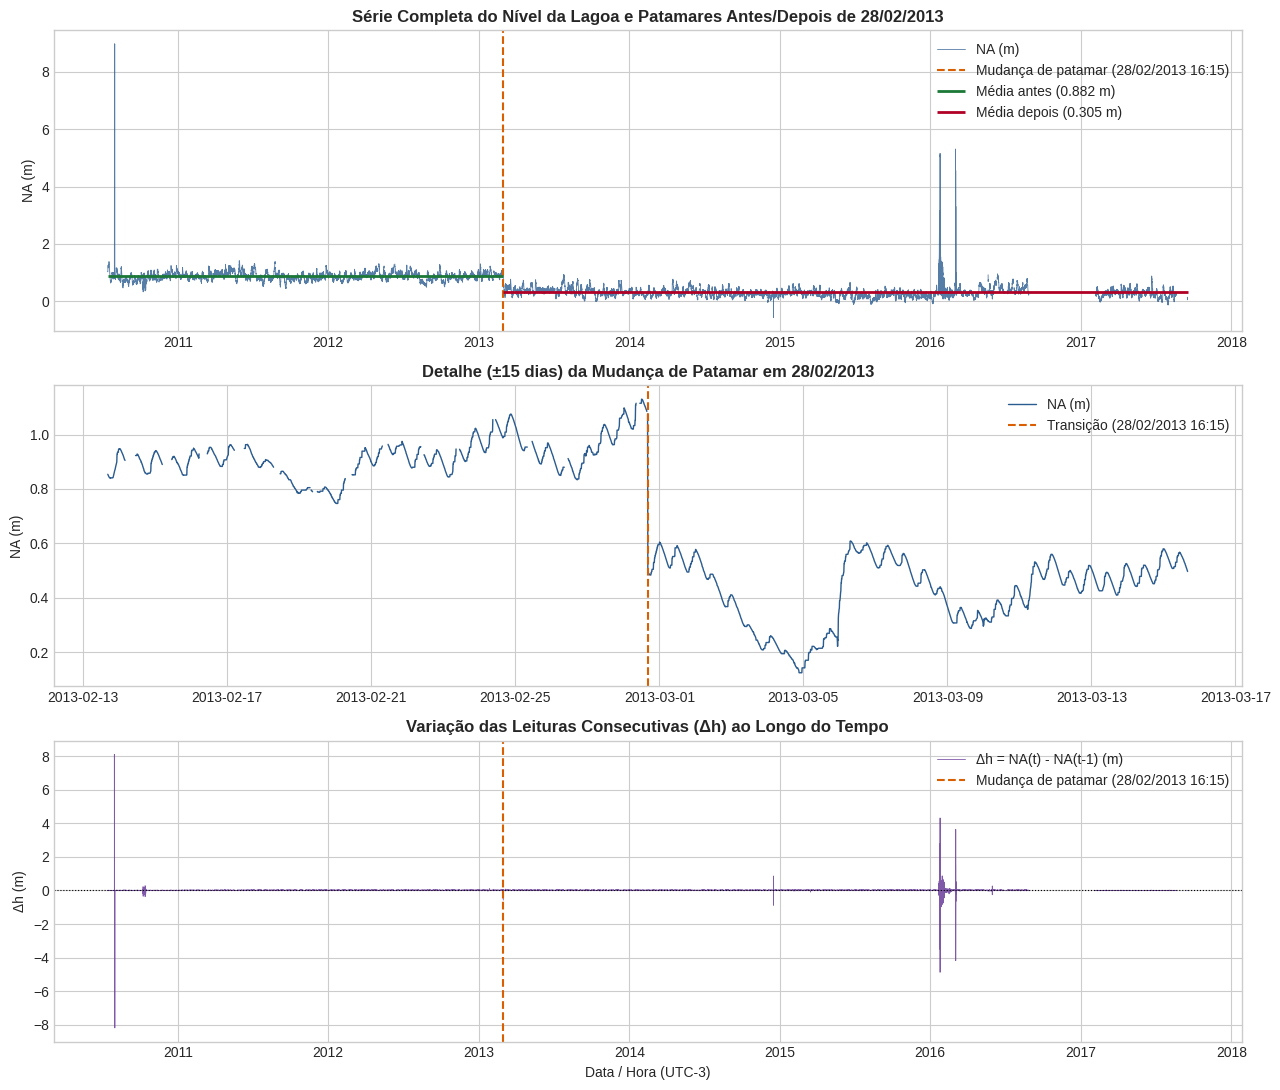

In [4]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Montar o Google Drive (ignora se já estiver montado)
try:
  from google.colab import drive

  if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
except Exception:
  pass

# 2. Carregar o banco de dados completo do nível da lagoa
pasta_lagoa = '/content/drive/MyDrive/PUC/EQM2118/LAGOA'
caminho_lagoa = os.path.join(pasta_lagoa, 'NA_Lagoa_JPA_10min_desde_20100714_1740.csv')

df_lag = pd.read_csv(caminho_lagoa)
df_lag.columns = df_lag.columns.str.strip()

# Padronizar a coluna temporal
if 'time' not in df_lag.columns:
  candidatos_tempo = [
      'datetime',
      'DateTime',
      'data_hora',
      'Data_Hora',
      'Data/Hora',
      'data',
      'Data',
      'timestamp',
      'Timestamp',
  ]
  encontrada = next((c for c in candidatos_tempo if c in df_lag.columns), None)
  if encontrada:
    df_lag = df_lag.rename(columns={encontrada: 'time'})
  elif 'Dia' in df_lag.columns and 'Hora' in df_lag.columns:
    df_lag['time'] = (
        df_lag['Dia'].astype(str).str.strip()
        + ' '
        + df_lag['Hora'].astype(str).str.strip()
    )
  else:
    df_lag = df_lag.rename(columns={df_lag.columns[0]: 'time'})

dt_iso = pd.to_datetime(df_lag['time'], errors='coerce')
dt_br = pd.to_datetime(df_lag['time'], dayfirst=True, errors='coerce')
df_lag['time'] = dt_iso.fillna(dt_br)

df_lag = (
    df_lag.dropna(subset=['time'])
    .sort_values('time')
    .drop_duplicates(subset=['time'])
    .set_index('time')
)

colunas_numericas = [
    c for c in df_lag.select_dtypes(include=[np.number]).columns
]
col_nivel = 'NA (m)' if 'NA (m)' in df_lag.columns else colunas_numericas[0]
s = pd.to_numeric(df_lag[col_nivel], errors='coerce').sort_index()

# Variação entre leituras consecutivas (Delta h)
delta_h = s.diff()
df_lag['delta_h_m'] = delta_h

# ==============================================================================
# 3. ANÁLISE ESPECÍFICA DA MUDANÇA DE PATAMAR EM 28/02/2013 16:15:00
# ==============================================================================
data_degrau = pd.Timestamp('2013-02-28 16:15:00')
df_lag['flag_degrau_20130228'] = (df_lag.index >= data_degrau).astype(int)

antes = s[s.index < data_degrau].dropna()
depois = s[s.index >= data_degrau].dropna()

print('=' * 76)
print('1. ANÁLISE DE MUDANÇA DE PATAMAR — EVENTO 28/02/2013 16:15:00')
print('=' * 76)
print(
    f'Período ANTES  (< {data_degrau}): '
    f'n = {len(antes)} | Média = {antes.mean():.4f} m | Mediana = {antes.median():.4f} m | '
    f'DP = {antes.std():.4f} m | Mín = {antes.min():.4f} m | Máx = {antes.max():.4f} m'
)
print(
    f'Período DEPOIS (>= {data_degrau}): '
    f'n = {len(depois)} | Média = {depois.mean():.4f} m | Mediana = {depois.median():.4f} m | '
    f'DP = {depois.std():.4f} m | Mín = {depois.min():.4f} m | Máx = {depois.max():.4f} m'
)
print(
    f'• Deslocamento na média   (Depois - Antes):'
    f' {depois.mean() - antes.mean():+.4f} m'
)
print(
    f'• Deslocamento na mediana (Depois - Antes):'
    f' {depois.median() - antes.median():+.4f} m\n'
)

# ==============================================================================
# 4. VARREDURA AUTOMÁTICA DE OUTRAS POSSÍVEIS MUDANÇAS DE PATAMAR NA SÉRIE
# ==============================================================================
s_10min = s.resample('10min').median()
janela_24h = 144  # 144 passos de 10 min = 24 horas

med_24h_antes = s_10min.shift(1).rolling(window=janela_24h, min_periods=72).median()
med_24h_depois = (
    s_10min.iloc[::-1]
    .shift(1)
    .rolling(window=janela_24h, min_periods=72)
    .median()
    .iloc[::-1]
)

degrau_24h = med_24h_depois - med_24h_antes
limiar_degrau = 0.35

candidatos_degrau = degrau_24h[degrau_24h.abs() >= limiar_degrau].dropna()

print('=' * 76)
print(
    '2. VARREDURA DE DEGRAUS PERSISTENTES (BLOCOS DE 24H ANTES VS. 24H DEPOIS)'
)
print('=' * 76)
if not candidatos_degrau.empty:
  grupo_d = (
      candidatos_degrau.index.to_series().diff() > pd.Timedelta(hours=12)
  ).cumsum()
  resumo_degraus = []
  for _, grp in candidatos_degrau.groupby(grupo_d):
    ts_pico = grp.abs().idxmax()
    resumo_degraus.append({
        'data_transicao_aprox': ts_pico,
        'mediana_24h_antes_m': round(med_24h_antes.loc[ts_pico], 4),
        'mediana_24h_depois_m': round(med_24h_depois.loc[ts_pico], 4),
        'deslocamento_m': round(grp.loc[ts_pico], 4),
    })
  df_degraus = pd.DataFrame(resumo_degraus)
  print(df_degraus.to_string(index=False))
else:
  print(
      'Nenhum degrau persistente >= 0,35 m detectado na comparação de 24h.'
  )

# ==============================================================================
# 5. COMPARAÇÃO ANUAL PARA VISUALIZAR OS PATAMARES AO LONGO DO TEMPO
# ==============================================================================
resumo_anual = (
    df_lag.groupby(df_lag.index.year)[col_nivel]
    .agg(
        registros='count',
        media='mean',
        mediana='median',
        desvio_padrao='std',
        minimo='min',
        maximo='max',
    )
    .round(4)
)

print('\n' + '=' * 76)
print('3. ESTATÍSTICAS ANUAIS DO NÍVEL DA LAGOA (IDENTIFICAÇÃO DE PATAMARES)')
print('=' * 76)
print(resumo_anual.to_string())
print('=' * 76 + '\n')

# ==============================================================================
# 6. VISUALIZAÇÃO GRÁFICA DA MUDANÇA DE PATAMAR E VARIAÇÃO DAS LEITURAS
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(3, 1, figsize=(13, 11))

# Gráfico 1: Série completa + linha vertical da mudança de patamar + médias por regime
axes[0].plot(
    s.index, s.values, color='#2b5c8f', linewidth=0.6, alpha=0.8, label=col_nivel
)
axes[0].axvline(
    data_degrau,
    color='#d95f02',
    linestyle='--',
    linewidth=1.5,
    label='Mudança de patamar (28/02/2013 16:15)',
)
axes[0].hlines(
    antes.mean(),
    xmin=antes.index.min(),
    xmax=data_degrau,
    color='#1b7837',
    linestyle='-',
    linewidth=2.0,
    label=f'Média antes ({antes.mean():.3f} m)',
)
axes[0].hlines(
    depois.mean(),
    xmin=data_degrau,
    xmax=depois.index.max(),
    color='#b10026',
    linestyle='-',
    linewidth=2.0,
    label=f'Média depois ({depois.mean():.3f} m)',
)
axes[0].set_title(
    'Série Completa do Nível da Lagoa e Patamares Antes/Depois de 28/02/2013',
    fontweight='bold',
)
axes[0].set_ylabel(col_nivel)
axes[0].legend(loc='upper right')

# Gráfico 2: Zoom de 15 dias antes e 15 dias depois de 28/02/2013
ini_zoom = data_degrau - pd.Timedelta(days=15)
fim_zoom = data_degrau + pd.Timedelta(days=15)
trecho_zoom = s.loc[ini_zoom:fim_zoom]

axes[1].plot(
    trecho_zoom.index,
    trecho_zoom.values,
    color='#2b5c8f',
    linewidth=1.0,
    label=col_nivel,
)
axes[1].axvline(
    data_degrau,
    color='#d95f02',
    linestyle='--',
    linewidth=1.5,
    label='Transição (28/02/2013 16:15)',
)
axes[1].set_title(
    'Detalhe (±15 dias) da Mudança de Patamar em 28/02/2013',
    fontweight='bold',
)
axes[1].set_ylabel(col_nivel)
axes[1].legend(loc='upper right')

# Gráfico 3: Variação das leituras consecutivas (Delta h = NA_t - NA_{t-1}) ao longo do tempo
axes[2].plot(
    delta_h.index,
    delta_h.values,
    color='#6a3d9a',
    linewidth=0.6,
    alpha=0.85,
    label='Δh = NA(t) - NA(t-1) (m)',
)
axes[2].axhline(0, color='black', linewidth=0.8, linestyle=':')
axes[2].axvline(
    data_degrau,
    color='#d95f02',
    linestyle='--',
    linewidth=1.5,
    label='Mudança de patamar (28/02/2013 16:15)',
)
axes[2].set_title(
    'Variação das Leituras Consecutivas (Δh) ao Longo do Tempo',
    fontweight='bold',
)
axes[2].set_xlabel('Data / Hora (UTC-3)')
axes[2].set_ylabel('Δh (m)')
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()

### *1.7.4 Divisão do banco de dados em 2 etapas - antes e depois da mudança de patamar*

In [6]:
import os
import numpy as np
import pandas as pd

# 1. Montar o Google Drive (ignora se já estiver montado)
try:
  from google.colab import drive

  if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
except Exception:
  pass

# 2. Caminhos de entrada (série consolidada em 10 min) e saída (dois períodos)
pasta_lagoa = '/content/drive/MyDrive/PUC/EQM2118/LAGOA'
caminho_10min = os.path.join(
    pasta_lagoa, 'NA_Lagoa_JPA_10min_desde_20100714_1740.csv'
)
caminho_bruto = os.path.join(pasta_lagoa, 'NA_Lagoa JPA-Rede Sarah_2010-2017.csv')

caminho_parte1 = os.path.join(
    pasta_lagoa, 'NA_Lagoa_JPA_10min_parte1_20100714_1740_a_20130228_1610.csv'
)
caminho_parte2 = os.path.join(
    pasta_lagoa, 'NA_Lagoa_JPA_10min_parte2_20130228_1620_ate_fim.csv'
)

# 3. Carregar a série na grade de 10 min (ou gerar na hora caso ainda não exista)
if os.path.exists(caminho_10min):
  df_10 = pd.read_csv(caminho_10min)
  df_10.columns = df_10.columns.str.strip()
  col_tempo = 'time' if 'time' in df_10.columns else df_10.columns[0]
  df_10[col_tempo] = pd.to_datetime(df_10[col_tempo], errors='coerce')
  df_10 = (
      df_10.dropna(subset=[col_tempo])
      .sort_values(col_tempo)
      .drop_duplicates(subset=[col_tempo])
      .set_index(col_tempo)
  )
  col_nivel = 'NA (m)' if 'NA (m)' in df_10.columns else df_10.columns[0]
  s_10 = pd.to_numeric(df_10[col_nivel], errors='coerce')
else:
  df_raw = pd.read_csv(caminho_bruto)
  df_raw.columns = df_raw.columns.str.strip()
  col_tempo = 'time' if 'time' in df_raw.columns else df_raw.columns[0]
  dt_iso = pd.to_datetime(df_raw[col_tempo], errors='coerce')
  dt_br = pd.to_datetime(df_raw[col_tempo], dayfirst=True, errors='coerce')
  df_raw[col_tempo] = dt_iso.fillna(dt_br)
  df_raw = (
      df_raw.dropna(subset=[col_tempo])
      .sort_values(col_tempo)
      .drop_duplicates(subset=[col_tempo])
      .set_index(col_tempo)
  )
  col_nivel = 'NA (m)' if 'NA (m)' in df_raw.columns else df_raw.columns[0]
  s_raw = pd.to_numeric(df_raw[col_nivel], errors='coerce')

  data_inicio = pd.Timestamp('2010-07-14 17:40:00')
  s_rec = s_raw[s_raw.index >= data_inicio]
  mask_10 = (s_rec.index.minute % 10 == 0) & (s_rec.index.second == 0)
  s_rec = s_rec[mask_10]
  grade_10 = pd.date_range(
      start=data_inicio,
      end=s_rec.index.max().floor('10min'),
      freq='10min',
  )
  s_10 = s_rec.reindex(grade_10)

s_10 = s_10.sort_index()
s_10.index.name = 'time'

# 4. Definir marcos temporais exatos da divisão
inicio_p1 = pd.Timestamp('2010-07-14 17:40:00')
fim_p1 = pd.Timestamp('2013-02-28 16:10:00')
inicio_p2 = pd.Timestamp('2013-02-28 16:20:00')

ultimo_valido = s_10.dropna().index.max()
fim_serie = ultimo_valido if pd.notna(ultimo_valido) else s_10.index.max()
fim_p2 = fim_serie.floor('10min')

# --- PERÍODO 1: 14/07/2010 17:40:00 até 28/02/2013 16:10:00 ---
grade_p1 = pd.date_range(start=inicio_p1, end=fim_p1, freq='10min')
df_p1 = s_10.reindex(grade_p1).to_frame(name=col_nivel)
df_p1.index.name = 'time'

# --- PERÍODO 2: 28/02/2013 16:20:00 até a última leitura registrada ---
grade_p2 = pd.date_range(start=inicio_p2, end=fim_p2, freq='10min')
df_p2 = s_10.reindex(grade_p2).to_frame(name=col_nivel)
df_p2.index.name = 'time'

# 5. Salvar os dois arquivos CSV
df_p1.to_csv(caminho_parte1)
df_p2.to_csv(caminho_parte2)

# 6. Conferência no console
print('=== RESUMO DA DIVISÃO EM DOIS PERÍODOS (GRADE 10 MIN) ===\n')

print('PERÍODO 1:')
print(f'• Arquivo:         {os.path.basename(caminho_parte1)}')
print(f'• Início / Fim:    {df_p1.index.min()}  -->  {df_p1.index.max()}')
print(
    f'• Total na grade:  {len(df_p1)} | Válidos: {df_p1[col_nivel].notna().sum()}'
    f' | NaNs: {df_p1[col_nivel].isna().sum()}'
)
print(
    f'• Média / Mediana: {df_p1[col_nivel].mean():.4f} m /'
    f' {df_p1[col_nivel].median():.4f} m\n'
)

print('PERÍODO 2:')
print(f'• Arquivo:         {os.path.basename(caminho_parte2)}')
print(f'• Início / Fim:    {df_p2.index.min()}  -->  {df_p2.index.max()}')
print(
    f'• Total na grade:  {len(df_p2)} | Válidos: {df_p2[col_nivel].notna().sum()}'
    f' | NaNs: {df_p2[col_nivel].isna().sum()}'
)
print(
    f'• Média / Mediana: {df_p2[col_nivel].mean():.4f} m /'
    f' {df_p2[col_nivel].median():.4f} m'
)

=== RESUMO DA DIVISÃO EM DOIS PERÍODOS (GRADE 10 MIN) ===

PERÍODO 1:
• Arquivo:         NA_Lagoa_JPA_10min_parte1_20100714_1740_a_20130228_1610.csv
• Início / Fim:    2010-07-14 17:40:00  -->  2013-02-28 16:10:00
• Total na grade:  138232 | Válidos: 133266 | NaNs: 4966
• Média / Mediana: 0.8823 m / 0.8670 m

PERÍODO 2:
• Arquivo:         NA_Lagoa_JPA_10min_parte2_20130228_1620_ate_fim.csv
• Início / Fim:    2013-02-28 16:20:00  -->  2017-09-16 18:40:00
• Total na grade:  239199 | Válidos: 206204 | NaNs: 32995
• Média / Mediana: 0.3048 m / 0.2890 m


### *1.7.5 Análise dos dados da lagoa - Parte 2*

In [7]:
import os
import numpy as np
import pandas as pd

try:
  from google.colab import drive

  if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
except Exception:
  pass

pasta_lagoa = '/content/drive/MyDrive/PUC/EQM2118/LAGOA'
caminho_lagoa = os.path.join(pasta_lagoa, 'NA_Lagoa_JPA_10min_parte2_20130228_1620_ate_fim.csv')

df_lag = pd.read_csv(caminho_lagoa)
df_lag.columns = df_lag.columns.str.strip()

print('Colunas disponíveis no CSV:', df_lag.columns.tolist())
print(df_lag.head(3))

# 1. Detectar ou construir a coluna 'time'
if 'time' not in df_lag.columns:
  candidatos_tempo = [
      'datetime',
      'DateTime',
      'data_hora',
      'Data_Hora',
      'Data/Hora',
      'data',
      'Data',
      'timestamp',
      'Timestamp',
  ]
  encontrada = next((c for c in candidatos_tempo if c in df_lag.columns), None)

  if encontrada:
    df_lag = df_lag.rename(columns={encontrada: 'time'})
  elif 'Dia' in df_lag.columns and 'Hora' in df_lag.columns:
    df_lag['time'] = (
        df_lag['Dia'].astype(str).str.strip()
        + ' '
        + df_lag['Hora'].astype(str).str.strip()
    )
  else:
    # Fallback: usa a primeira coluna caso não reconheça pelo nome
    primeira_col = df_lag.columns[0]
    print(
        'Aviso: coluna de tempo padrão não encontrada pelo nome; usando a'
        f" primeira coluna ('{primeira_col}') como 'time'."
    )
    df_lag = df_lag.rename(columns={primeira_col: 'time'})

# Converter 'time' para datetime (suporta formato DD/MM/YYYY ou AAAA-MM-DD)
dt_iso = pd.to_datetime(df_lag['time'], errors='coerce')
dt_br = pd.to_datetime(df_lag['time'], dayfirst=True, errors='coerce')
df_lag['time'] = dt_iso.fillna(dt_br)

df_lag = (
    df_lag.dropna(subset=['time'])
    .sort_values('time')
    .drop_duplicates(subset=['time'])
    .set_index('time')
)

# 2. Detectar a coluna numérica de nível da lagoa (ajuste col_nivel se houver mais de uma)
colunas_numericas = [
    c for c in df_lag.select_dtypes(include=[np.number]).columns
]
col_nivel = colunas_numericas[0] if colunas_numericas else df_lag.columns[0]
print(f"\nColuna de nível selecionada para auditoria: '{col_nivel}'")

s = pd.to_numeric(df_lag[col_nivel], errors='coerce')

print('\n=== 1. INTEGRIDADE E AUSÊNCIAS ===')
print(
    f'Total de registros: {len(df_lag)} | Início: {df_lag.index.min()} | Fim:'
    f' {df_lag.index.max()}'
)
diffs = df_lag.index.to_series().diff().dropna()
if not diffs.empty:
  print('Frequências temporais mais comuns:')
  print(diffs.value_counts().head(5))
print(
    f'NaNs em {col_nivel}: {s.isna().sum()} ({100 * s.isna().mean():.2f}%)'
)

print('\n=== 2. ESTATÍSTICAS DESCRITIVAS ===')
print(s.describe())

print('\n=== 3. OUTLIERS POR IQR (3x) ===')
q1, q3 = s.quantile(0.25), s.quantile(0.75)
iqr = q3 - q1
lim_inf, lim_sup = q1 - 3.0 * iqr, q3 + 3.0 * iqr
out_iqr = df_lag[(s < lim_inf) | (s > lim_sup)]
print(f'Limites [{lim_inf:.4f}, {lim_sup:.4f}] | Qtde fora: {len(out_iqr)}')
if not out_iqr.empty:
  print(out_iqr[[col_nivel]].head(15))

print('\n=== 4. MAIORES VARIAÇÕES CONSECUTIVAS (|dh|) ===')
delta = s.diff().abs()
lim_d = delta.quantile(0.999)
out_d = (
    df_lag[delta > lim_d]
    .assign(delta_h=delta[delta > lim_d])
    .sort_values('delta_h', ascending=False)
)
print(f'Percentil 99,9% de |dh|: {lim_d:.4f} | Qtde acima: {len(out_d)}')
print(out_d[[col_nivel, 'delta_h']].head(15))

print('\n=== 5. RESUMO ANUAL ===')
resumo = df_lag.groupby(df_lag.index.year)[col_nivel].agg(
    contagem='count',
    nans=lambda x: pd.to_numeric(x, errors='coerce').isna().sum(),
    media='mean',
    minimo='min',
    maximo='max',
)
print(resumo.round(3))

Colunas disponíveis no CSV: ['time', 'NA (m)']
                  time  NA (m)
0  2013-02-28 16:20:00   0.501
1  2013-02-28 16:30:00   0.498
2  2013-02-28 16:40:00   0.493

Coluna de nível selecionada para auditoria: 'NA (m)'

=== 1. INTEGRIDADE E AUSÊNCIAS ===
Total de registros: 239199 | Início: 2013-02-28 16:20:00 | Fim: 2017-09-16 18:40:00
Frequências temporais mais comuns:
time
0 days 00:10:00    239198
Name: count, dtype: int64
NaNs em NA (m): 32995 (13.79%)

=== 2. ESTATÍSTICAS DESCRITIVAS ===
count    206204.000000
mean          0.304836
std           0.179832
min          -0.573000
25%           0.205000
50%           0.289000
75%           0.381000
max           5.311000
Name: NA (m), dtype: float64

=== 3. OUTLIERS POR IQR (3x) ===
Limites [-0.3230, 0.9090] | Qtde fora: 1334
                     NA (m)
time                       
2013-07-25 09:50:00   0.920
2013-07-25 10:00:00   0.920
2013-07-25 10:10:00   0.920
2013-07-25 10:20:00   0.920
2013-07-25 10:30:00   0.920
2013-07-

/tmp/ipykernel_579/3504091245.py:56: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  dt_br = pd.to_datetime(df_lag['time'], dayfirst=True, errors='coerce')


### *1.7.6 Análise das mudanças abruptas a partir do cruzamento com dados de precipitação*

In [13]:
import os
import numpy as np
import pandas as pd

# 1. Montar o Google Drive (ignora se já estiver montado)
try:
  from google.colab import drive

  if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
except Exception:
  pass

# 2. Caminhos dos ficheiros
pasta_lagoa = '/content/drive/MyDrive/PUC/EQM2118/LAGOA'
pasta_chuva = '/content/drive/MyDrive/PUC/EQM2118/CHUVA_2010_2026'

caminho_lagoa = os.path.join(
    pasta_lagoa, 'NA_Lagoa_JPA_10min_parte2_20130228_1620_ate_fim.csv'
)
caminho_chuva = os.path.join(
    pasta_chuva, 'banco_precipitacoes_completo_2010_2026_NaN_preenchido.csv'
)

caminho_diagnostico = os.path.join(
    pasta_lagoa, 'diagnostico_abruptas_x_precipitacao_parte2.csv'
)
caminho_lagoa_cruzada = os.path.join(
    pasta_lagoa,
    'NA_Lagoa_JPA_10min_parte2_20130228_1620_ate_fim_cruzado_chuva.csv',
)


def parse_datas_seguro(serie_dt):
  """Converte datas ISO ou formato dia/mês/ano sem avisos desnecessários."""
  s_str = serie_dt.astype(str).str.strip()
  dt_iso = pd.to_datetime(s_str, format='%Y-%m-%d %H:%M:%S', errors='coerce')
  faltantes = dt_iso.isna()
  if faltantes.any():
    dt_outros = pd.to_datetime(
        s_str[faltantes], dayfirst=True, format='mixed', errors='coerce'
    )
    dt_iso = dt_iso.fillna(dt_outros)
  return dt_iso


# 3. Carregar dados da lagoa (Parte 2)
df_lag = pd.read_csv(caminho_lagoa)
df_lag.columns = [c.strip() for c in df_lag.columns]
col_t_lag = 'time' if 'time' in df_lag.columns else df_lag.columns[0]
df_lag[col_t_lag] = parse_datas_seguro(df_lag[col_t_lag])
df_lag = (
    df_lag.dropna(subset=[col_t_lag])
    .sort_values(col_t_lag)
    .drop_duplicates(subset=[col_t_lag])
    .set_index(col_t_lag)
)

col_nivel = 'NA (m)' if 'NA (m)' in df_lag.columns else df_lag.columns[0]
s_lag = pd.to_numeric(df_lag[col_nivel], errors='coerce')

# Garante grelha contínua de 10 minutos
grade_10min = pd.date_range(
    start=s_lag.index.min(), end=s_lag.index.max(), freq='10min'
)
s_lag = s_lag.reindex(grade_10min)

# 4. Carregar banco de precipitações com NaNs já preenchidos
if not os.path.exists(caminho_chuva):
  raise FileNotFoundError(
      f'Ficheiro de precipitação não encontrado em:\n{caminho_chuva}'
  )

df_chuva = pd.read_csv(caminho_chuva)
df_chuva.columns = [c.strip() for c in df_chuva.columns]

cols_low_c = {c.lower(): c for c in df_chuva.columns}
col_t_chuva = next(
    (
        cols_low_c[k]
        for k in ['datetime', 'data_hora', 'data/hora', 'timestamp', 'date']
        if k in cols_low_c
    ),
    df_chuva.columns[0],
)
df_chuva['_dt'] = parse_datas_seguro(df_chuva[col_t_chuva])

col_p10 = next(
    (
        c
        for c in df_chuva.columns
        if any(k in c.lower() for k in ['10min', '10_min', '10 min', 'precip_10'])
    ),
    None,
)
col_p1h = next(
    (
        c
        for c in df_chuva.columns
        if any(k in c.lower() for k in ['1h', '01h', '01 h', '1_h', 'precip_1h'])
    ),
    None,
)

df_chuva_idx = (
    df_chuva.dropna(subset=['_dt'])
    .sort_values('_dt')
    .drop_duplicates(subset=['_dt'], keep='last')
    .set_index('_dt')
)

p_10 = (
    pd.to_numeric(df_chuva_idx[col_p10], errors='coerce').reindex(grade_10min)
    if col_p10
    else pd.Series(np.nan, index=grade_10min)
)

# Usa a coluna de 1h preenchida e complementa apenas eventuais falhas pela soma de 6 passos (1h)
p_1h_calc = p_10.rolling(window=6, min_periods=1).sum()
if col_p1h:
  p_1h = (
      pd.to_numeric(df_chuva_idx[col_p1h], errors='coerce')
      .reindex(grade_10min)
      .fillna(p_1h_calc)
  )
else:
  p_1h = p_1h_calc

# Acumulados antecedentes (3h = 18 passos, 6h = 36 passos, 24h = 144 passos)
p_3h = p_10.rolling(window=18, min_periods=1).sum()
p_6h = p_10.rolling(window=36, min_periods=1).sum()
p_24h = p_10.rolling(window=144, min_periods=1).sum()

# 5. Identificar mudanças abruptas (janela local de +-6h)
janela = 36
med_antes = s_lag.shift(1).rolling(window=janela, min_periods=6).median()
med_depois = (
    s_lag.iloc[::-1]
    .shift(1)
    .rolling(window=janela, min_periods=6)
    .median()
    .iloc[::-1]
)
med_vizinha = pd.concat([med_antes, med_depois], axis=1).median(axis=1)

salto_borda = (med_depois - med_antes).abs()
desvio_local = (s_lag - med_vizinha).abs()
dh = s_lag.diff()

lim_desvio_local = 0.25
lim_salto_borda = 0.15
lim_dh_extremo = 0.2020

flag_abrupta_local = (desvio_local >= lim_desvio_local) & (
    salto_borda >= lim_salto_borda
)
flag_spike_isolado = (
    (desvio_local >= lim_desvio_local)
    & (s_lag.shift(1).sub(s_lag).abs() >= lim_dh_extremo)
    & (s_lag.shift(-1).sub(s_lag).abs() >= lim_dh_extremo)
)
flag_abrupta = (flag_abrupta_local | flag_spike_isolado).fillna(False)

# 6. Agrupar episódios e cruzar com chuva antecedente/concomitante
idx_flag = s_lag.index[flag_abrupta]
linhas_diag = []

if len(idx_flag) > 0:
  serie_flag = idx_flag.to_series()
  grupos = (serie_flag.diff() > pd.Timedelta(minutes=20)).cumsum()
  for _, grp in serie_flag.groupby(grupos):
    grp_idx = grp.index
    t_ini = grp_idx.min()
    t_fim = grp_idx.max()
    janela_chuva_ini = t_ini - pd.Timedelta(hours=6)
    chuva_antes_6h = p_10.loc[janela_chuva_ini:t_ini].sum(min_count=1)
    chuva_durante_ep = p_10.loc[t_ini:t_fim].sum(min_count=1)
    p1h_max_janela = p_1h.loc[janela_chuva_ini:t_fim].max()
    p24h_no_inicio = p_24h.loc[t_ini]

    chuva_total_janela = (
        0.0 if pd.isna(chuva_antes_6h) else chuva_antes_6h
    ) + (0.0 if pd.isna(chuva_durante_ep) else chuva_durante_ep)
    classificacao = (
        'SEM CHUVA RELEVANTE (<=0.5mm)'
        if chuva_total_janela <= 0.5
        else 'COM CHUVA ASSOCIADA (>0.5mm)'
    )

    sub_na = s_lag.loc[t_ini:t_fim]
    linhas_diag.append({
        'inicio': t_ini,
        'fim': t_fim,
        'n_pontos': len(grp_idx),
        'na_min_m': round(sub_na.min(), 4),
        'na_max_m': round(sub_na.max(), 4),
        'desvio_max_m': round(desvio_local.loc[grp_idx].max(), 4),
        'chuva_antes_6h_mm': (
            round(chuva_antes_6h, 2) if pd.notna(chuva_antes_6h) else np.nan
        ),
        'chuva_episodio_mm': (
            round(chuva_durante_ep, 2) if pd.notna(chuva_durante_ep) else np.nan
        ),
        'p1h_max_mm': (
            round(p1h_max_janela, 2) if pd.notna(p1h_max_janela) else np.nan
        ),
        'p24h_inicio_mm': (
            round(p24h_no_inicio, 2) if pd.notna(p24h_no_inicio) else np.nan
        ),
        'classificacao': classificacao,
    })

df_diag = pd.DataFrame(linhas_diag)
df_diag.to_csv(caminho_diagnostico, index=False)

print(
    '=== CRUZAMENTO: MUDANÇAS ABRUPTAS DA LAGOA x PRECIPITAÇÃO'
    ' (NAN_PREENCHIDO) ==='
)
print(f'Base de chuva utilizada: {caminho_chuva}')
print(f'Total de episódios abruptos: {len(df_diag)}')
if not df_diag.empty:
  print(df_diag['classificacao'].value_counts())
  print('\n--- TOP 20 EPISÓDIOS POR DESVIO LOCAL ---')
  print(
      df_diag.sort_values('desvio_max_m', ascending=False)
      .head(20)
      .to_string(index=False)
  )

# 7. Marcar pontos abruptos sem chuva relevante (<= 0.5 mm em 6h antes + episódio)
sem_chuva_pts = pd.Series(False, index=grade_10min)
if not df_diag.empty:
  for _, row in df_diag[
      df_diag['classificacao'] == 'SEM CHUVA RELEVANTE (<=0.5mm)'
  ].iterrows():
    sem_chuva_pts.loc[row['inicio'] : row['fim']] = True

flag_anomalia_sem_chuva = (flag_abrupta & sem_chuva_pts).fillna(False)

df_cruzado = pd.DataFrame(index=grade_10min)
df_cruzado.index.name = 'time'
df_cruzado[col_nivel] = s_lag
df_cruzado['dh_m'] = dh.round(4)
df_cruzado['precip_10min'] = p_10.round(4)
df_cruzado['precip_1h'] = p_1h.round(4)
df_cruzado['precip_3h'] = p_3h.round(4)
df_cruzado['precip_6h'] = p_6h.round(4)
df_cruzado['precip_24h'] = p_24h.round(4)
df_cruzado['flag_abrupta'] = flag_abrupta.astype(int)
df_cruzado['flag_anomalia_sem_chuva'] = flag_anomalia_sem_chuva.astype(int)
df_cruzado['NA_sem_anomalia_sem_chuva_m'] = s_lag.mask(
    flag_anomalia_sem_chuva, np.nan
).round(4)

df_cruzado.to_csv(caminho_lagoa_cruzada)

print('\nFicheiros guardados:')
print('  • Diagnóstico dos episódios:', caminho_diagnostico)
print('  • Série cruzada com chuva:   ', caminho_lagoa_cruzada)

=== CRUZAMENTO: MUDANÇAS ABRUPTAS DA LAGOA x PRECIPITAÇÃO (NAN_PREENCHIDO) ===
Base de chuva utilizada: /content/drive/MyDrive/PUC/EQM2118/CHUVA_2010_2026/banco_precipitacoes_completo_2010_2026_NaN_preenchido.csv
Total de episódios abruptos: 36
classificacao
SEM CHUVA RELEVANTE (<=0.5mm)    31
COM CHUVA ASSOCIADA (>0.5mm)      5
Name: count, dtype: int64

--- TOP 20 EPISÓDIOS POR DESVIO LOCAL ---
             inicio                 fim  n_pontos  na_min_m  na_max_m  desvio_max_m  chuva_antes_6h_mm  chuva_episodio_mm  p1h_max_mm  p24h_inicio_mm                 classificacao
2016-03-02 12:10:00 2016-03-02 14:10:00        11     0.376     5.311        4.7060               0.00                0.0         0.0            2.40 SEM CHUVA RELEVANTE (<=0.5mm)
2016-03-02 20:20:00 2016-03-02 22:00:00         9     0.323     4.560        4.0015               0.00                0.0         0.0            0.40 SEM CHUVA RELEVANTE (<=0.5mm)
2016-01-24 15:10:00 2016-01-25 03:20:00        71     0.246 

### *1.7.7 Análise de outliers*

/tmp/ipykernel_579/2446384775.py:50: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  dt_br = pd.to_datetime(df_lag['time'], dayfirst=True, errors='coerce')


RELATÓRIO DE AUDITORIA E ANÁLISE DE OUTLIERS — NÍVEL DA LAGOA
Arquivo analisado: NA_Lagoa_JPA_10min_parte2_20130228_1620_ate_fim.csv
Coluna de nível: NA (m) | Fuso horário: UTC-3

1. INTEGRIDADE TEMPORAL E AUSÊNCIAS (NaN)
• Período da série: 2013-02-28 16:20:00 até 2017-09-16 18:40:00
• Total de registros: 239199 | Valores válidos: 206204 | NaNs: 32995 (13.79%)

2. ESTATÍSTICAS DESCRITIVAS (NA (m))
• Média: 0.3048 m | Desvio Padrão: 0.1798 m
• Mínimo: -0.5730 m | Q1 (25%): 0.2050 m | Mediana (50%): 0.2890 m | Q3 (75%): 0.3810 m | Máximo: 5.3110 m

3. DIAGNÓSTICO DE OUTLIERS (MUDANÇA ABRUPTA ANTES E DEPOIS)
• Janela local: 36 passos antes e depois (6.0 h)
• Critério: |valor - mediana_vizinhanca| >= 0.25 m e salto_borda >= 0.15 m
• Total de pontos com mudança abrupta: 194 (0.081%)
• Total de episódios contínuos agrupados: 89
• Percentil 99,9% da variação consecutiva (|dh|): 0.2020 m (206 registros acima)

4. RESUMO ANUAL DA SÉRIE
      contagem   nans  media  minimo  maximo
time         

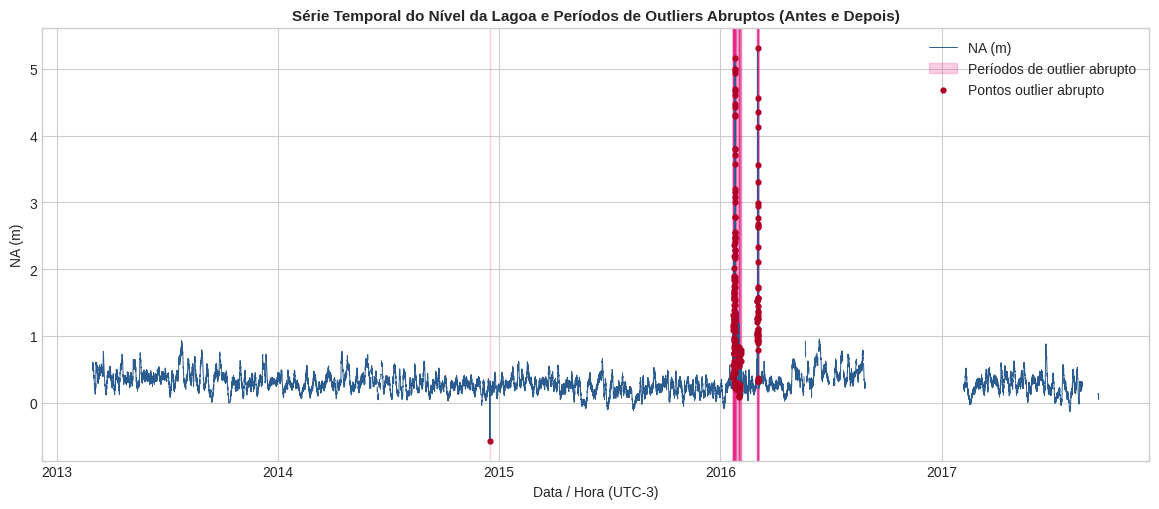

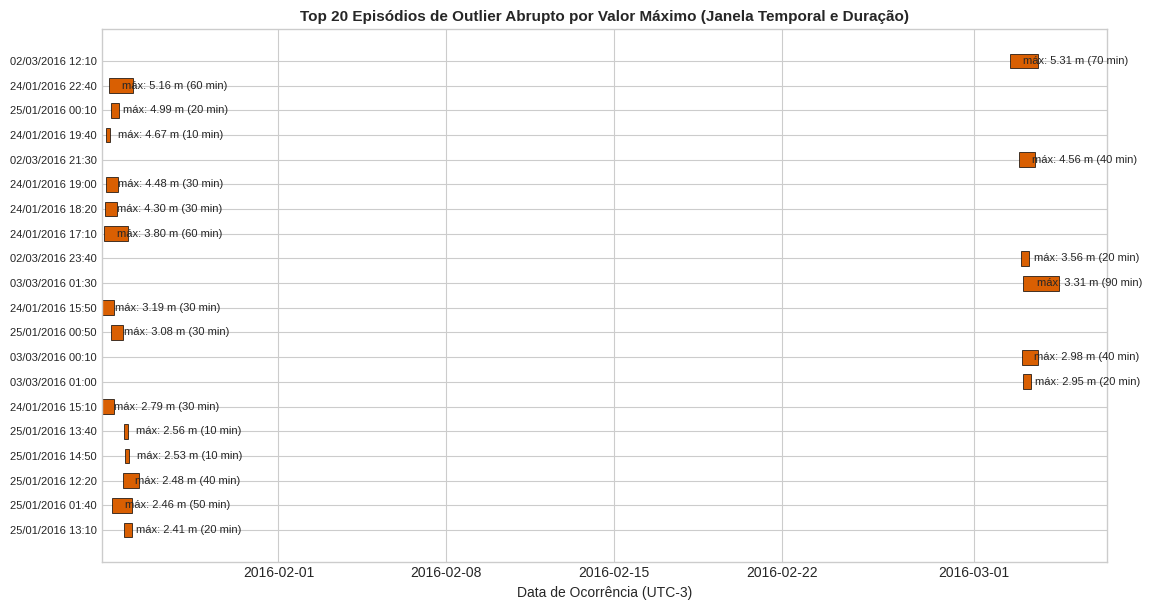

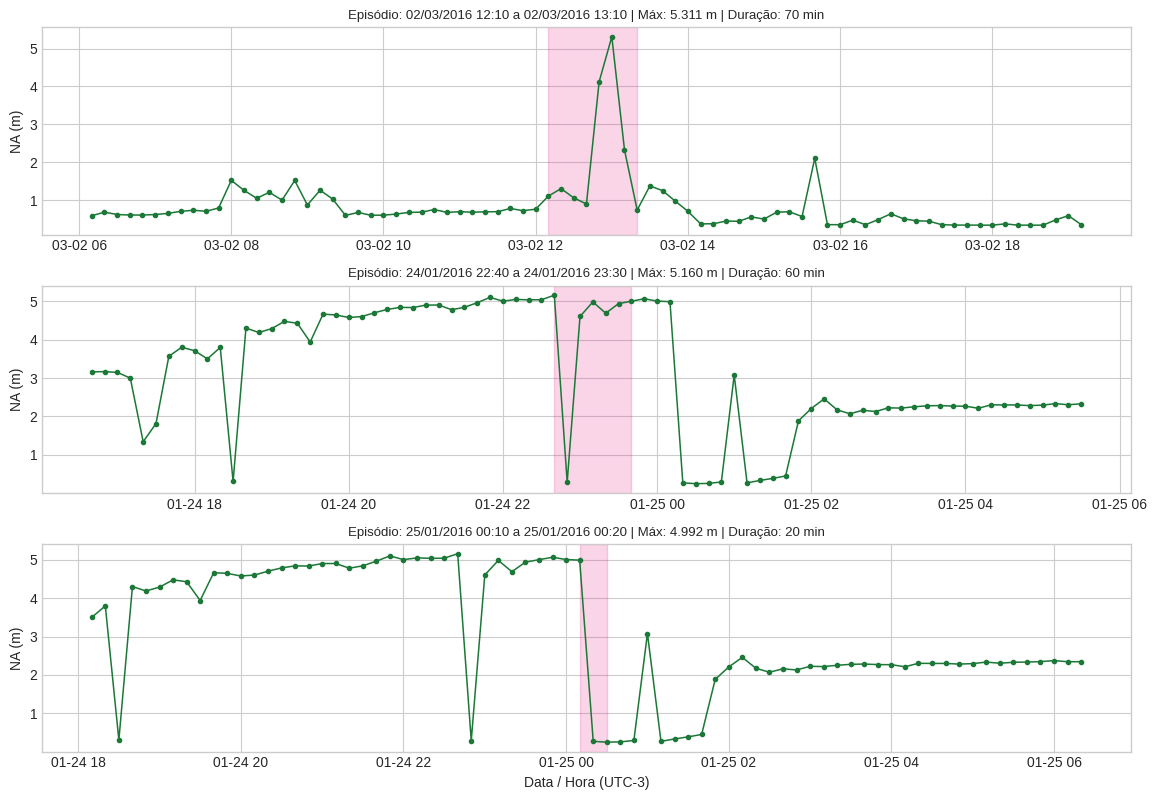

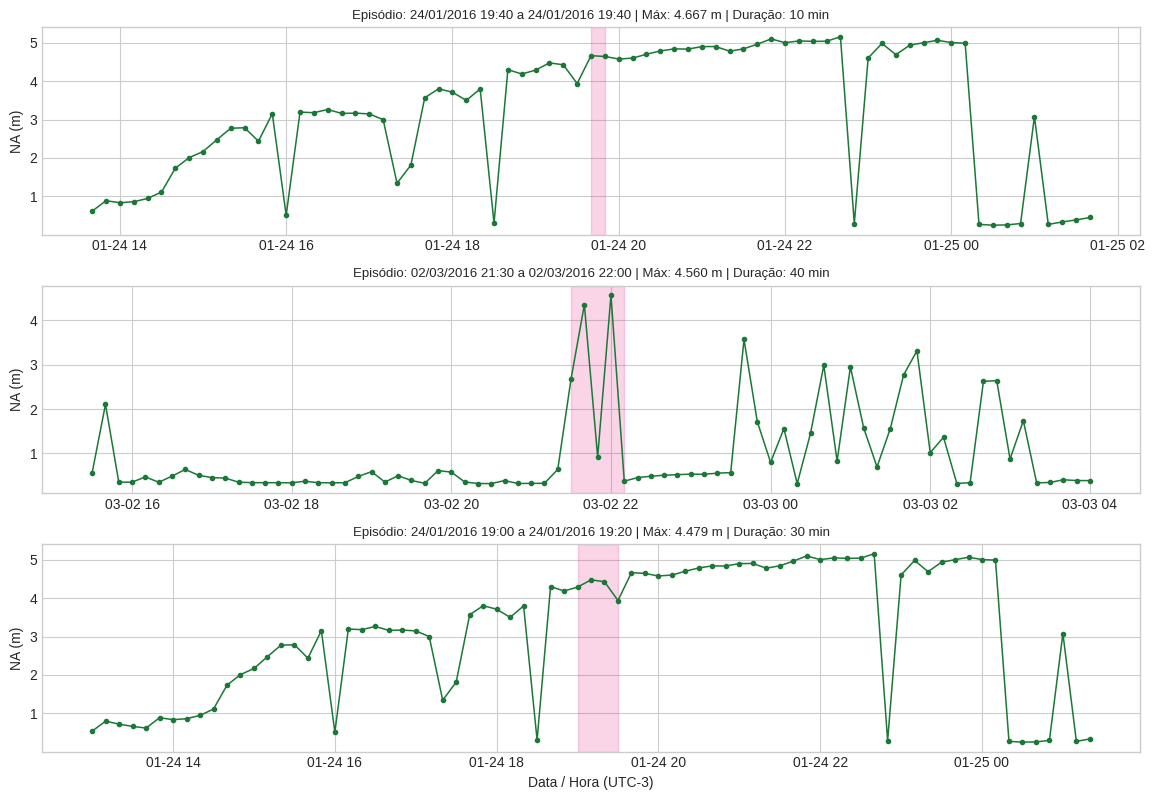

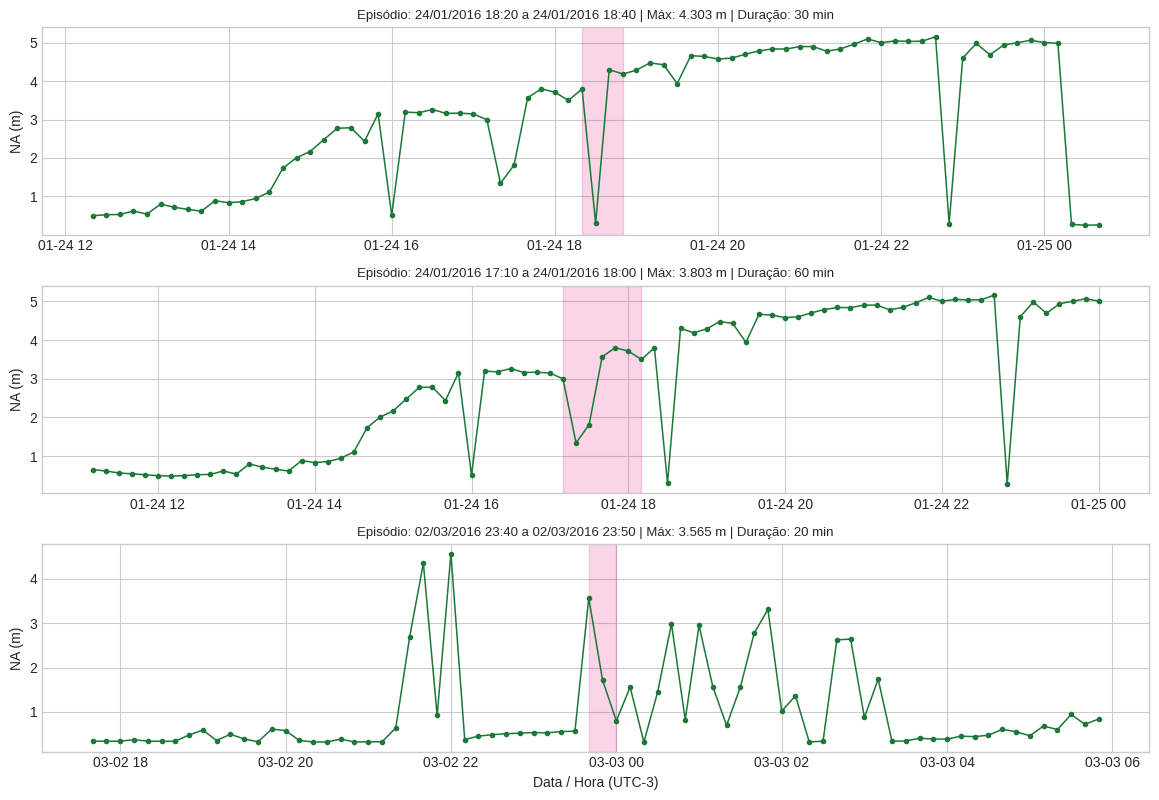

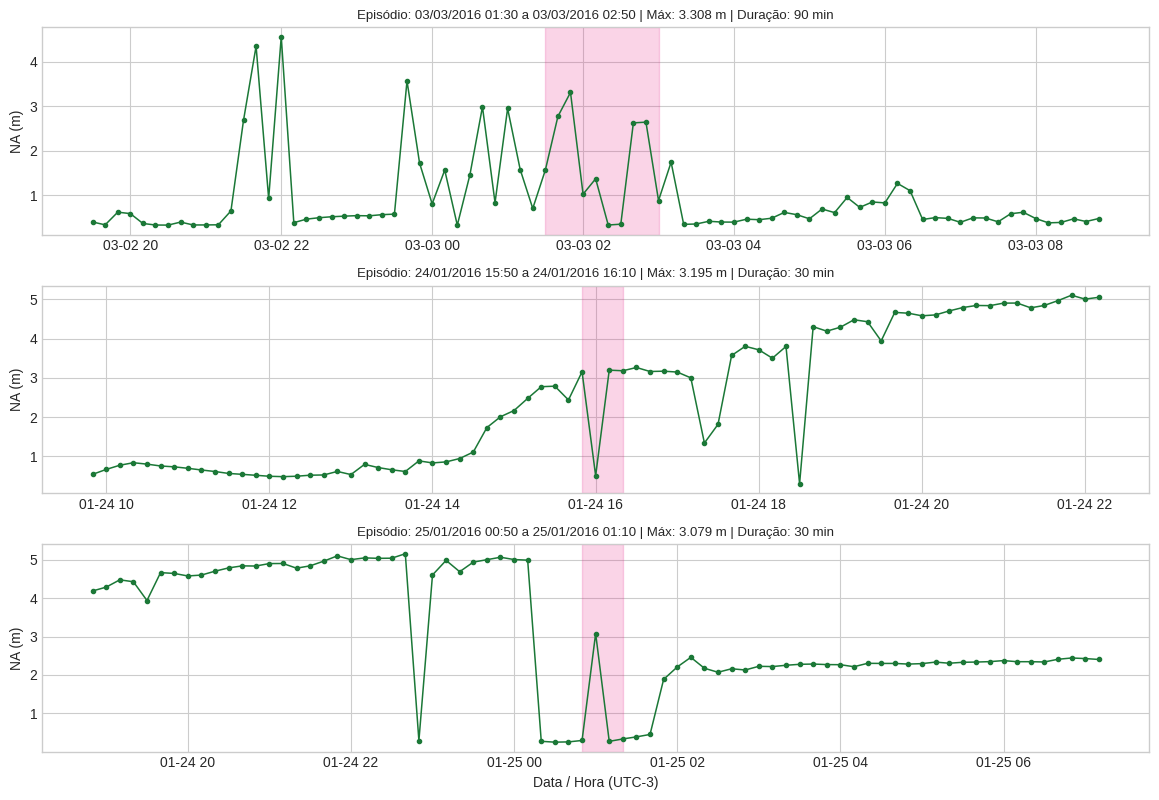

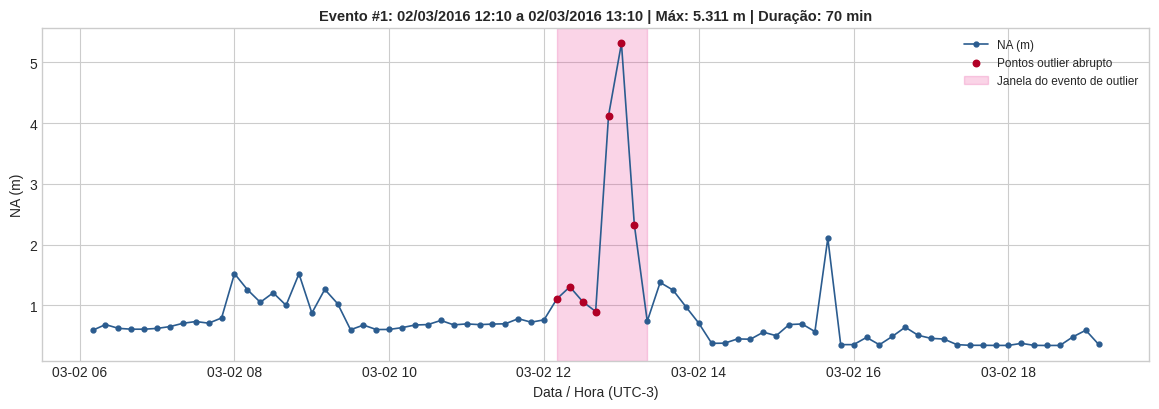

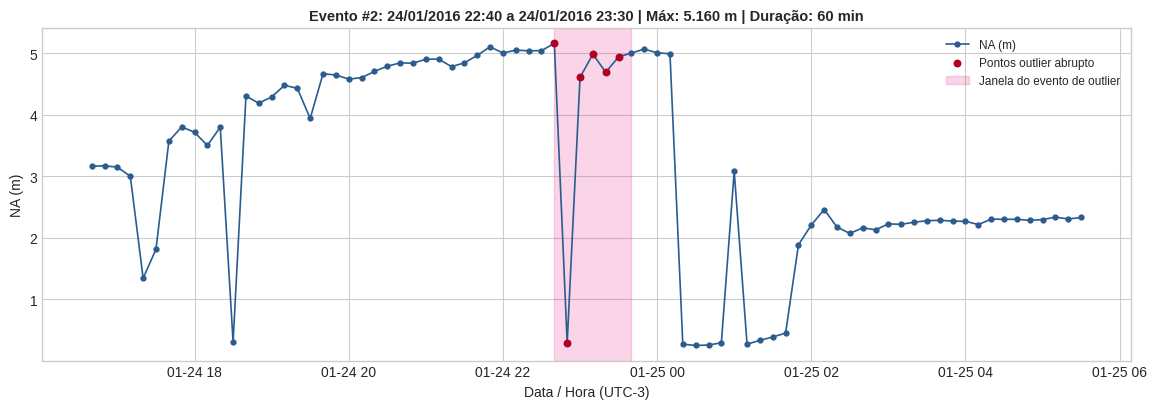

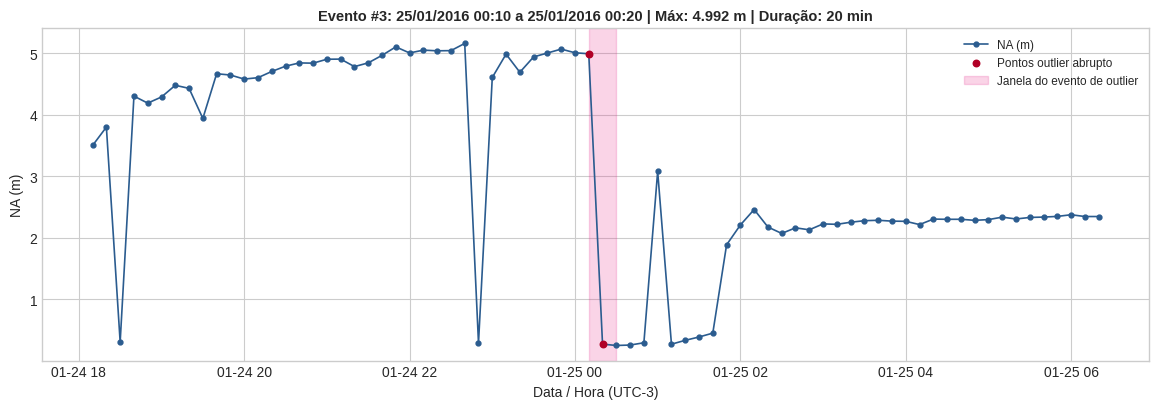

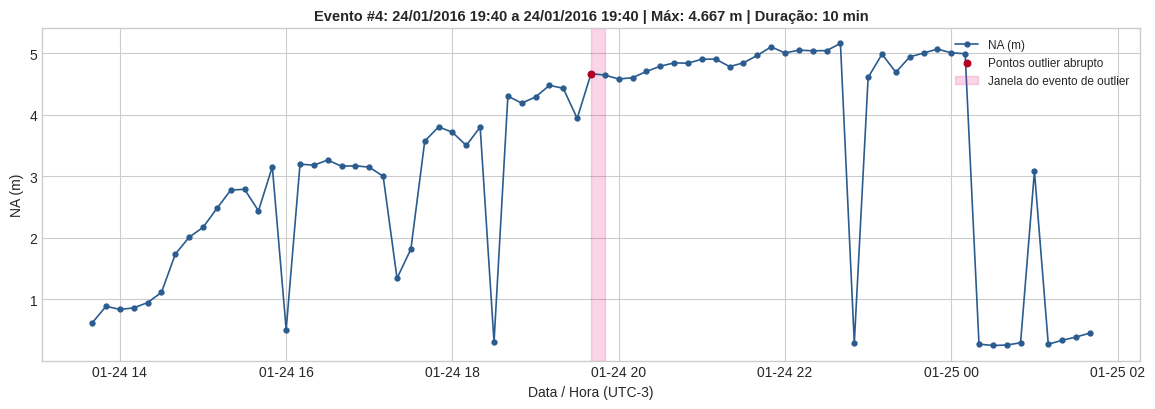

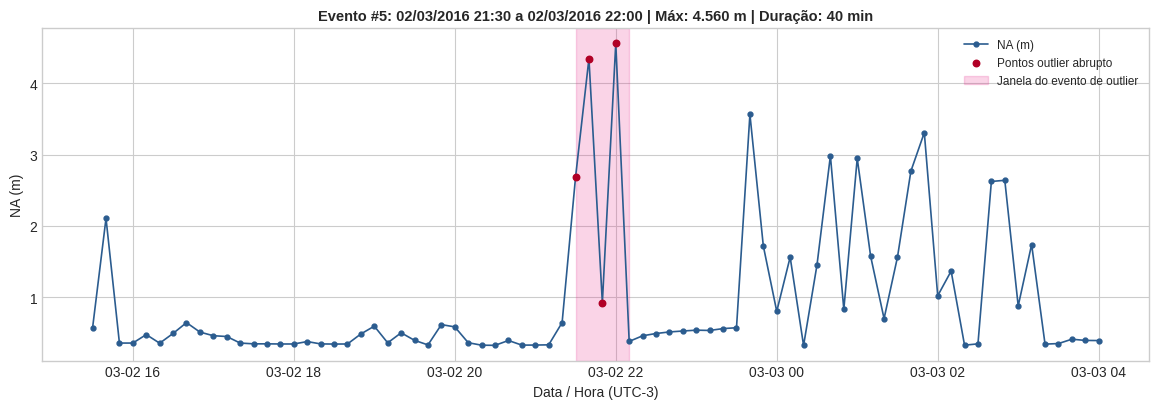

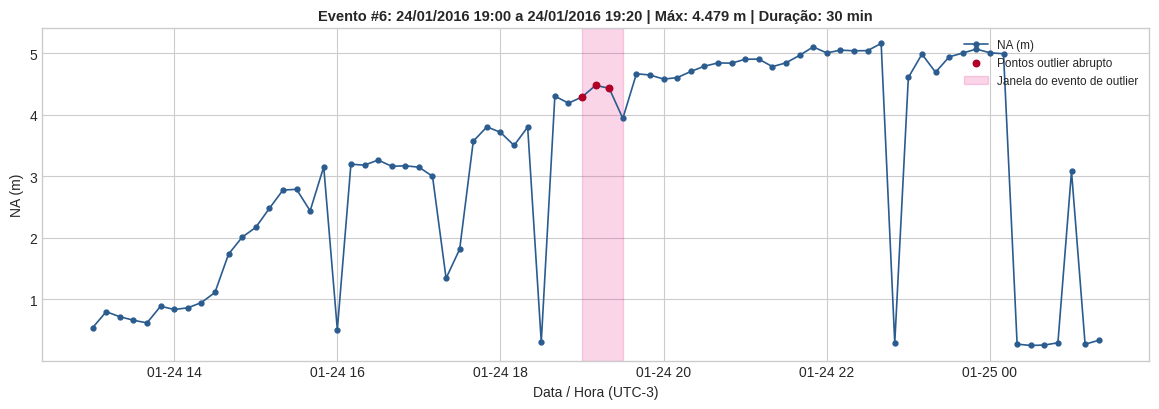

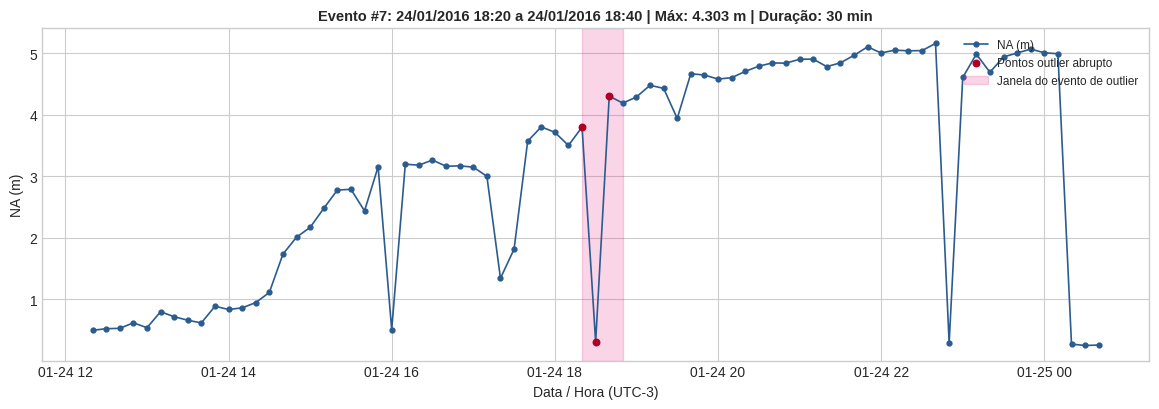

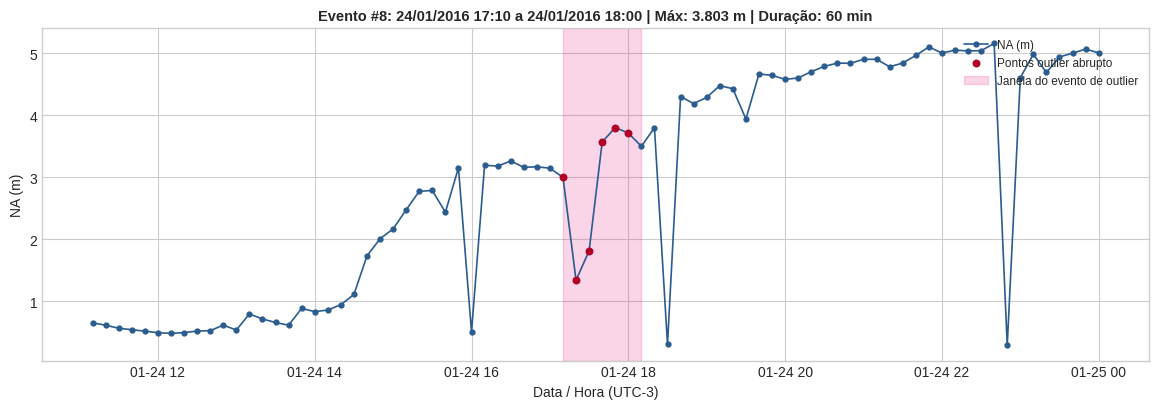

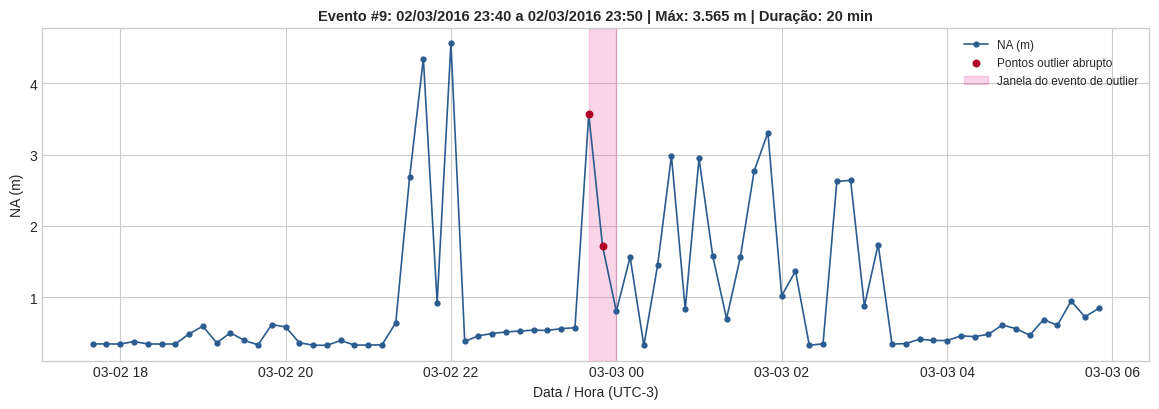

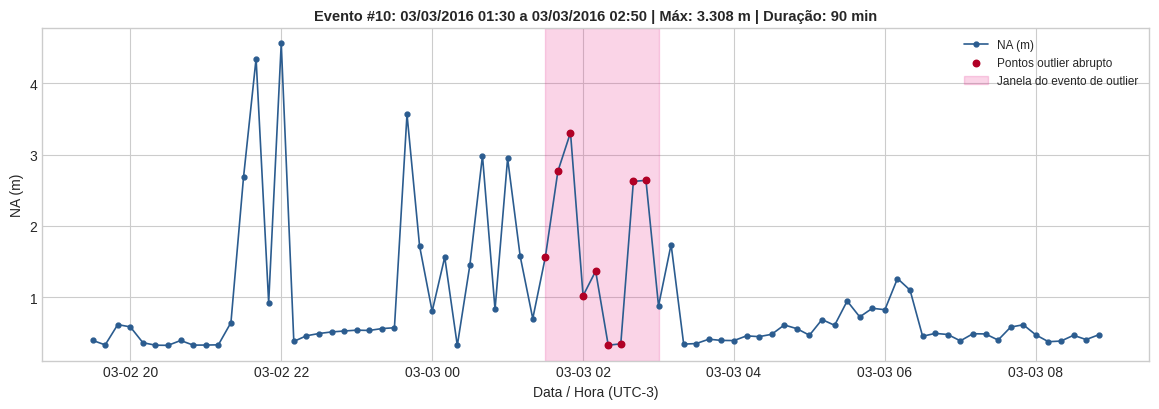

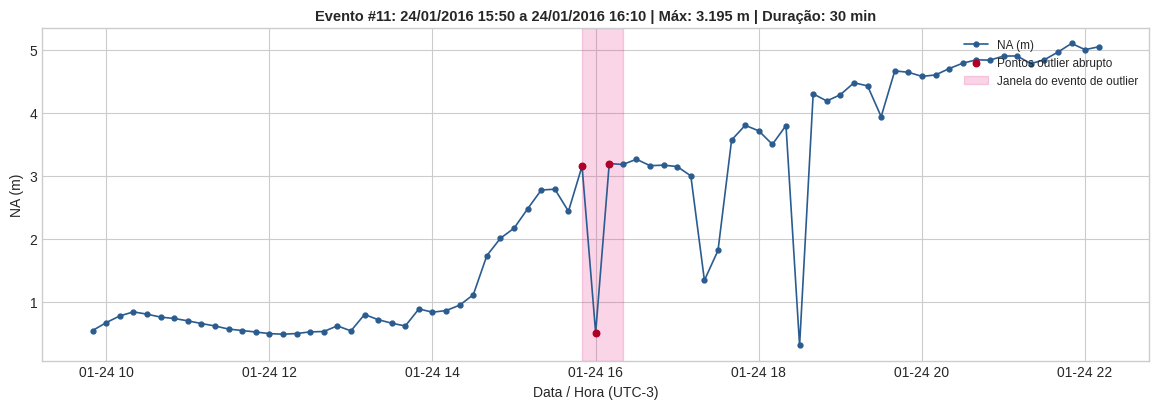

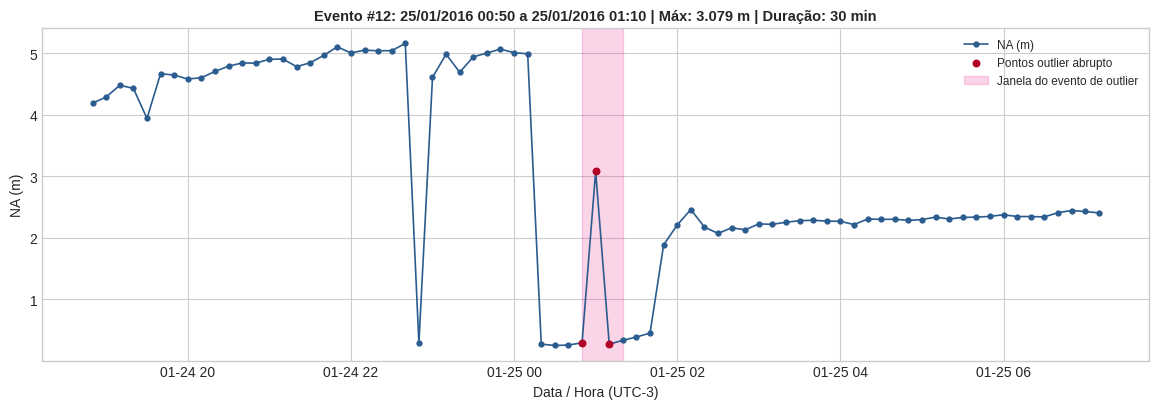

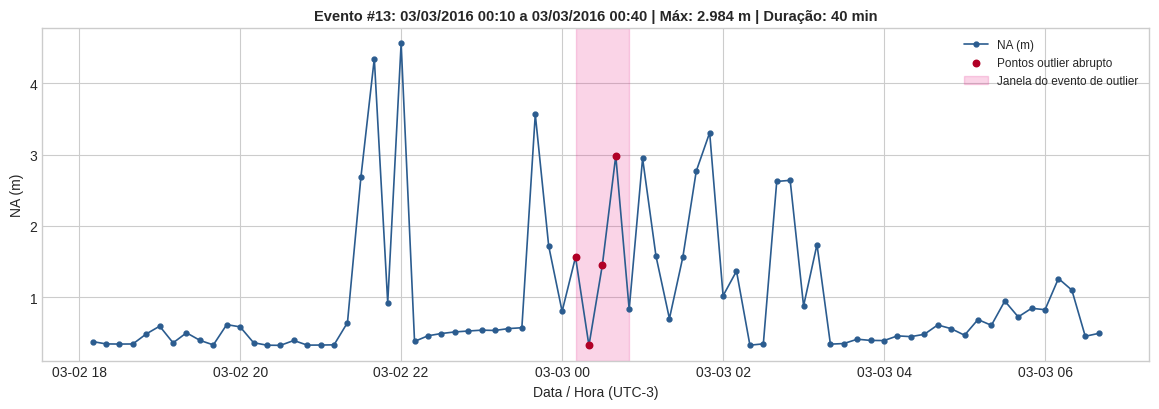

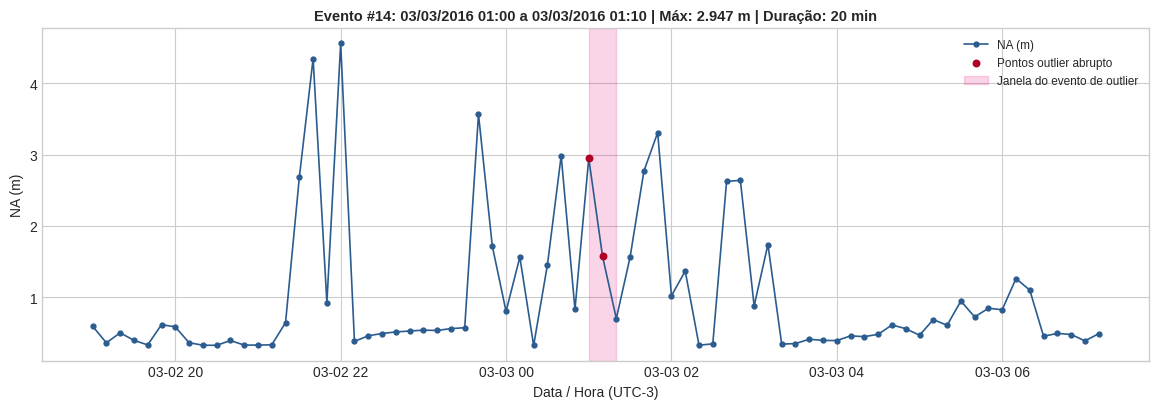

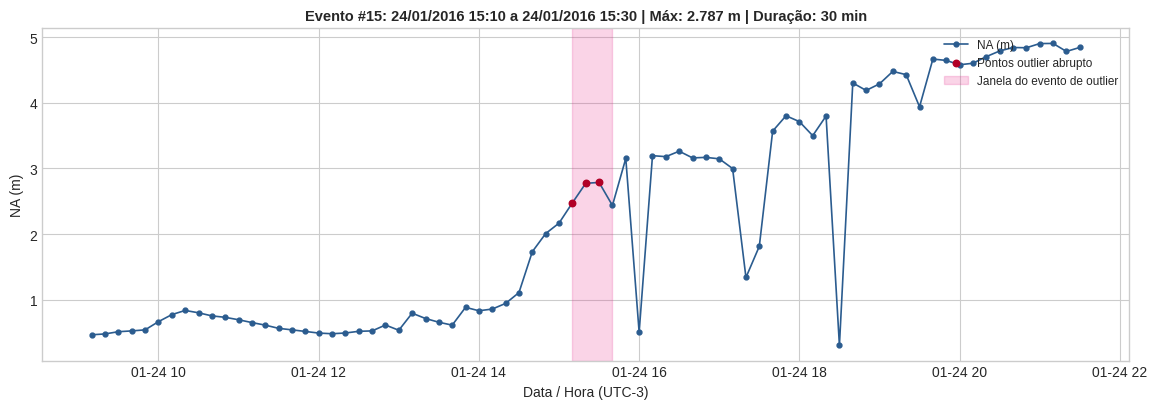

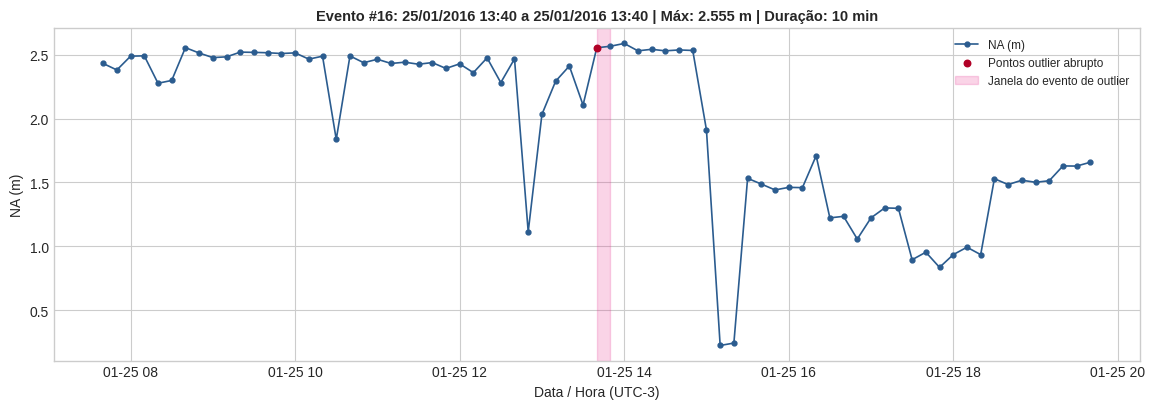

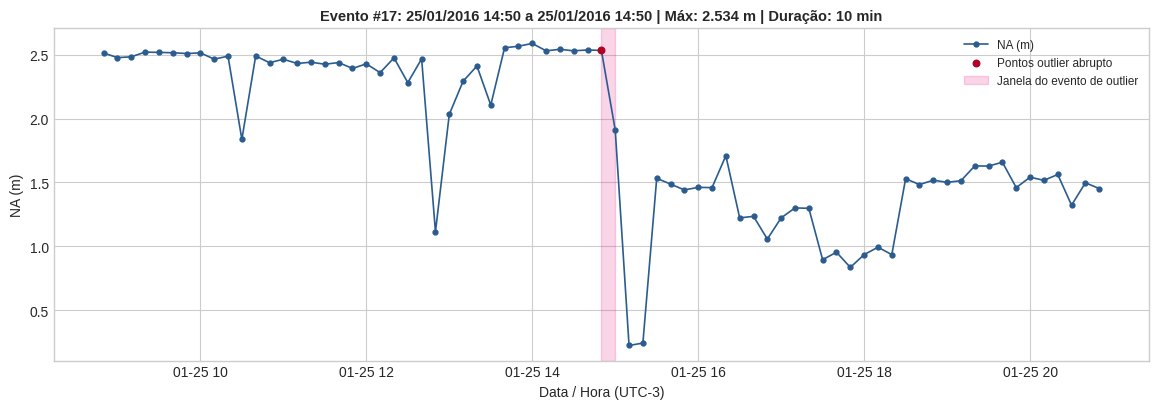

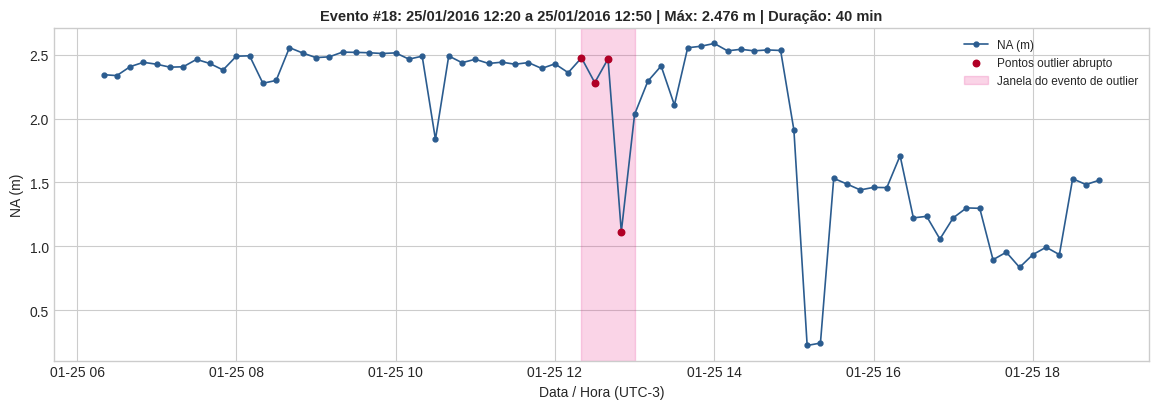

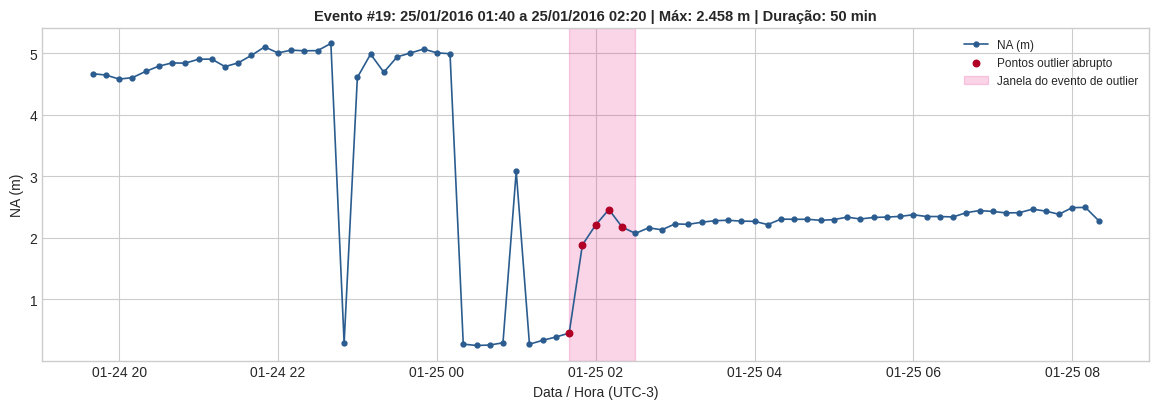

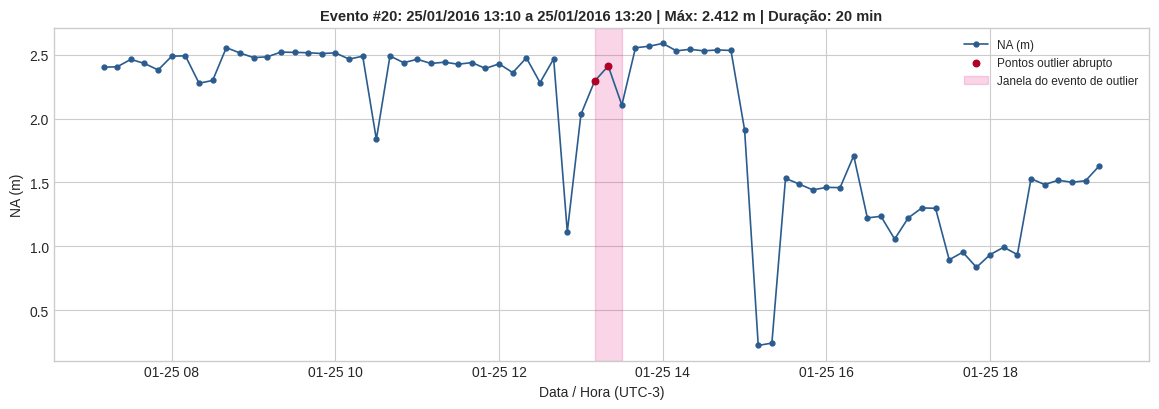

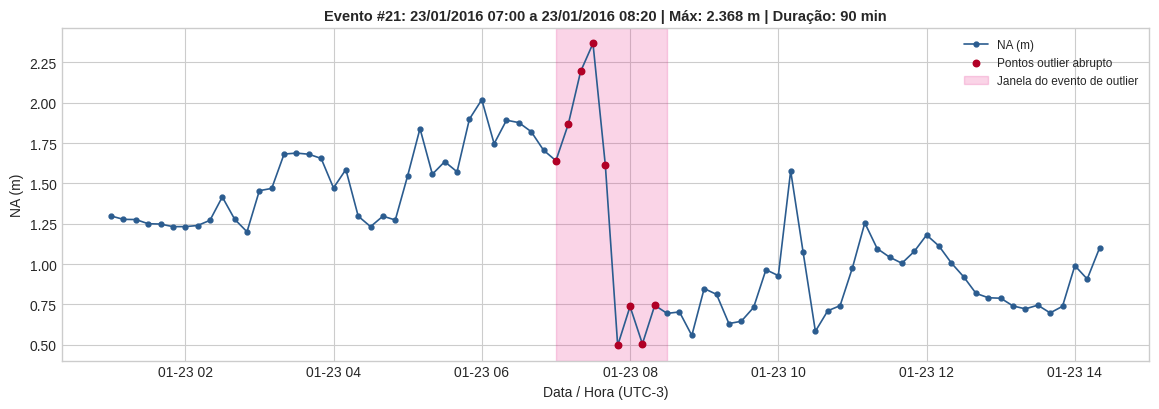

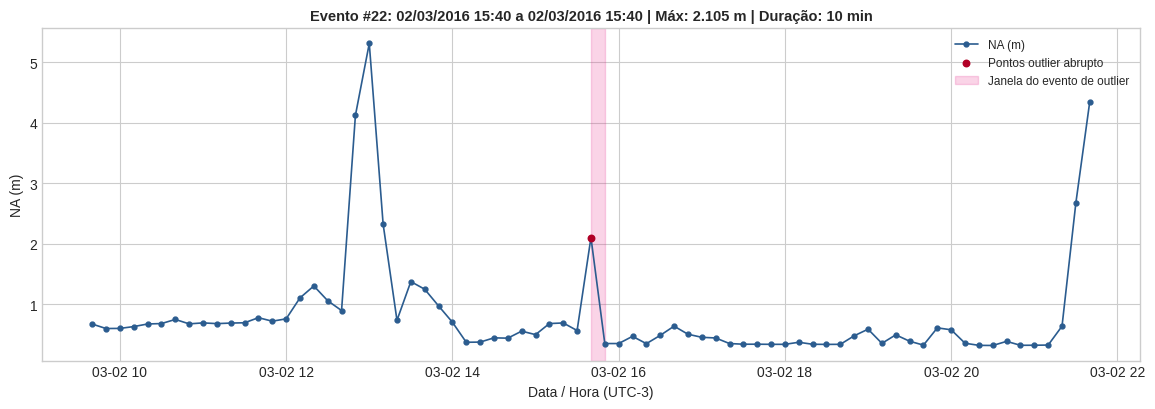

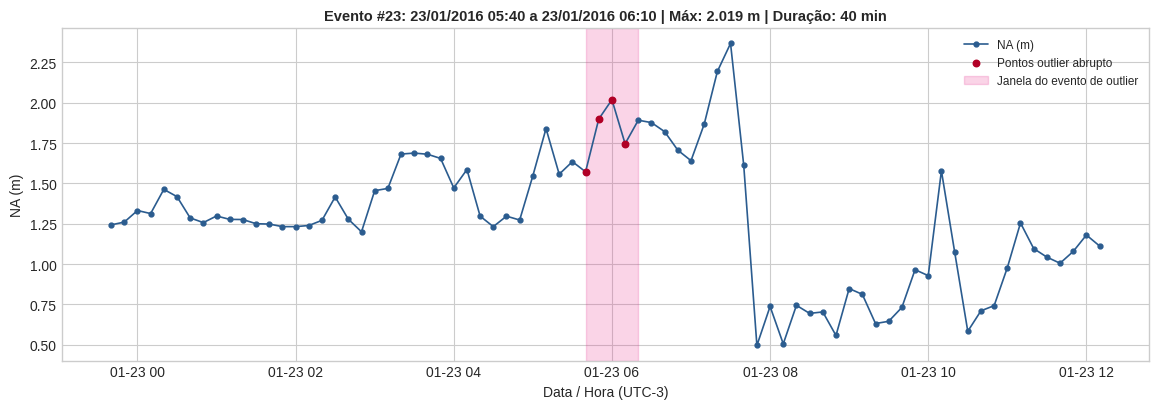

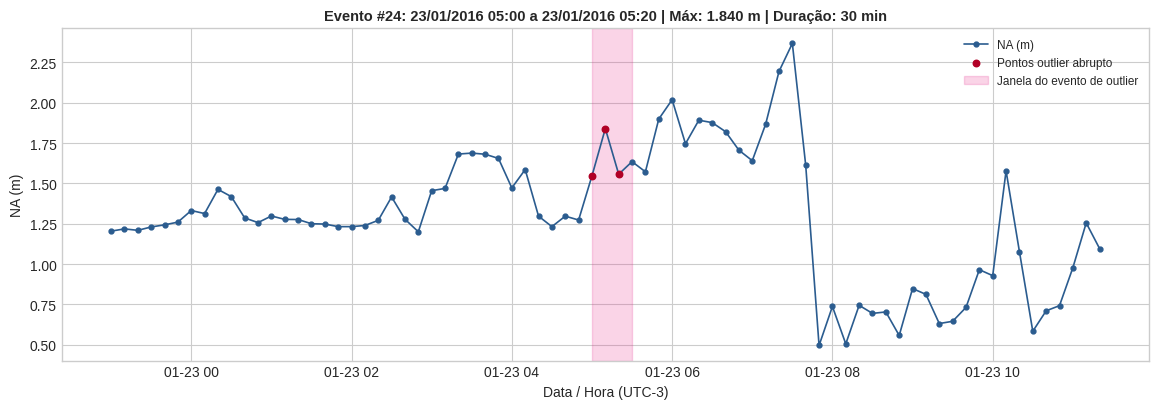

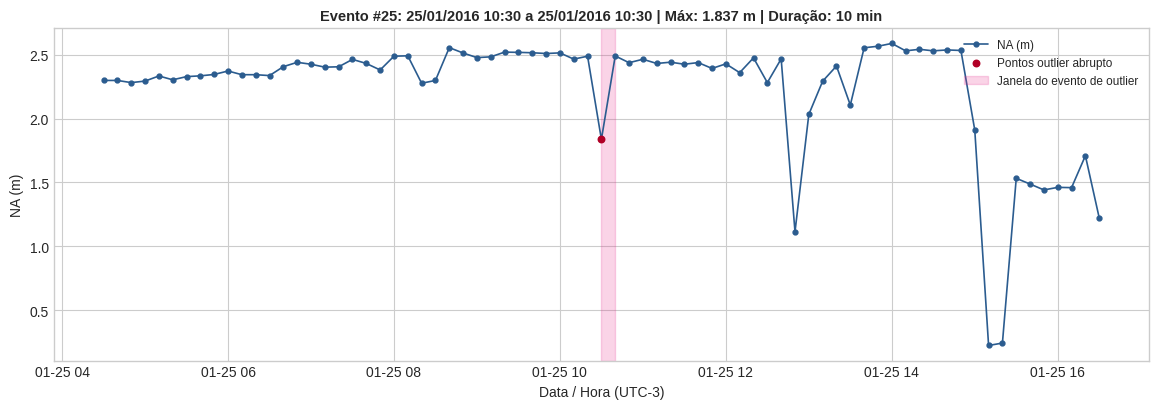

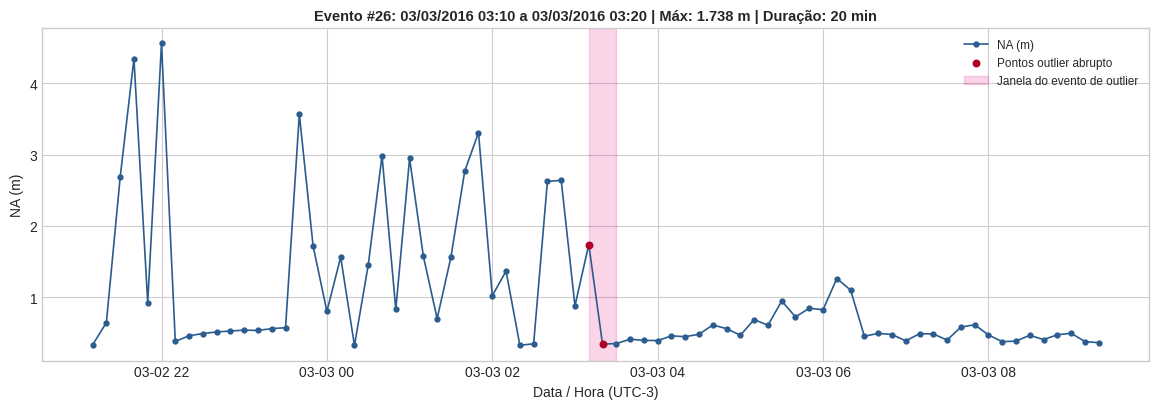

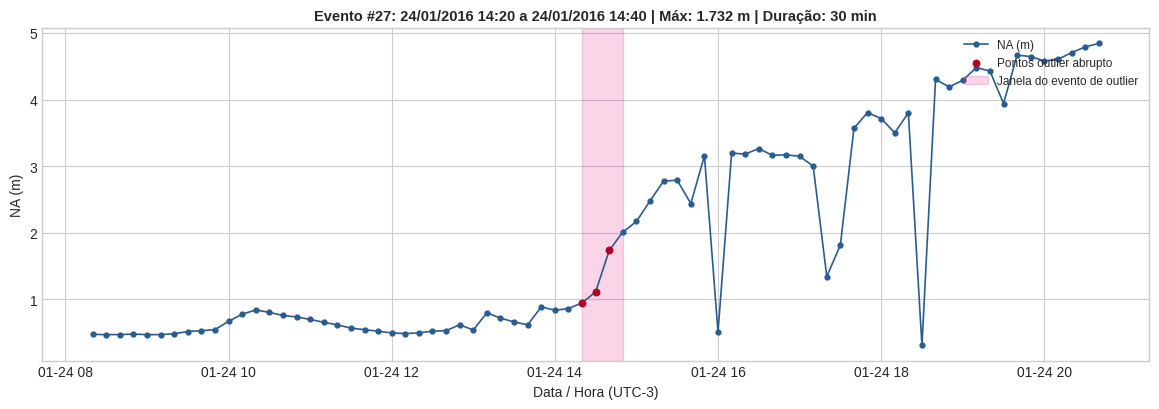

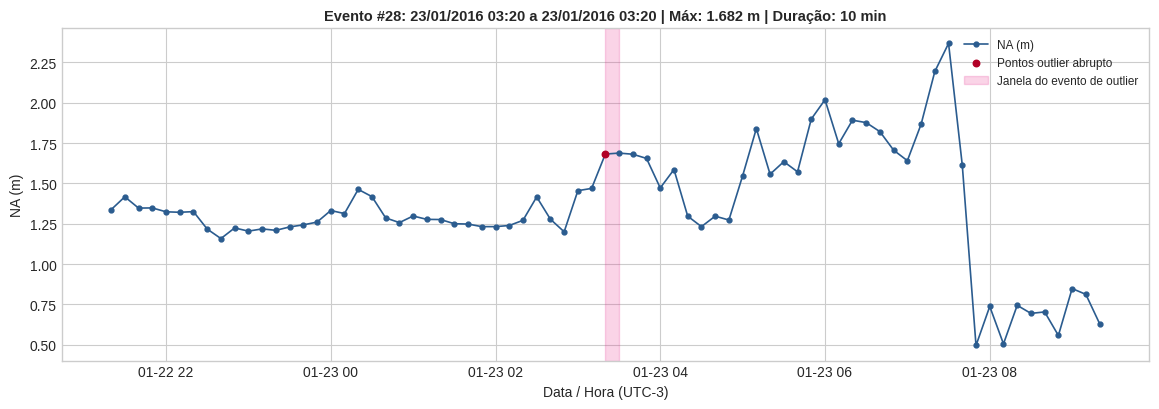

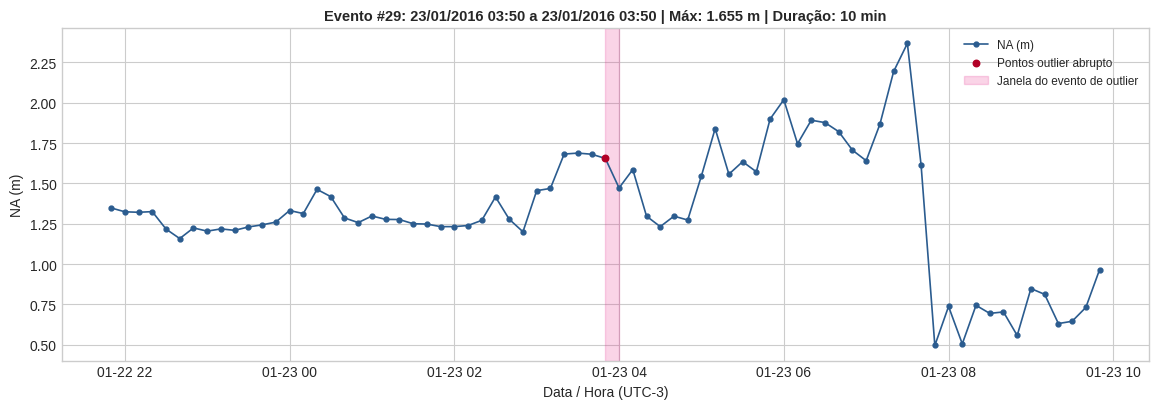

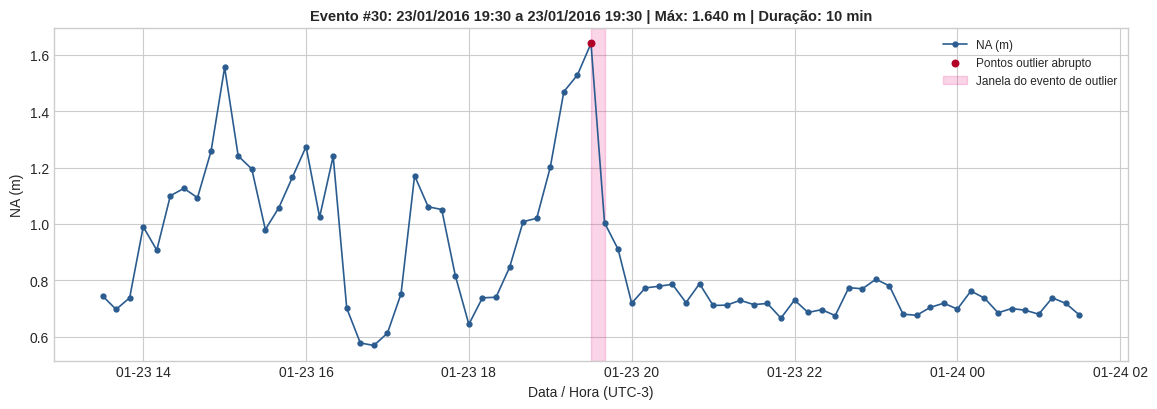

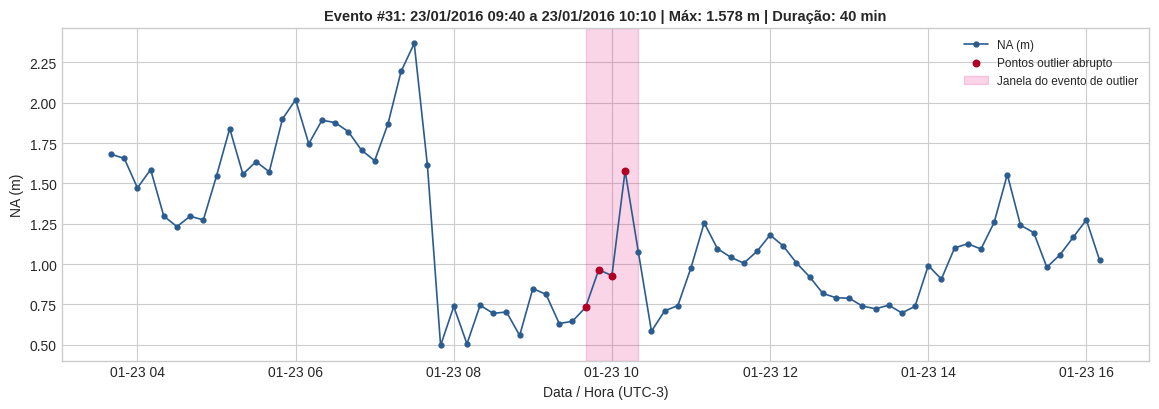

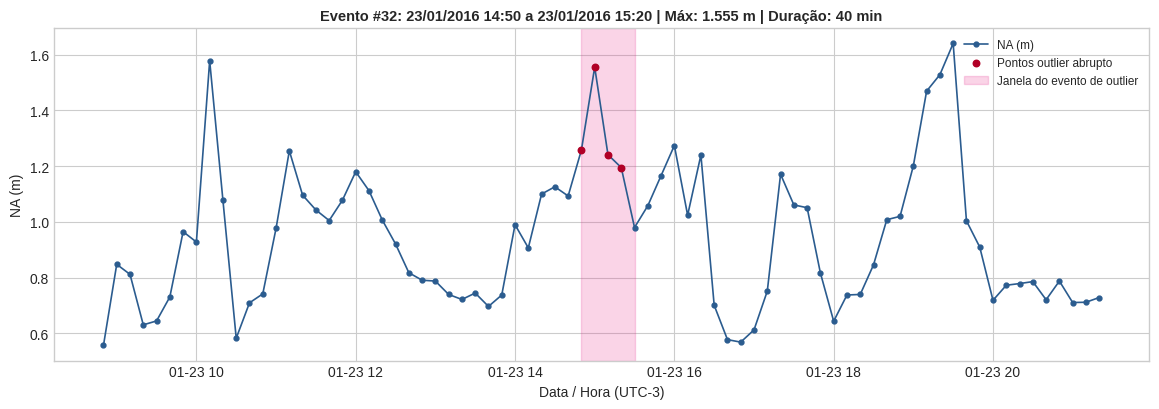

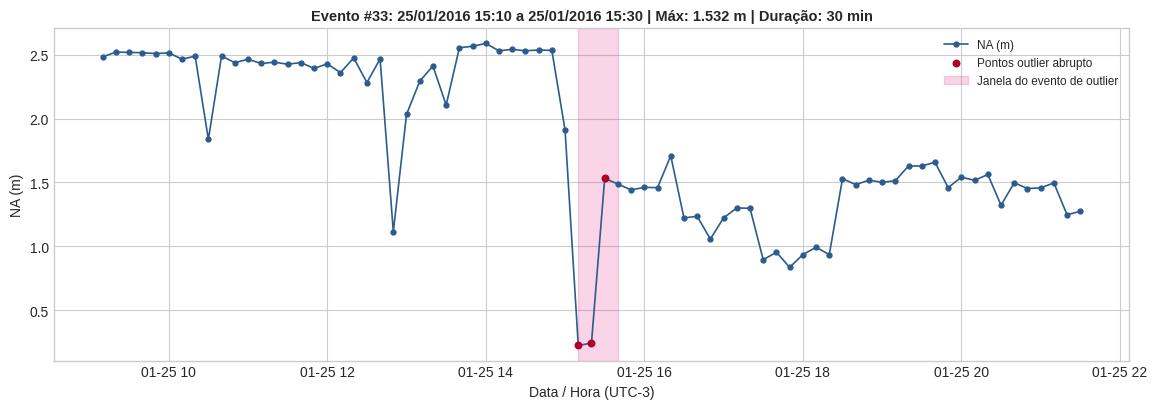

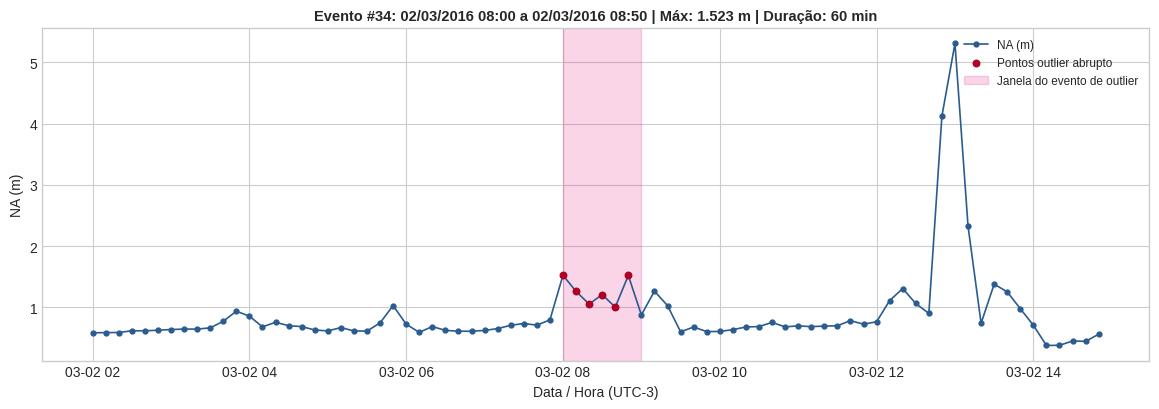

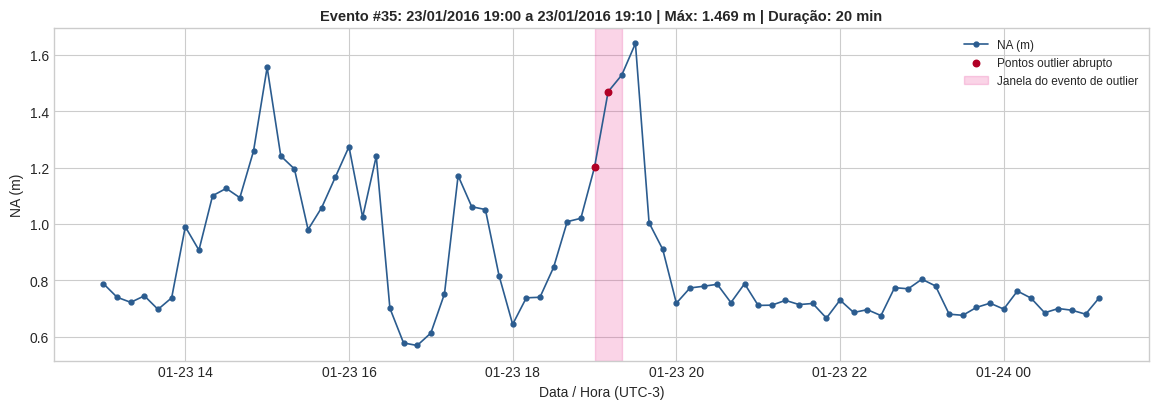

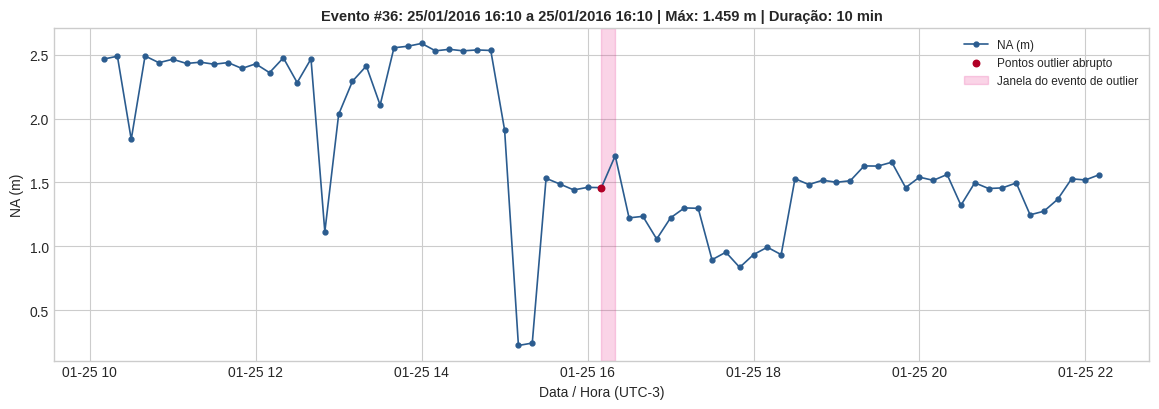

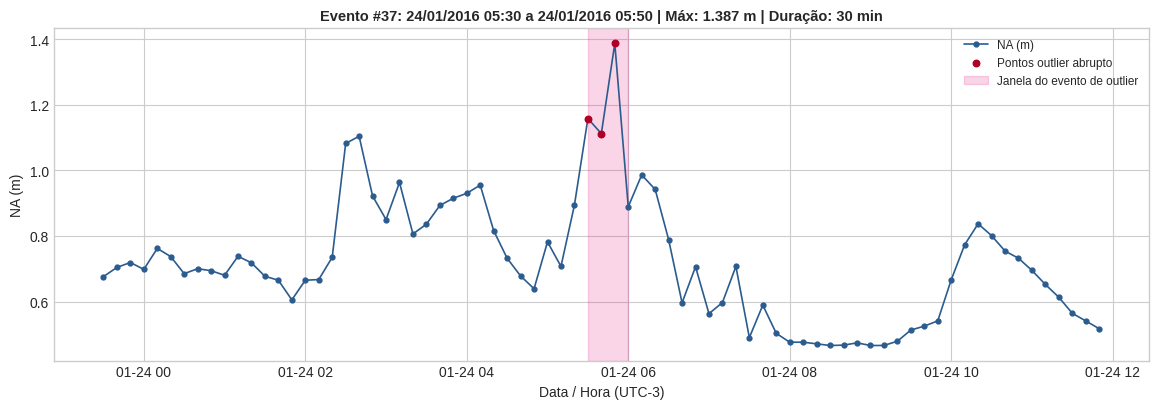

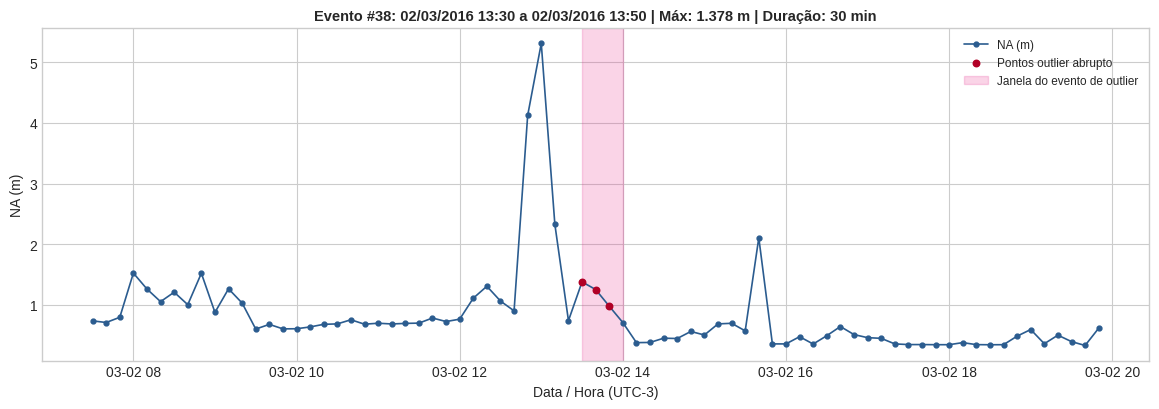

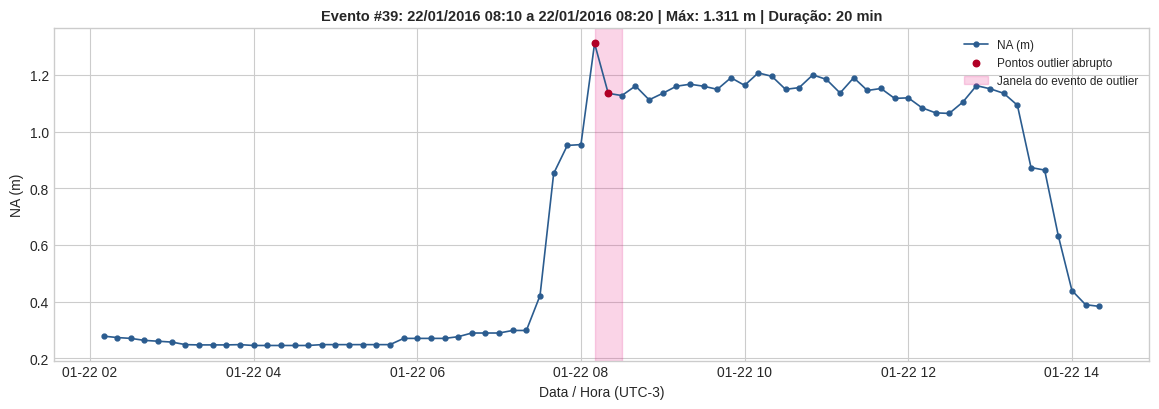

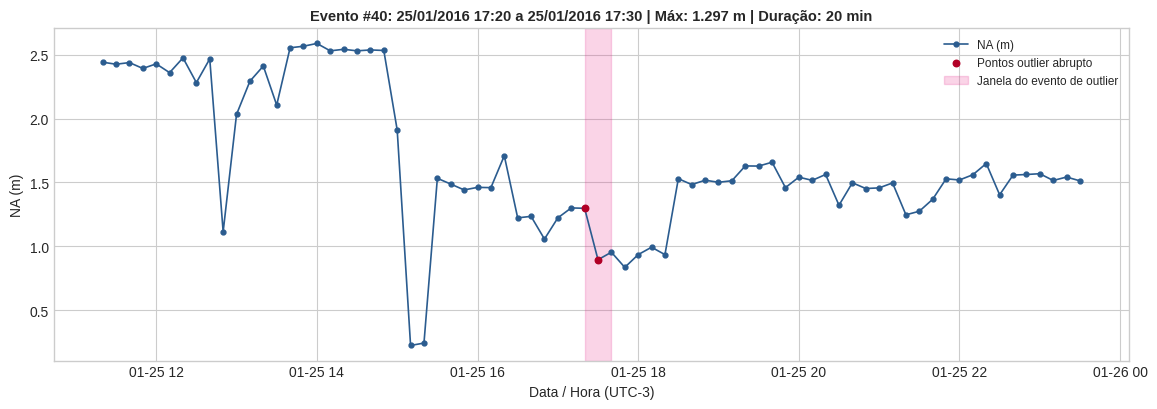

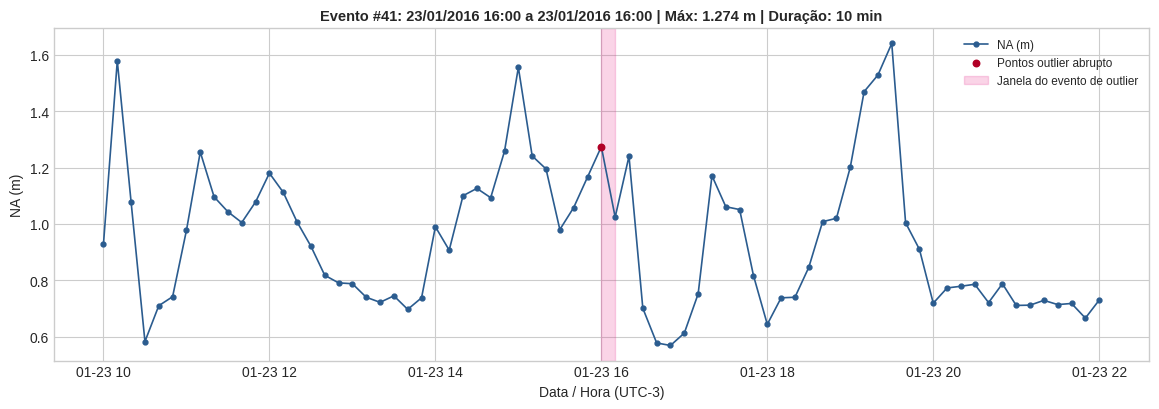

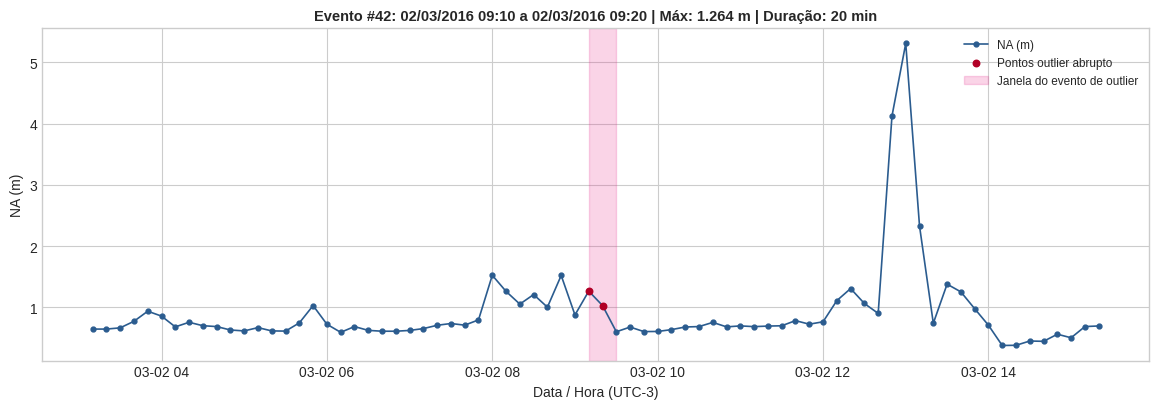

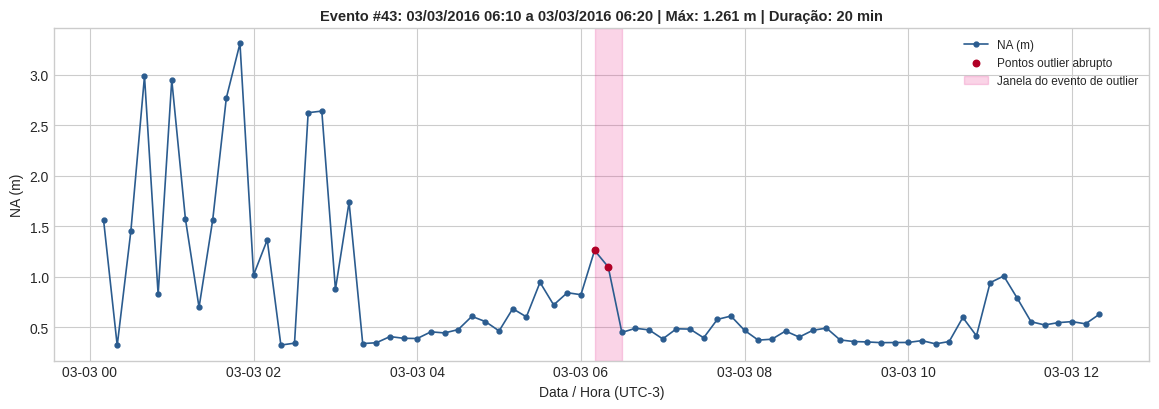

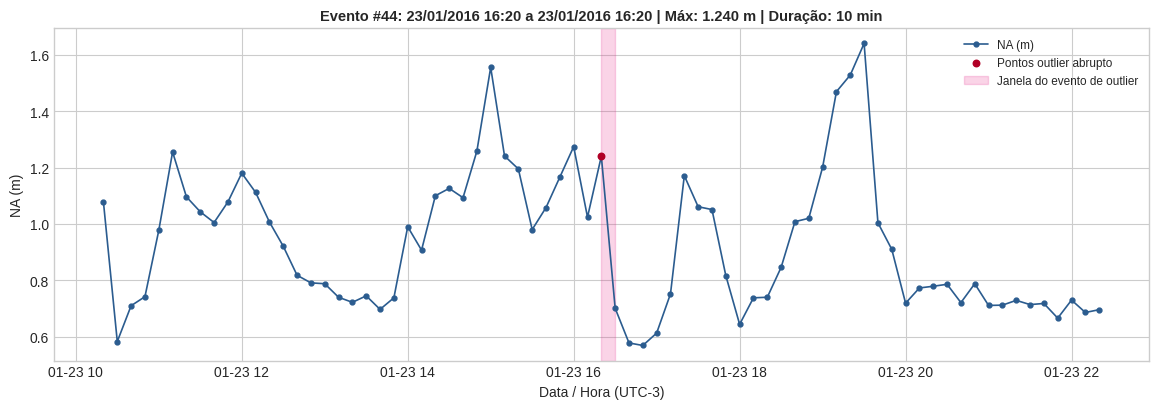

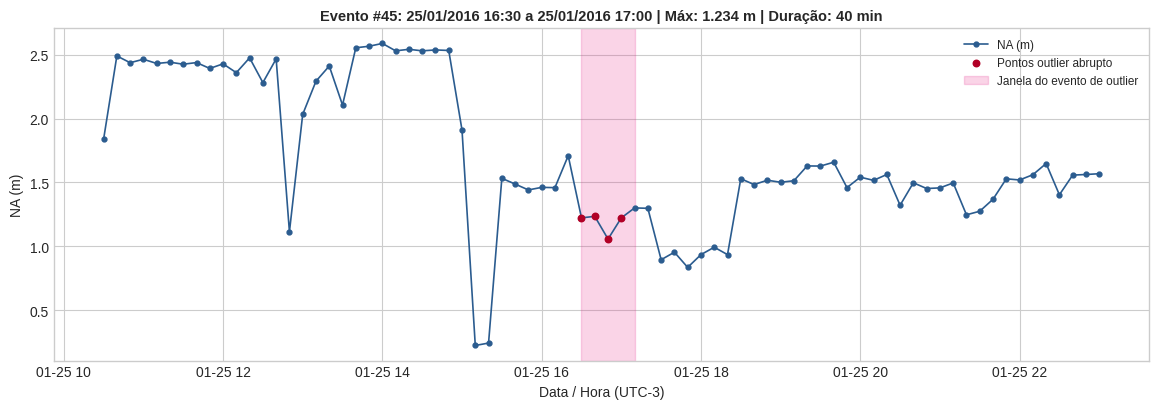

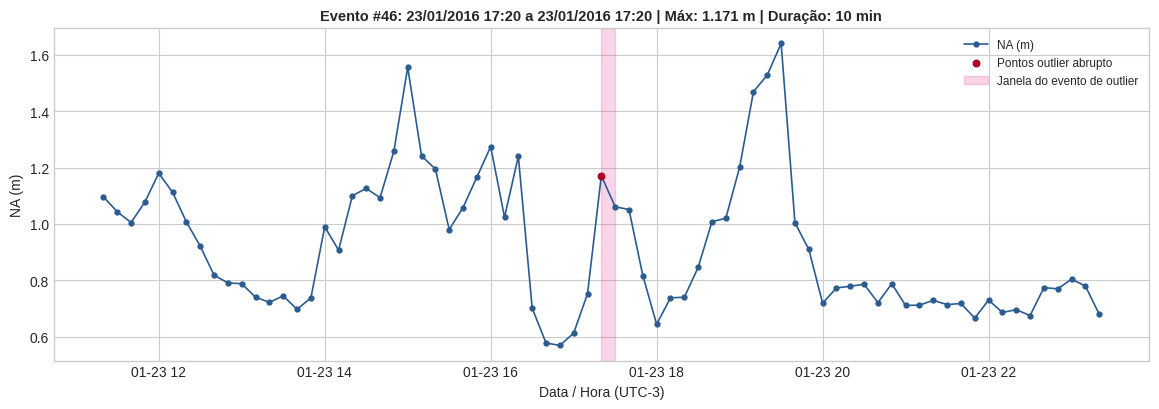

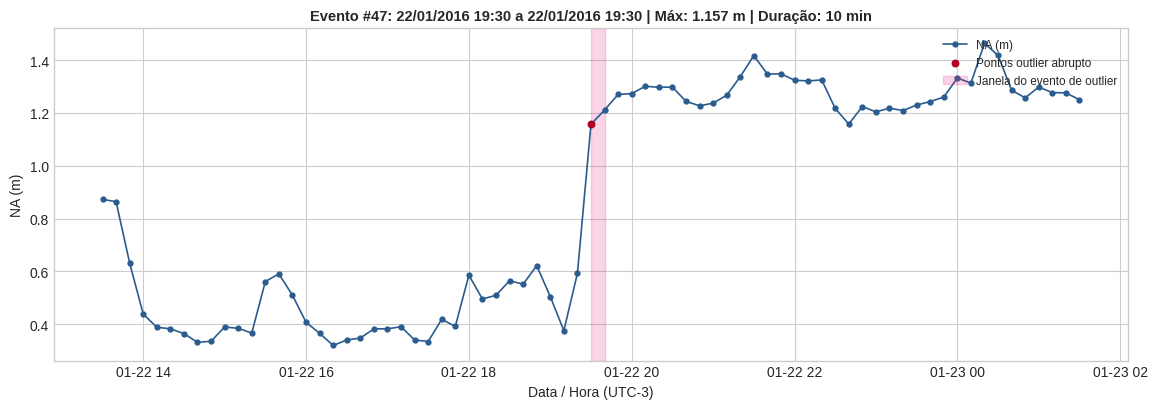

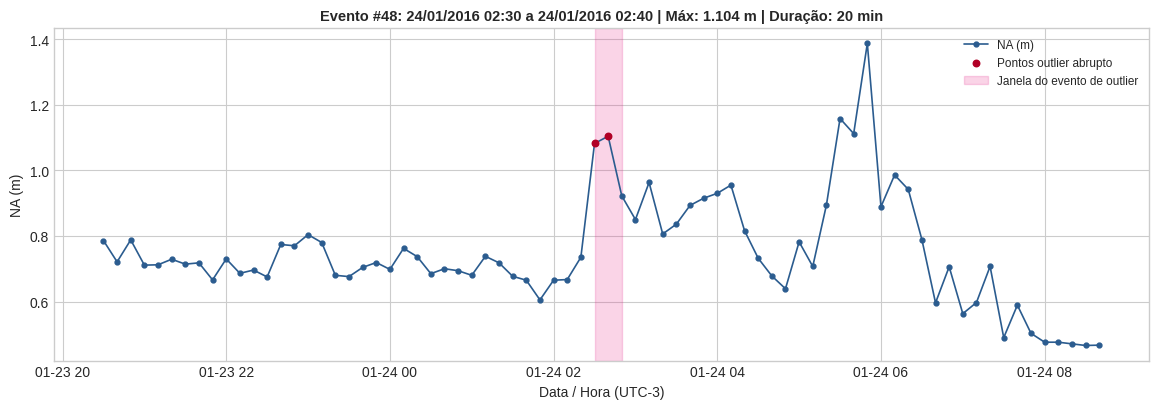

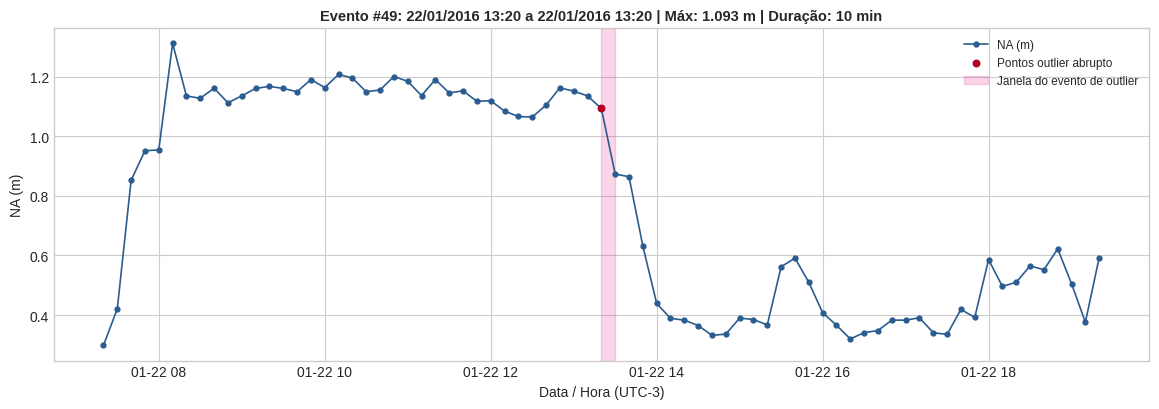

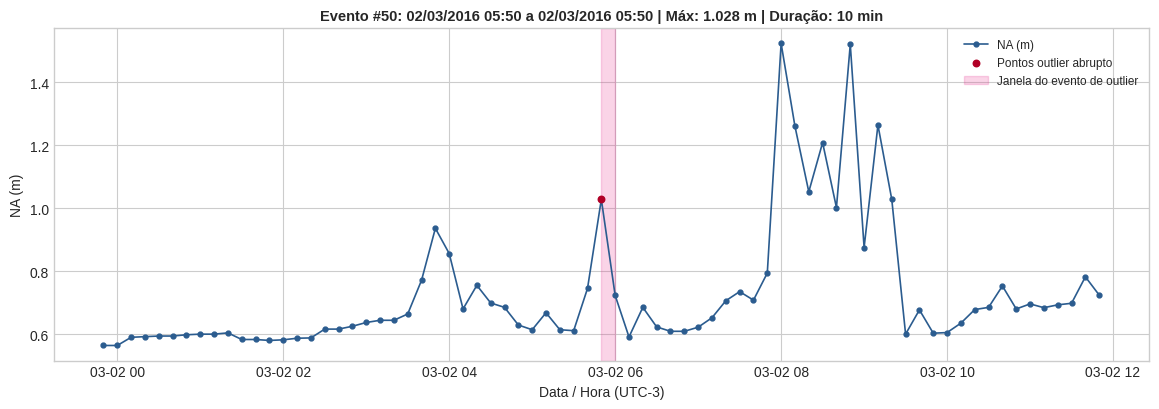

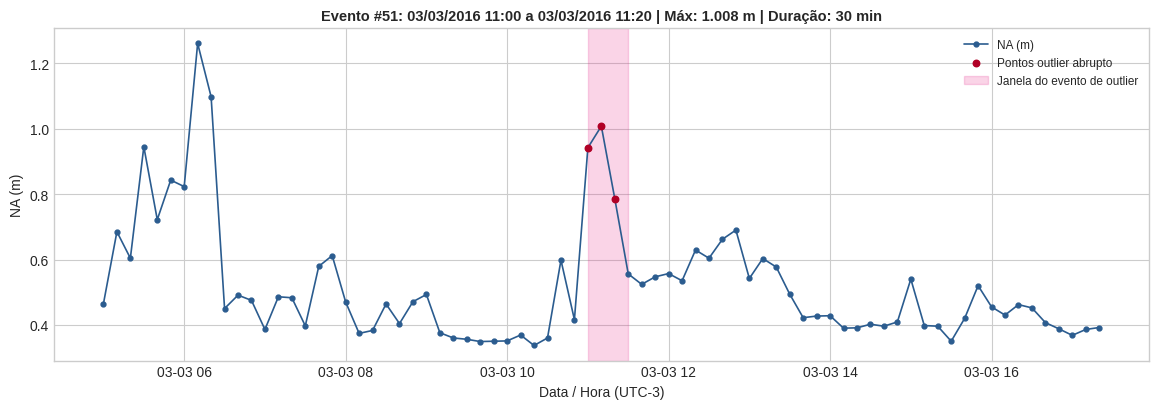

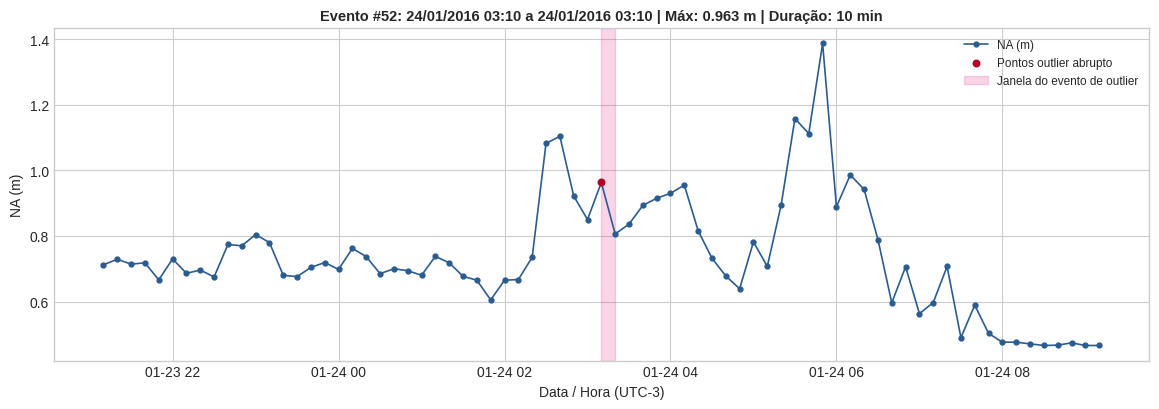

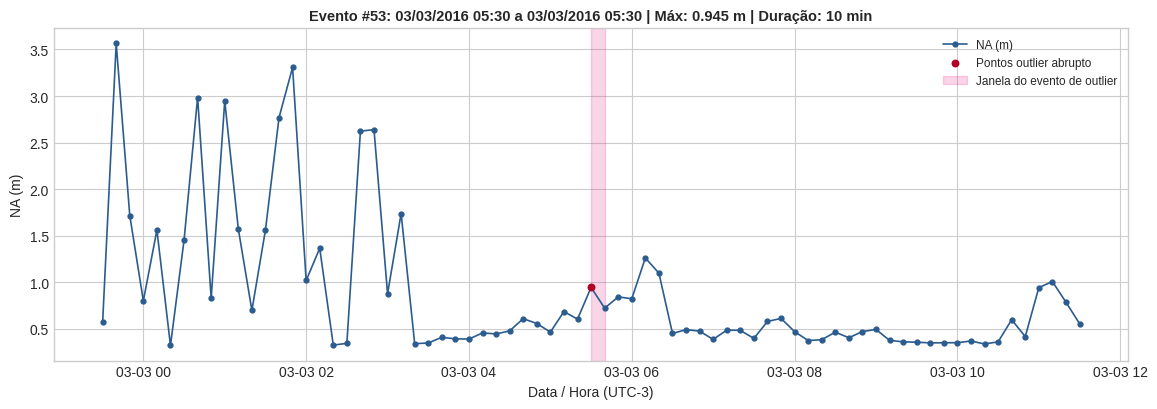

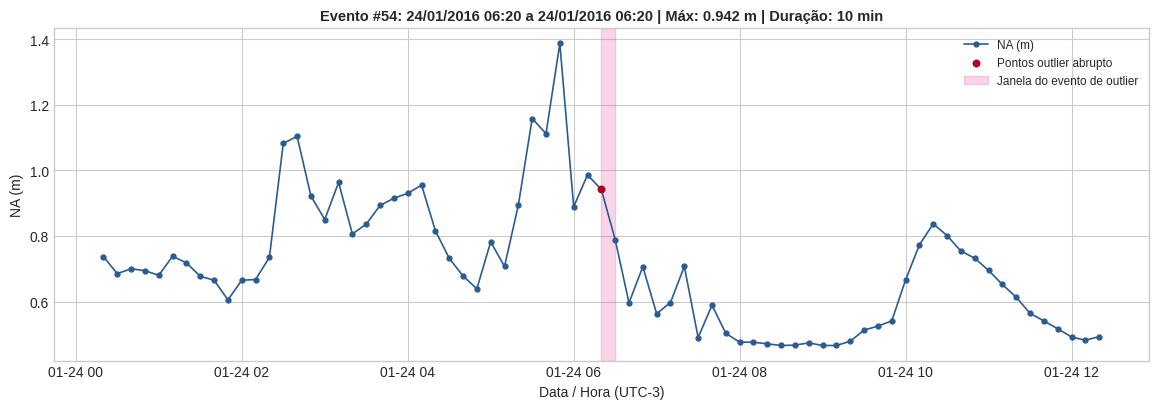

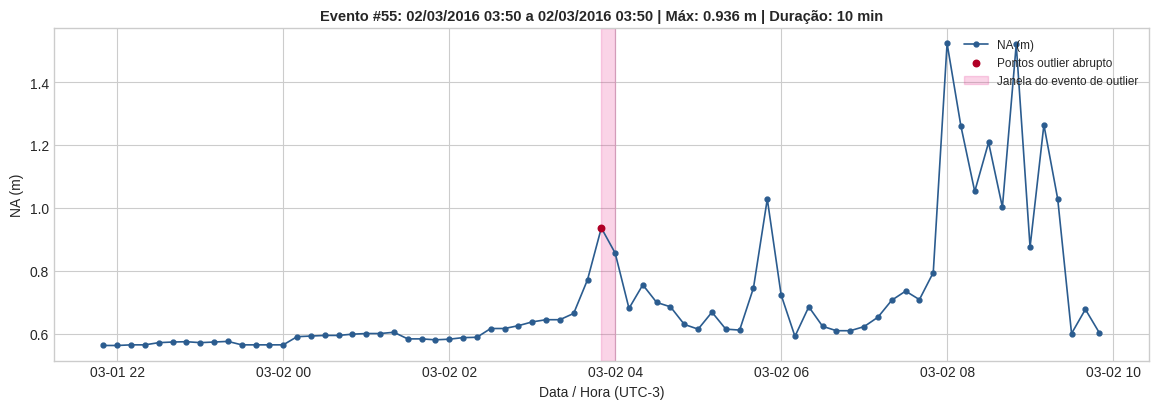

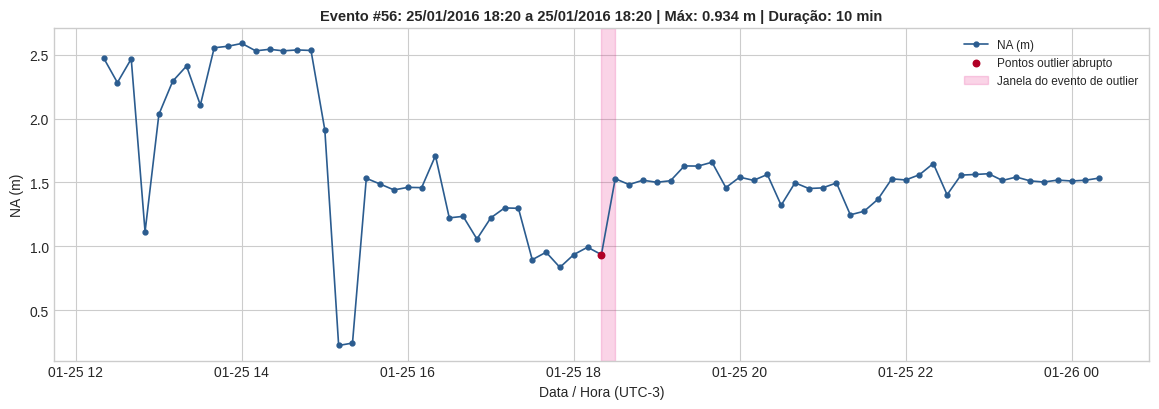

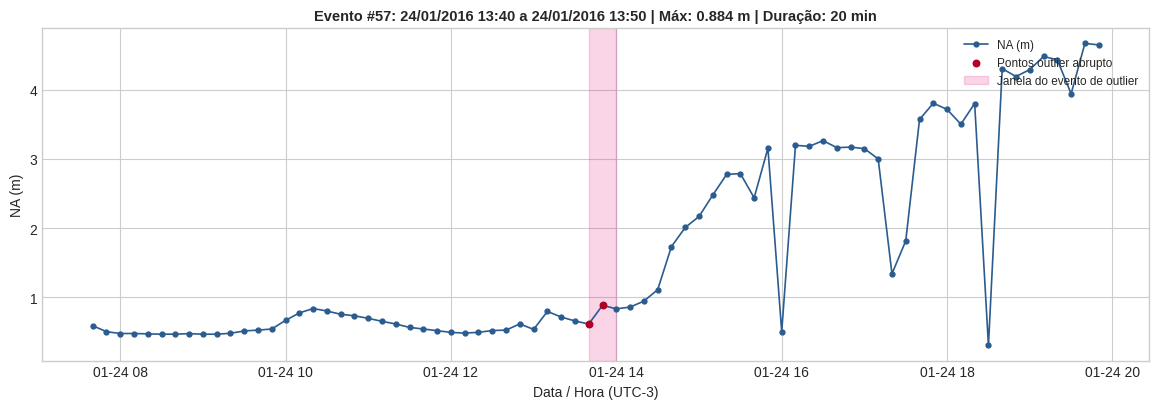

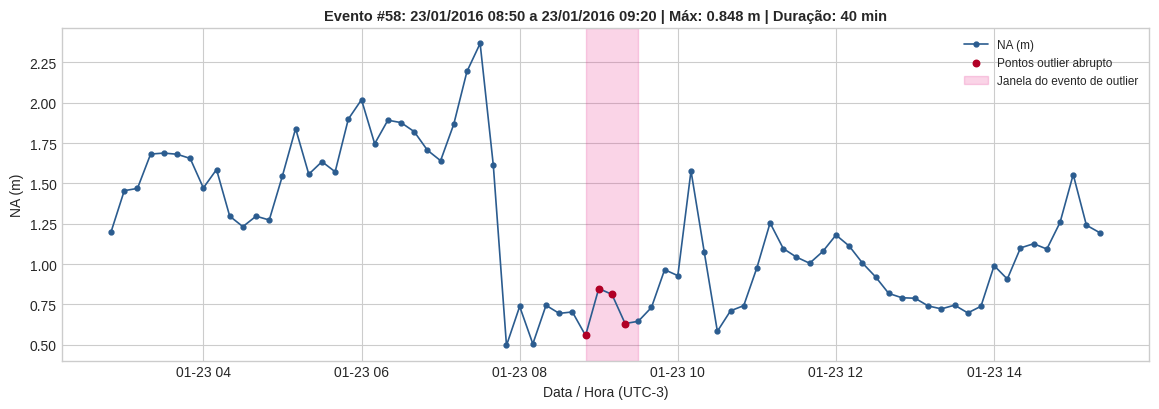

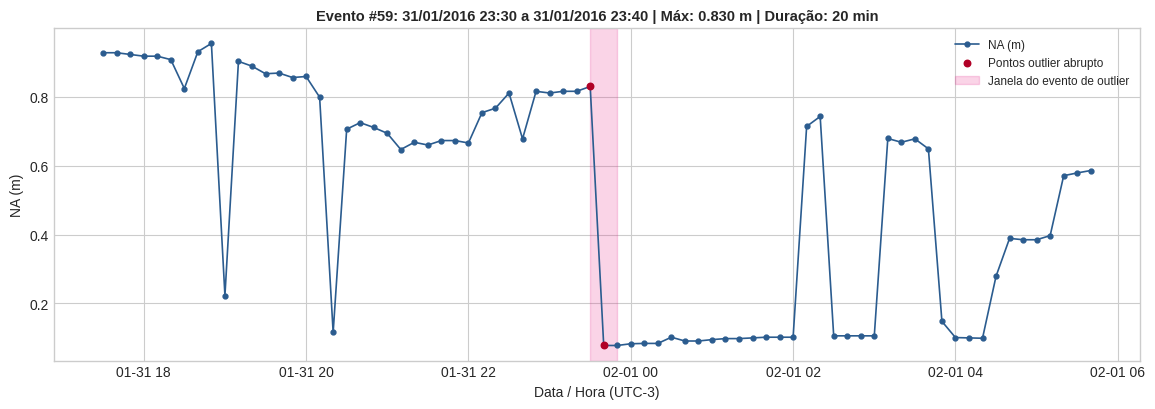

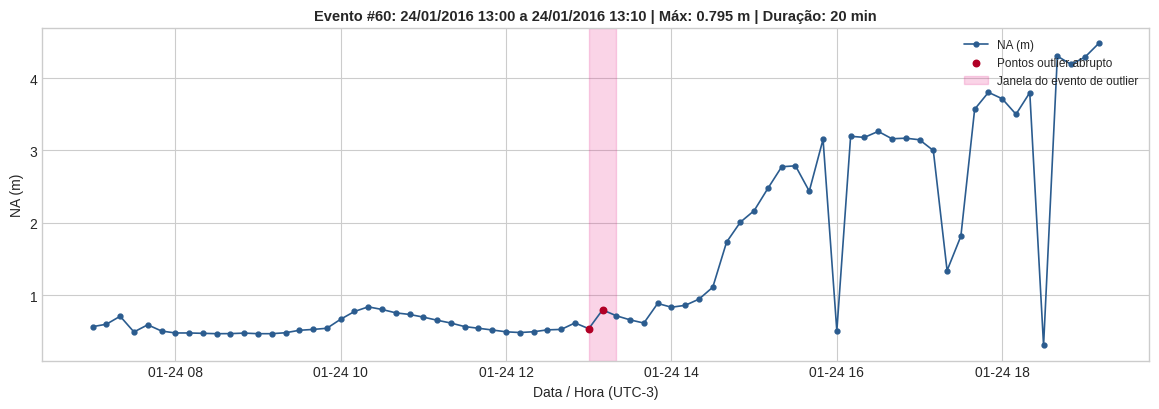

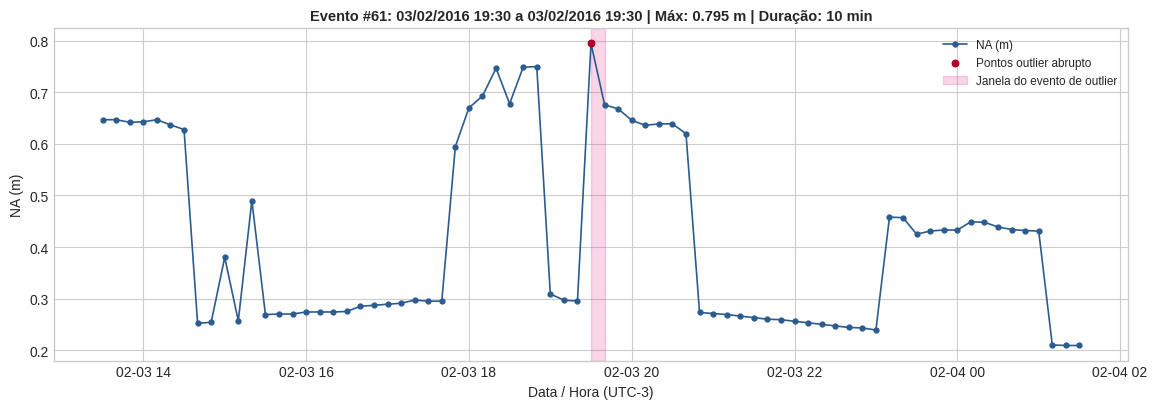

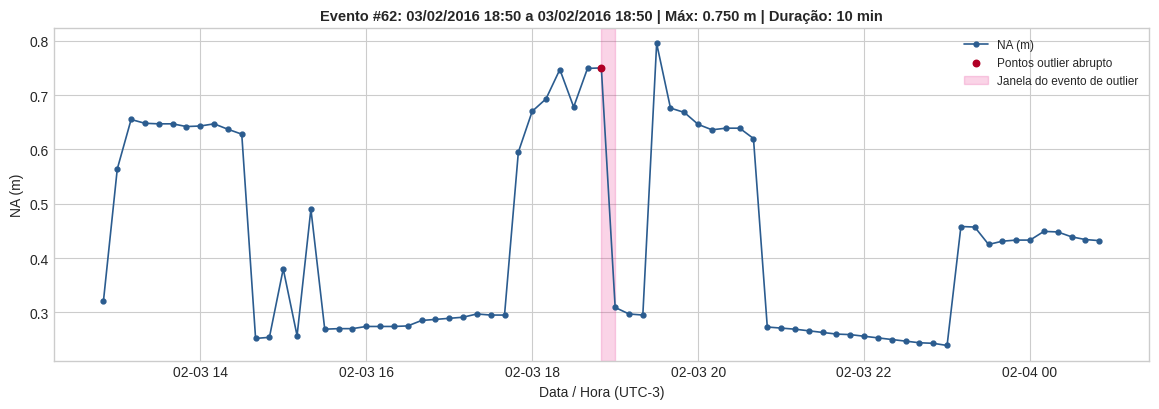

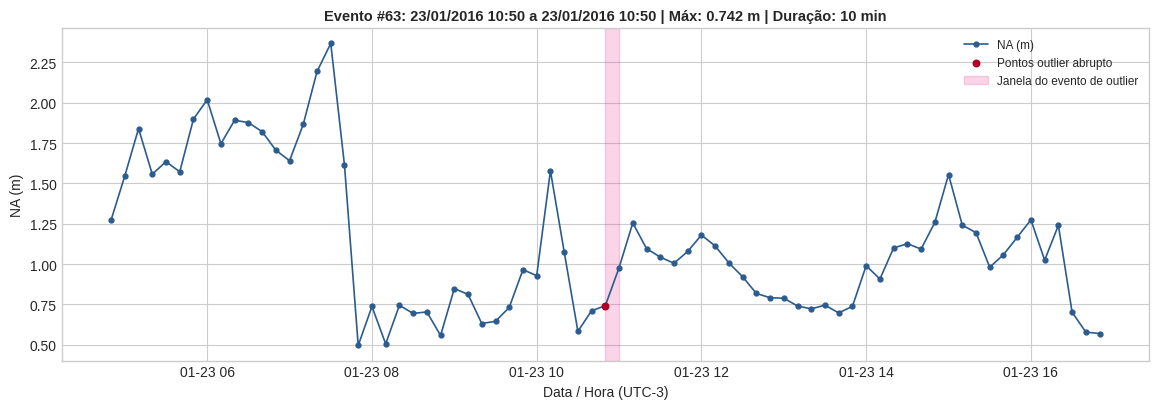

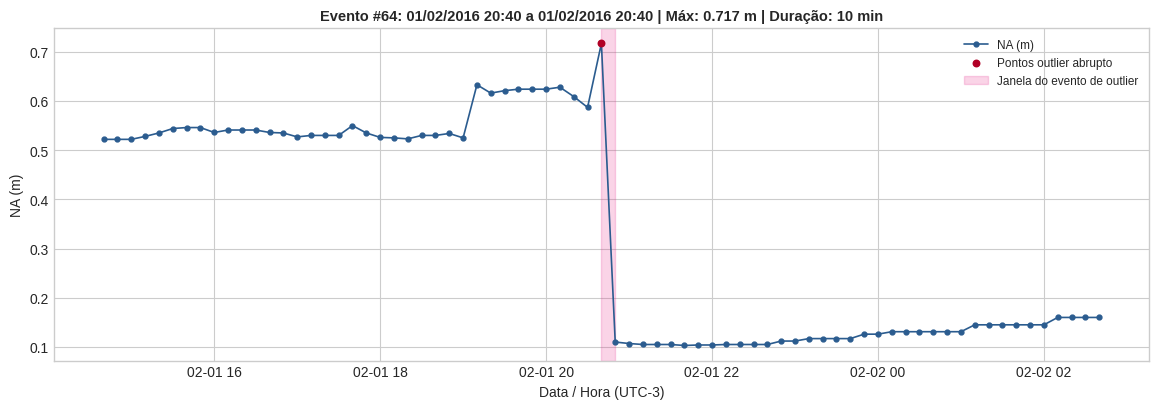

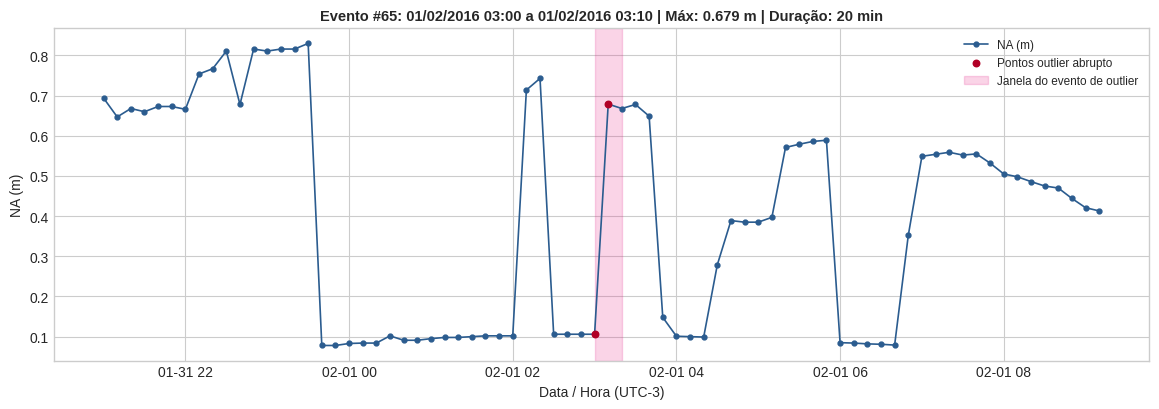

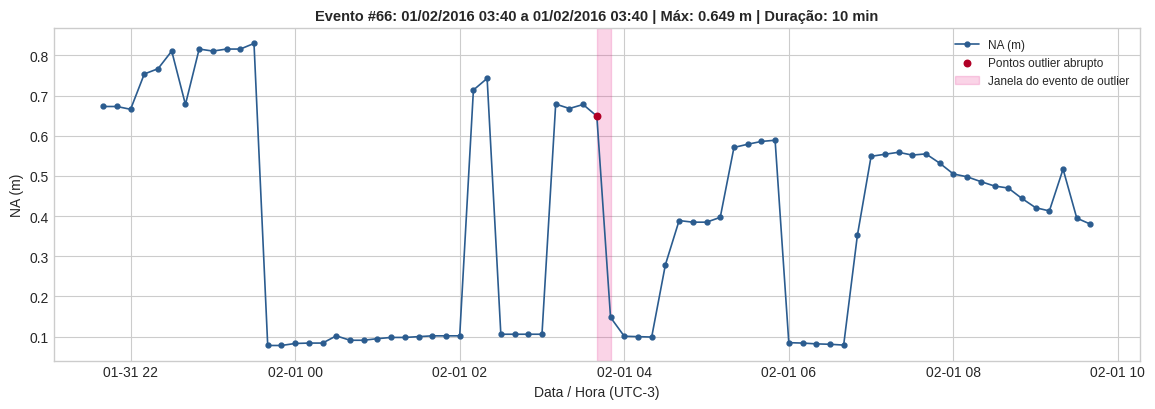

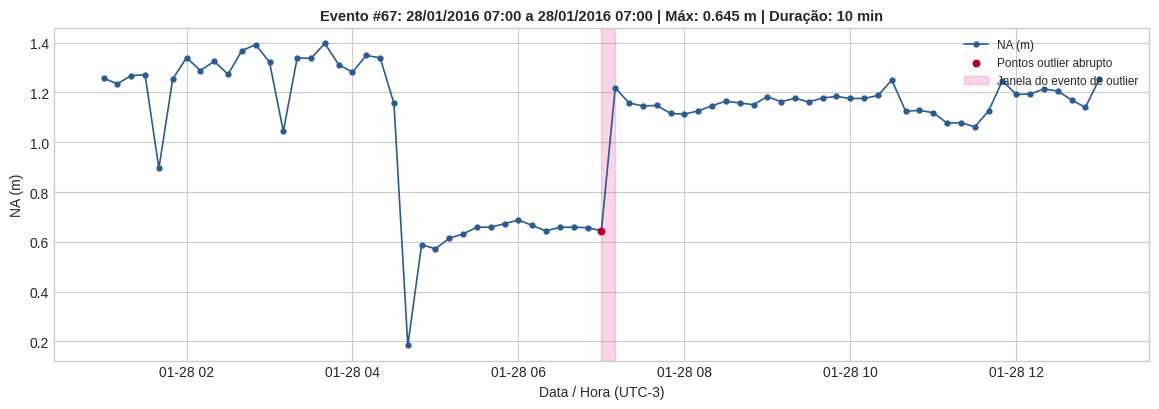

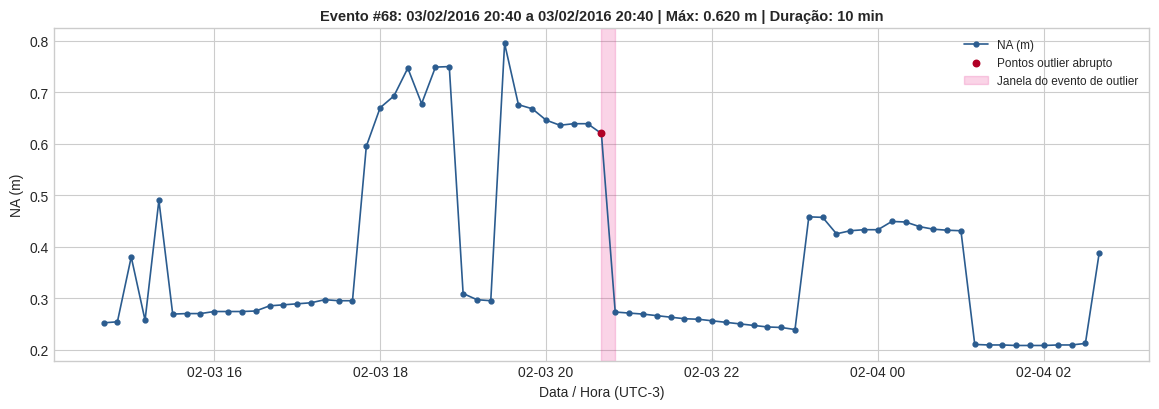

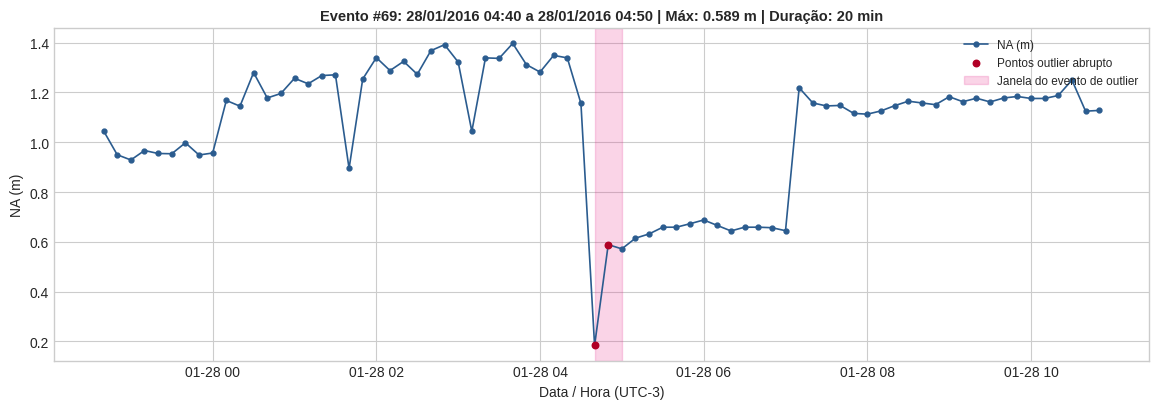

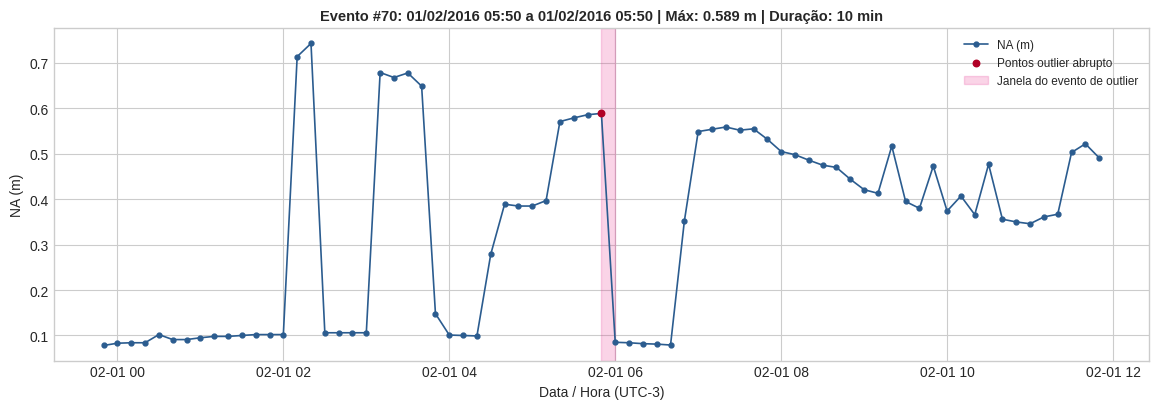

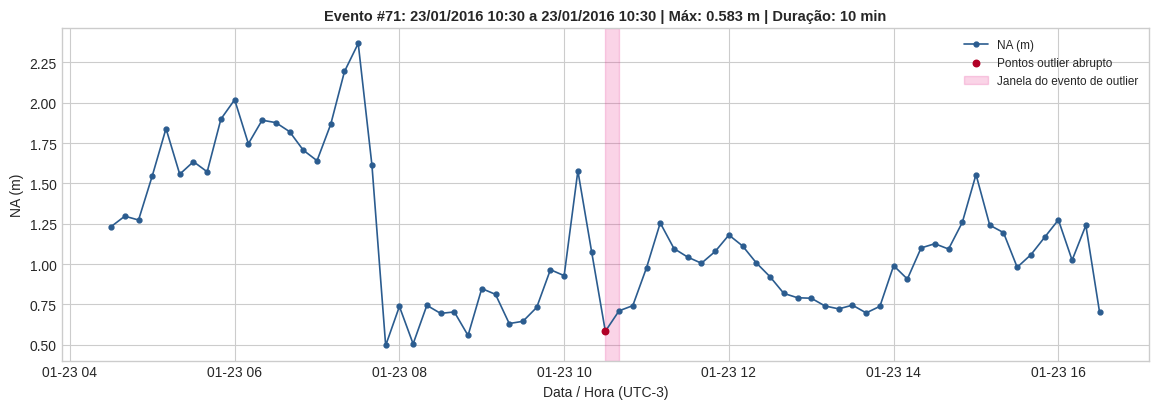

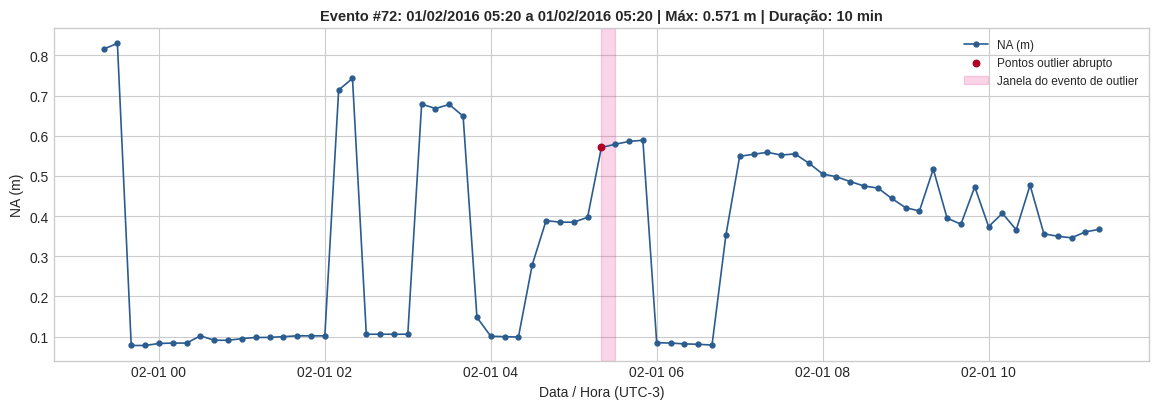

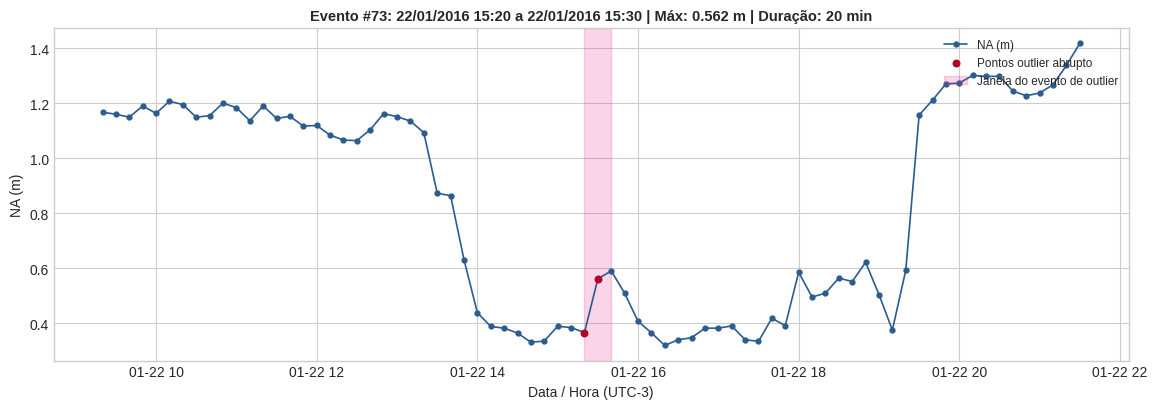

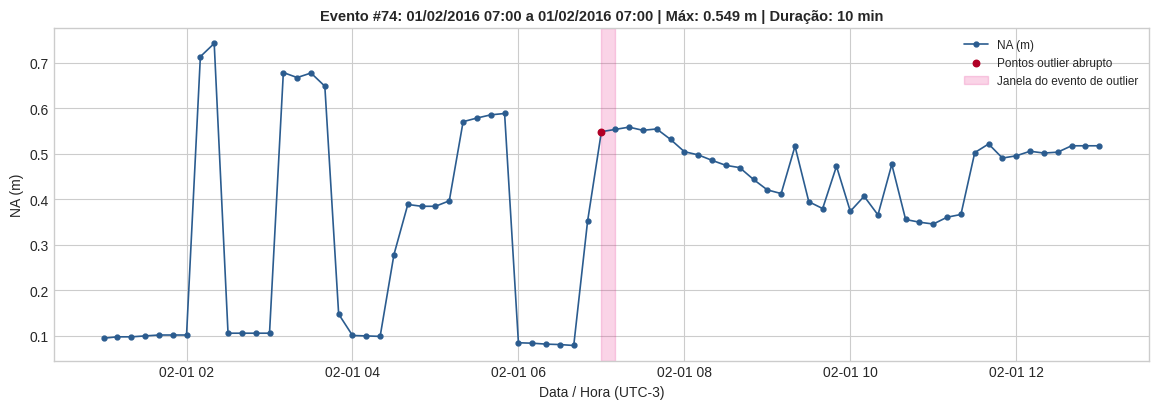

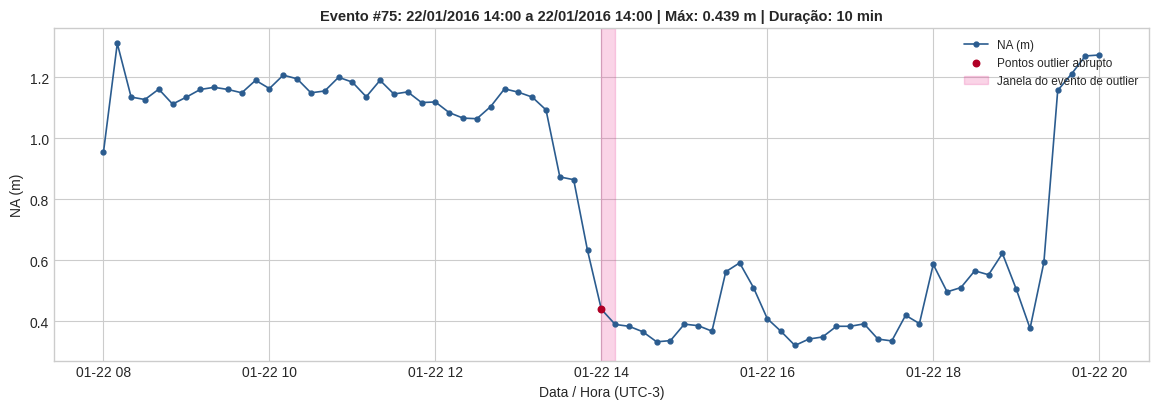

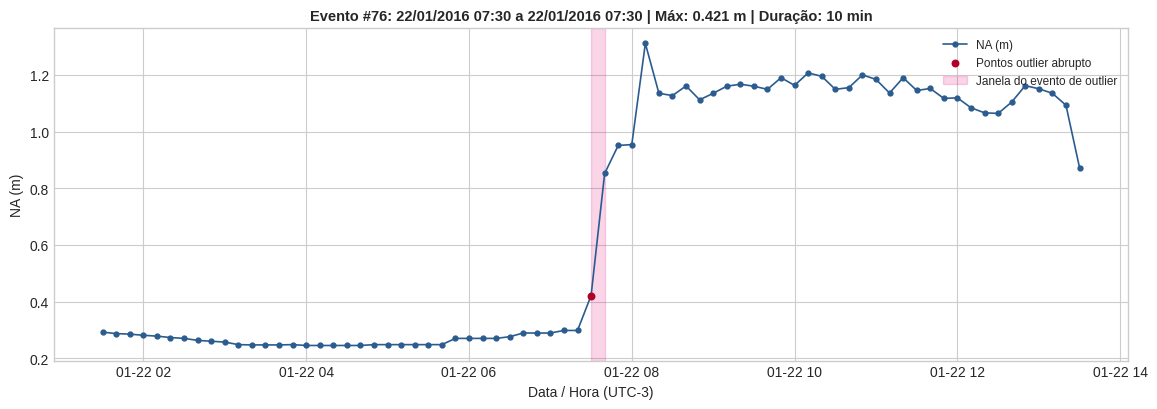

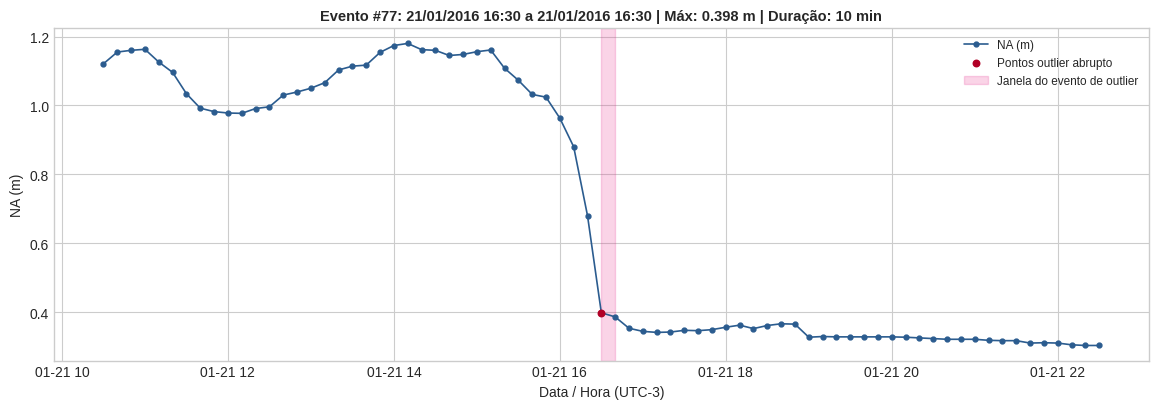

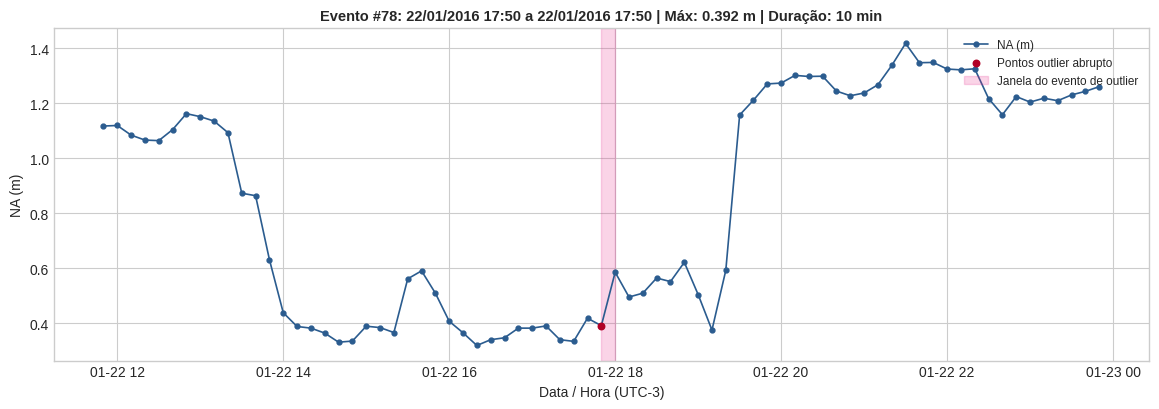

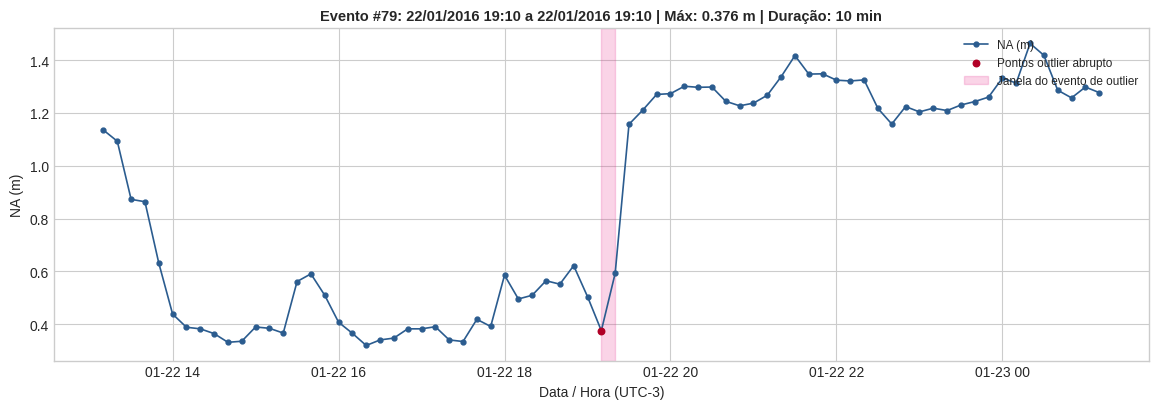

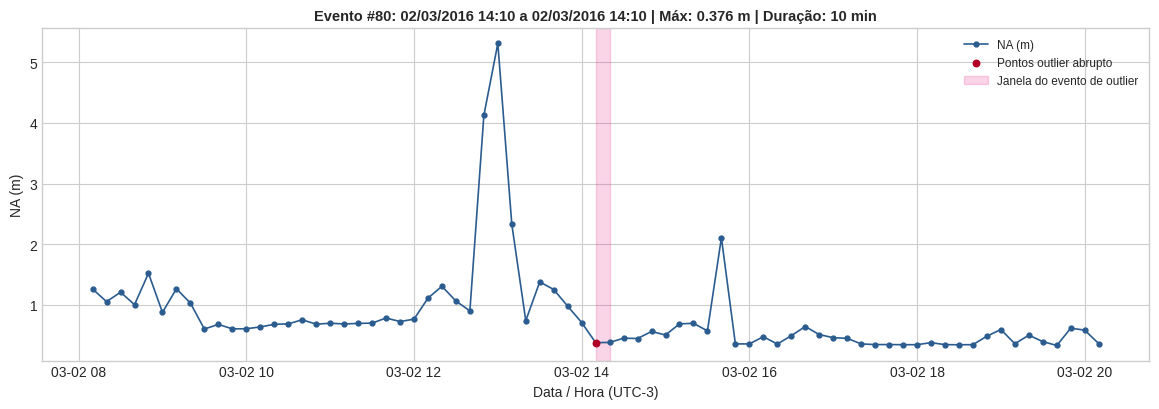

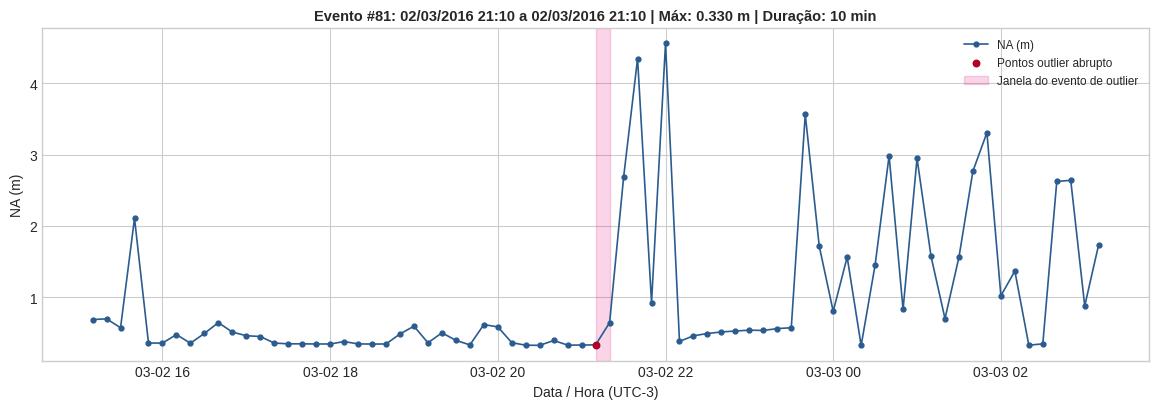

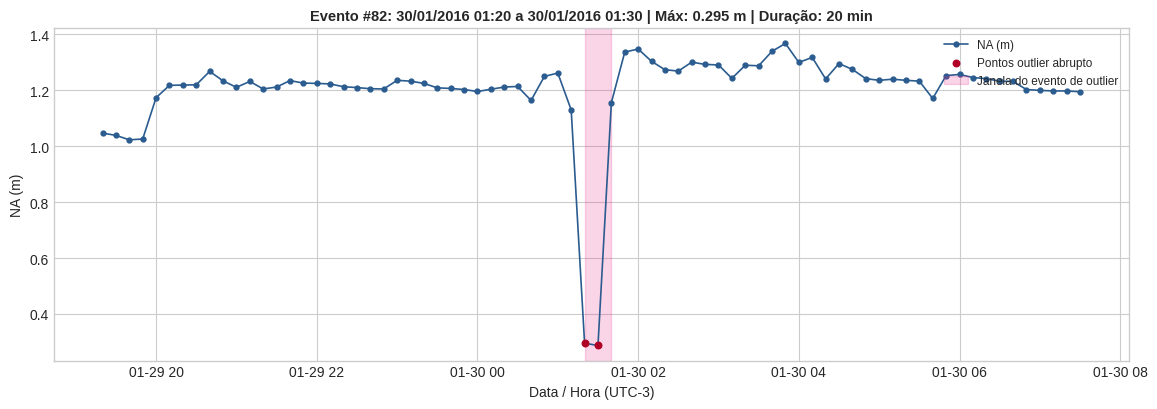

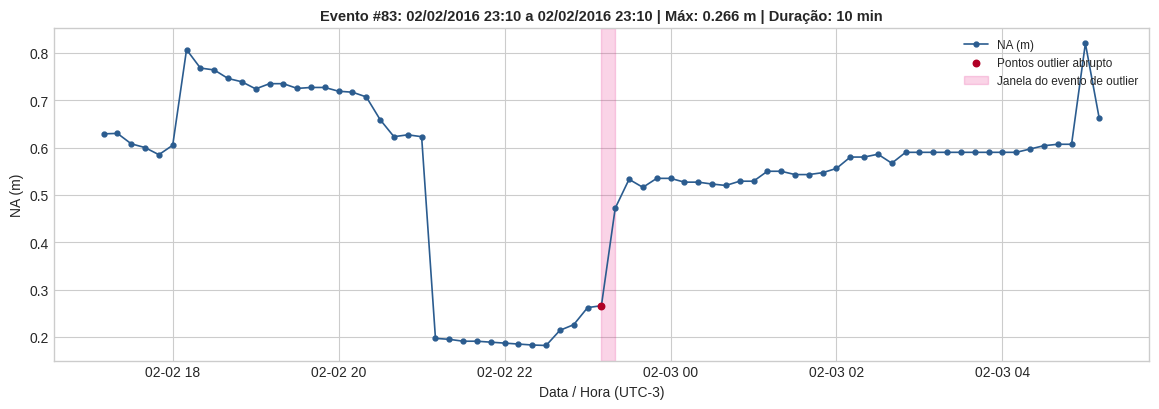

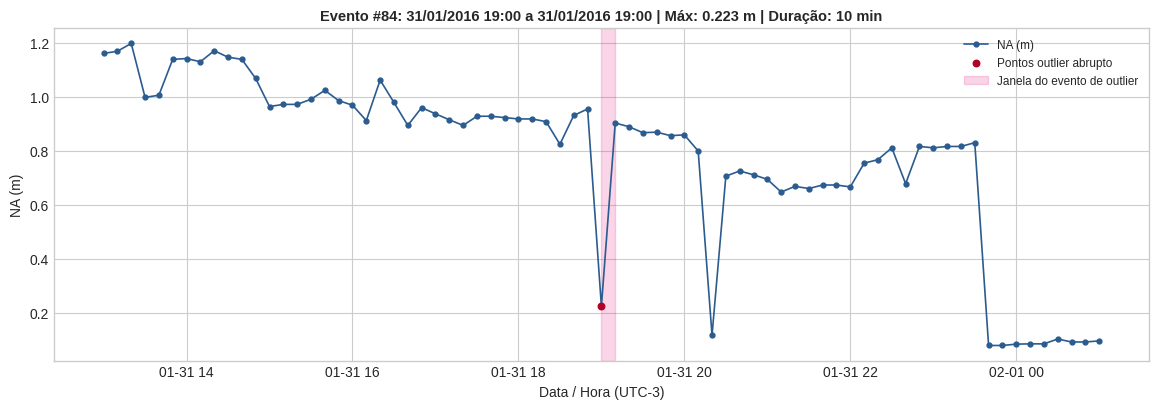

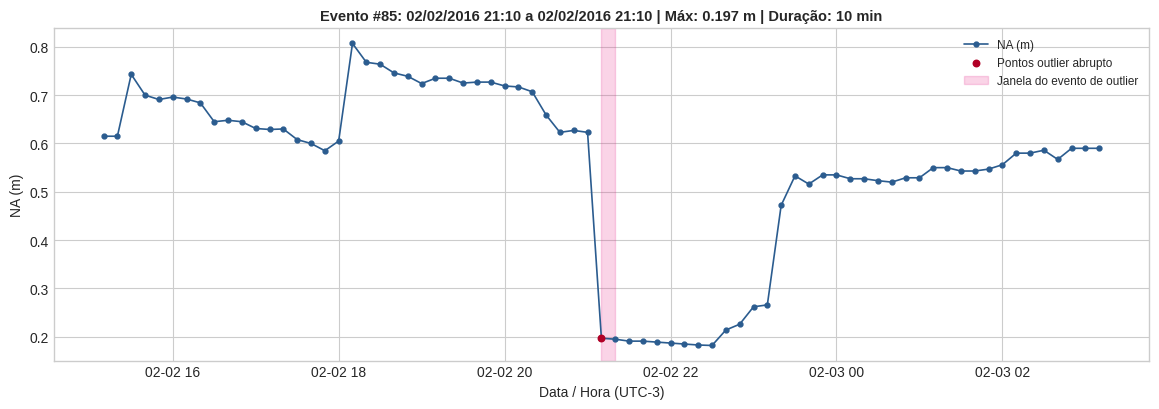

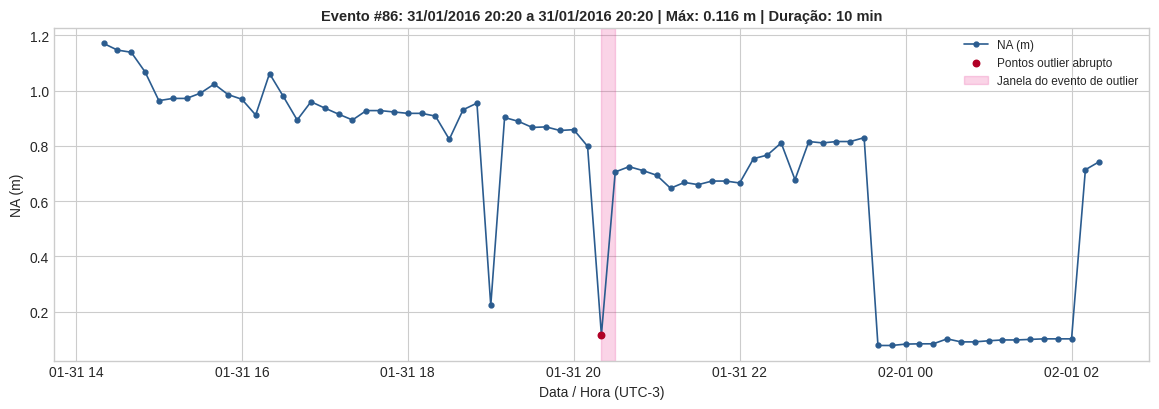

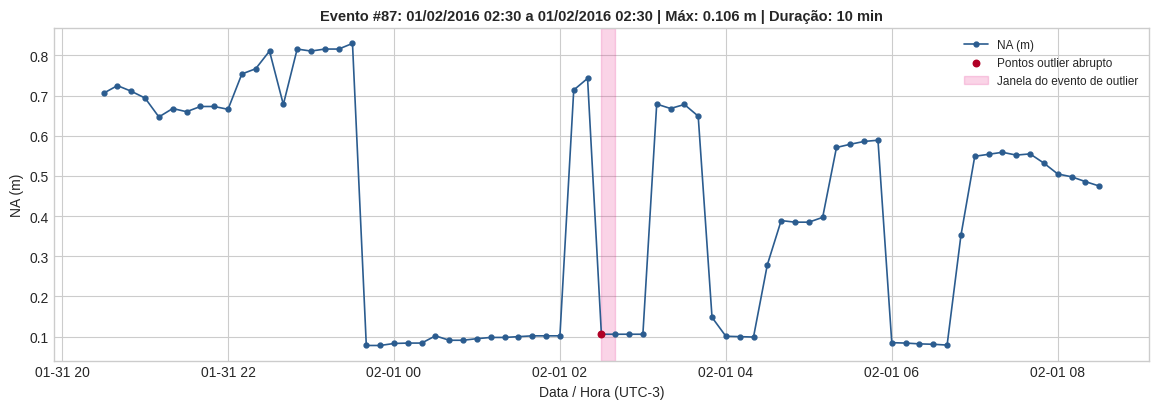

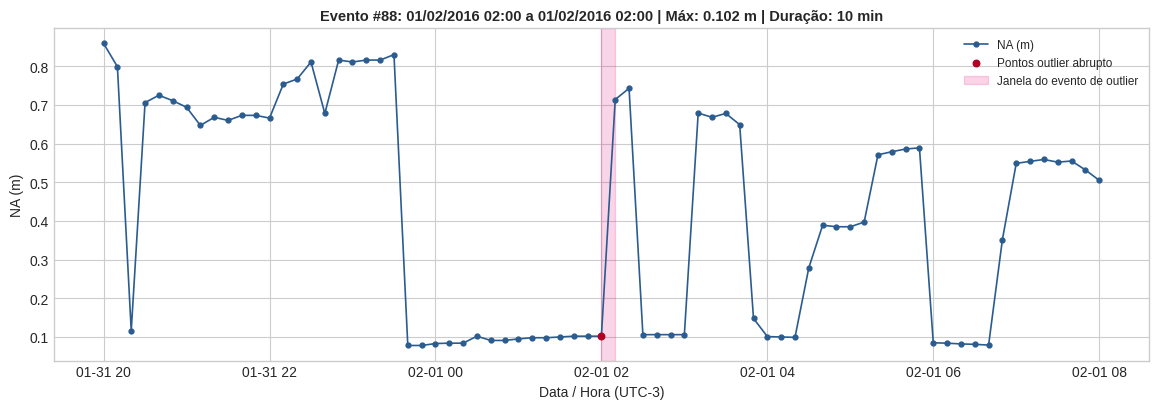

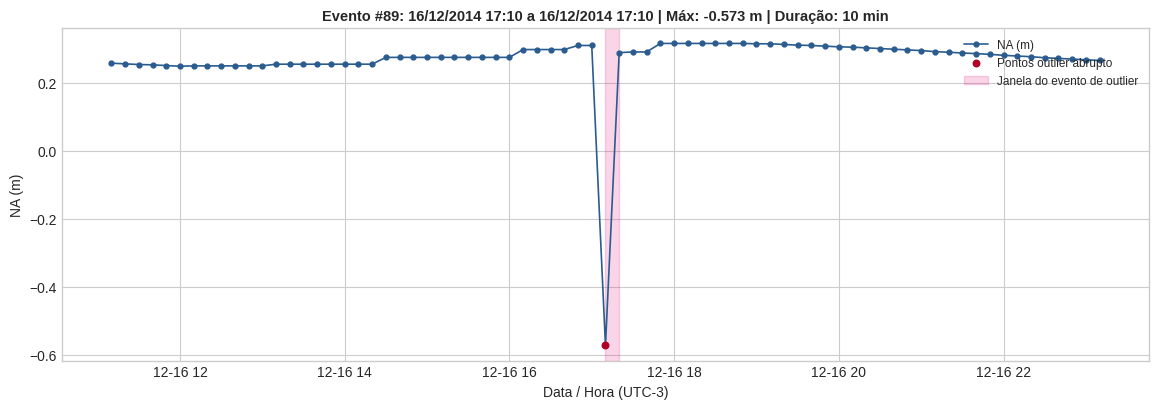

Relatório PDF de outliers gerado com sucesso em:
/content/drive/MyDrive/PUC/EQM2118/LAGOA/relatorio_outliers_nivel_lagoa_parte2.pdf


In [8]:
import os
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Montar o Google Drive (ignora se já estiver montado)
try:
  from google.colab import drive

  if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
except Exception:
  pass

# 2. Definir caminhos de entrada e saída do relatório PDF
pasta_lagoa = '/content/drive/MyDrive/PUC/EQM2118/LAGOA'
caminho_lagoa = os.path.join(pasta_lagoa, 'NA_Lagoa_JPA_10min_parte2_20130228_1620_ate_fim.csv')
caminho_pdf = os.path.join(pasta_lagoa, 'relatorio_outliers_nivel_lagoa_parte2.pdf')

# 3. Carregar e preparar a série temporal
df_lag = pd.read_csv(caminho_lagoa)
df_lag.columns = df_lag.columns.str.strip()

if 'time' not in df_lag.columns:
  candidatos_tempo = [
      'datetime',
      'DateTime',
      'data_hora',
      'Data_Hora',
      'Data/Hora',
      'data',
      'Data',
      'timestamp',
      'Timestamp',
  ]
  encontrada = next((c for c in candidatos_tempo if c in df_lag.columns), None)
  if encontrada:
    df_lag = df_lag.rename(columns={encontrada: 'time'})
  elif 'Dia' in df_lag.columns and 'Hora' in df_lag.columns:
    df_lag['time'] = (
        df_lag['Dia'].astype(str).str.strip()
        + ' '
        + df_lag['Hora'].astype(str).str.strip()
    )
  else:
    df_lag = df_lag.rename(columns={df_lag.columns[0]: 'time'})

dt_iso = pd.to_datetime(df_lag['time'], errors='coerce')
dt_br = pd.to_datetime(df_lag['time'], dayfirst=True, errors='coerce')
df_lag['time'] = dt_iso.fillna(dt_br)

df_lag = (
    df_lag.dropna(subset=['time'])
    .sort_values('time')
    .drop_duplicates(subset=['time'])
    .set_index('time')
)

colunas_numericas = [
    c for c in df_lag.select_dtypes(include=[np.number]).columns
]
col_nivel = 'NA (m)' if 'NA (m)' in df_lag.columns else colunas_numericas[0]
s = pd.to_numeric(df_lag[col_nivel], errors='coerce')

# ==============================================================================
# 4. DETECÇÃO DE OUTLIERS POR MUDANÇA ABRUPTA (ANTES E DEPOIS)
# ==============================================================================
# Parâmetros da mudança abrupta local (ajuste conforme a sensibilidade desejada)
# Janela local centrada de ~6h (36 passos de 10 min antes e depois)
janela_passos = 36
min_desvio_local = 0.25   # diferença mínima (m) em relação à mediana antes/depois
min_salto_borda = 0.15    # salto mínimo (m) em relação ao registro anterior ou posterior

# Mediana local usando janela centrada (inclui o próprio ponto; para evitar auto-influência
# em picos curtos, calculamos a mediana antes e depois separadamente)
# Em grade de 10 min, 36 passos = 6 horas
med_antes = s.shift(1).rolling(window=janela_passos, min_periods=6).median()
med_depois = (
    s.iloc[::-1].shift(1).rolling(window=janela_passos, min_periods=6).median().iloc[::-1]
)
med_vizinhanca = pd.concat([med_antes, med_depois], axis=1).median(axis=1)

# Desvio do valor atual em relação à vizinhança antes e depois
desvio_local = (s - med_vizinhanca).abs()

# Mudança abrupta em relação ao registro imediatamente anterior (entrada) e posterior (saída)
salto_antes = (s - s.shift(1)).abs()
salto_depois = (s - s.shift(-1)).abs()
salto_extremos = np.maximum(salto_antes.fillna(0.0), salto_depois.fillna(0.0))

# Outlier ocorre apenas quando há mudança abrupta em relação ao entorno antes e depois
is_outlier = (
    (desvio_local >= min_desvio_local)
    & (salto_extremos >= min_salto_borda)
    & s.notna()
)

# Variações consecutivas (|dh|) para referência diagnóstica
delta = s.diff().abs()
lim_d = delta.quantile(0.999)
out_d = (
    df_lag[delta > lim_d]
    .assign(delta_h=delta[delta > lim_d])
    .sort_values('delta_h', ascending=False)
)

# Agrupamento de registros consecutivos de outlier abrupto em episódios
salto_tempo = s.index.to_series().diff() != pd.Timedelta(minutes=10)
mudanca_estado = is_outlier != is_outlier.shift(1)
episodio_id = (salto_tempo | mudanca_estado).cumsum()

df_out = df_lag.loc[is_outlier, [col_nivel]].copy()
df_out['episodio_id'] = episodio_id[is_outlier]
df_out['desvio_local_m'] = desvio_local[is_outlier]
df_out['salto_max_m'] = salto_extremos[is_outlier]

resumo_episodios = (
    df_out.groupby('episodio_id')[col_nivel]
    .agg(
        inicio=lambda idx: idx.index.min(),
        fim=lambda idx: idx.index.max(),
        n_registros='count',
        minimo='min',
        maximo='max',
        media='mean',
    )
    .reset_index(drop=True)
)

if not resumo_episodios.empty:
  resumo_episodios['duracao_min'] = (
      (resumo_episodios['fim'] - resumo_episodios['inicio']).dt.total_seconds()
      / 60.0
      + 10.0
  )
  resumo_episodios = resumo_episodios.sort_values(
      'maximo', ascending=False
  ).reset_index(drop=True)

# Resumo anual
resumo_anual = (
    df_lag.groupby(df_lag.index.year)[col_nivel]
    .agg(
        contagem='count',
        nans=lambda x: pd.to_numeric(x, errors='coerce').isna().sum(),
        media='mean',
        minimo='min',
        maximo='max',
    )
    .round(3)
)

# ==============================================================================
# 5. EXIBIÇÃO DOS RESULTADOS NO CONSOLE DO COLAB
# ==============================================================================
desc = s.describe()

print('=' * 72)
print('RELATÓRIO DE AUDITORIA E ANÁLISE DE OUTLIERS — NÍVEL DA LAGOA')
print('=' * 72)
print(f'Arquivo analisado: {os.path.basename(caminho_lagoa)}')
print(f'Coluna de nível: {col_nivel} | Fuso horário: UTC-3\n')

print('1. INTEGRIDADE TEMPORAL E AUSÊNCIAS (NaN)')
print(f'• Período da série: {df_lag.index.min()} até {df_lag.index.max()}')
print(
    f'• Total de registros: {len(df_lag)} | Valores válidos: {s.notna().sum()}'
    f' | NaNs: {s.isna().sum()} ({100 * s.isna().mean():.2f}%)\n'
)

print(f'2. ESTATÍSTICAS DESCRITIVAS ({col_nivel})')
print(
    f"• Média: {desc['mean']:.4f} m | Desvio Padrão: {desc['std']:.4f} m"
)
print(
    f"• Mínimo: {desc['min']:.4f} m | Q1 (25%): {desc['25%']:.4f} m | Mediana"
    f" (50%): {desc['50%']:.4f} m | Q3 (75%): {desc['75%']:.4f} m | Máximo:"
    f" {desc['max']:.4f} m\n"
)

print('3. DIAGNÓSTICO DE OUTLIERS (MUDANÇA ABRUPTA ANTES E DEPOIS)')
print(
    f'• Janela local: {janela_passos} passos antes e depois'
    f' ({janela_passos * 10 / 60:.1f} h)'
)
print(
    f'• Critério: |valor - mediana_vizinhanca| >= {min_desvio_local:.2f} m'
    f' e salto_borda >= {min_salto_borda:.2f} m'
)
print(
    f'• Total de pontos com mudança abrupta: {len(df_out)}'
    f' ({100 * len(df_out) / max(len(df_lag), 1):.3f}%)'
)
print(f'• Total de episódios contínuos agrupados: {len(resumo_episodios)}')
print(
    '• Percentil 99,9% da variação consecutiva (|dh|):'
    f' {lim_d:.4f} m ({len(out_d)} registros acima)\n'
)

print('4. RESUMO ANUAL DA SÉRIE')
print(resumo_anual.to_string())
print('\n5. EPISÓDIOS CONTÍNUOS DE OUTLIERS ABRUPTOS (ORDENADOS PELO PICO MÁXIMO)')
if not resumo_episodios.empty:
  print(resumo_episodios.to_string(index=False))
else:
  print('Nenhum episódio de outlier abrupto encontrado pelos critérios definidos.')

print('\n6. TOP 15 MAIORES VARIAÇÕES CONSECUTIVAS (|dh|)')
if not out_d.empty:
  print(out_d[[col_nivel, 'delta_h']].head(15).to_string())
print('=' * 72 + '\n')

# ==============================================================================
# 6. GERAÇÃO DO RELATÓRIO EM PDF + EXIBIÇÃO DOS GRÁFICOS NA TELA
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid')

with PdfPages(caminho_pdf) as pdf:
  # --- PÁGINA 1 DO PDF: RESUMO ESTATÍSTICO, INTEGRIDADE E RESUMO ANUAL ---
  fig = plt.figure(figsize=(11.69, 8.27))
  fig.patch.set_facecolor('white')
  ax = fig.add_subplot(111)
  ax.axis('off')

  texto_relatorio = f"""
RELATÓRIO DE AUDITORIA E ANÁLISE DE OUTLIERS — NÍVEL DA LAGOA
Arquivo analisado: {os.path.basename(caminho_lagoa)}
Coluna de nível: {col_nivel} | Fuso horário de referência: UTC-3

1. INTEGRIDADE TEMPORAL E AUSÊNCIAS (NaN)
• Período da série: {df_lag.index.min()} até {df_lag.index.max()}
• Total de registros: {len(df_lag)} | Valores válidos: {s.notna().sum()} | NaNs: {s.isna().sum()} ({100 * s.isna().mean():.2f}%)

2. ESTATÍSTICAS DESCRITIVAS ({col_nivel})
• Média: {desc['mean']:.4f} m | Desvio Padrão: {desc['std']:.4f} m
• Mínimo: {desc['min']:.4f} m | Q1 (25%): {desc['25%']:.4f} m | Mediana (50%): {desc['50%']:.4f} m | Q3 (75%): {desc['75%']:.4f} m | Máximo: {desc['max']:.4f} m

3. DIAGNÓSTICO DE OUTLIERS (MUDANÇA ABRUPTA ANTES E DEPOIS)
• Janela local: {janela_passos} passos antes e depois ({janela_passos * 10 / 60:.1f} h)
• Critério: |valor - mediana_vizinhanca| >= {min_desvio_local:.2f} m e salto_borda >= {min_salto_borda:.2f} m
• Total de pontos com mudança abrupta: {len(df_out)} ({100 * len(df_out) / max(len(df_lag), 1):.3f}%)
• Total de episódios contínuos agrupados: {len(resumo_episodios)}
• Percentil 99,9% da variação consecutiva (|dh|): {lim_d:.4f} m ({len(out_d)} registros acima)

4. RESUMO ANUAL DA SÉRIE
{resumo_anual.to_string()}
""".strip()

  ax.text(
      0.03,
      0.97,
      texto_relatorio,
      transform=ax.transAxes,
      fontsize=9.5,
      verticalalignment='top',
      family='monospace',
  )
  pdf.savefig(fig, bbox_inches='tight')
  plt.close(fig)

  # --- PÁGINA 2 DO PDF: TABELA DE TODOS OS EPISÓDIOS (ATÉ 35 POR PÁGINA) ---
  if not resumo_episodios.empty:
    linhas_por_pag = 35
    for ini_tab in range(0, len(resumo_episodios), linhas_por_pag):
      tab_df = resumo_episodios.iloc[ini_tab : ini_tab + linhas_por_pag].copy()
      fig, ax = plt.subplots(figsize=(11.69, 8.27))
      ax.axis('off')
      ax.set_title(
          f'Episódios Contínuos de Outliers Abruptos ({ini_tab + 1} a'
          f' {ini_tab + len(tab_df)} de {len(resumo_episodios)})',
          fontsize=12,
          fontweight='bold',
          pad=14,
      )

      tab_df['inicio'] = tab_df['inicio'].dt.strftime('%d/%m/%Y %H:%M')
      tab_df['fim'] = tab_df['fim'].dt.strftime('%d/%m/%Y %H:%M')
      tab_df['minimo'] = tab_df['minimo'].round(3)
      tab_df['maximo'] = tab_df['maximo'].round(3)
      tab_df['media'] = tab_df['media'].round(3)
      tab_df['duracao_min'] = tab_df['duracao_min'].round(0).astype(int)

      tabela = ax.table(
          cellText=tab_df.values,
          colLabels=[
              'Início',
              'Fim',
              'Registros',
              'Mín (m)',
              'Máx (m)',
              'Média (m)',
              'Duração (min)',
          ],
          loc='center',
          cellLoc='center',
      )
      tabela.auto_set_font_size(False)
      tabela.set_fontsize(8.0)
      tabela.scale(1.0, 1.2)

      for (row_idx, _), cell in tabela.get_celld().items():
        if row_idx == 0:
          cell.set_facecolor('#2b5c8f')
          cell.get_text().set_color('white')
          cell.get_text().set_weight('bold')
        elif row_idx % 2 == 0:
          cell.set_facecolor('#f2f5f9')

      pdf.savefig(fig, bbox_inches='tight')
      plt.close(fig)

  # --- GRÁFICO 1: SÉRIE TEMPORAL COMPLETA E FAIXAS DE OUTLIERS ABRUPTOS ---
  fig, ax = plt.subplots(figsize=(11.69, 5.2))
  ax.plot(s.index, s.values, color='#2b5c8f', linewidth=0.7, label=col_nivel)

  for i, row in resumo_episodios.iterrows():
    ax.axvspan(
        row['inicio'],
        row['fim'] + pd.Timedelta(minutes=10),
        color='#e7298a',
        alpha=0.22,
        label='Períodos de outlier abrupto' if i == 0 else None,
    )

  if not df_out.empty:
    ax.scatter(
        df_out.index,
        df_out[col_nivel],
        color='#b10026',
        s=12,
        zorder=4,
        label='Pontos outlier abrupto',
    )

  ax.set_title(
      'Série Temporal do Nível da Lagoa e Períodos de Outliers Abruptos'
      ' (Antes e Depois)',
      fontsize=11,
      fontweight='bold',
  )
  ax.set_xlabel('Data / Hora (UTC-3)')
  ax.set_ylabel(col_nivel)
  ax.legend(loc='upper right')
  plt.tight_layout()
  pdf.savefig(fig, bbox_inches='tight')
  plt.show()
  plt.close(fig)

  # --- GRÁFICO 2: TIMELINE HORIZONTAL DOS TOP 20 EPISÓDIOS ---
  if not resumo_episodios.empty:
    top_ep = resumo_episodios.head(20).iloc[::-1]
    fig, ax = plt.subplots(figsize=(11.69, 6.2))
    for idx_pos, (_, row) in enumerate(top_ep.iterrows()):
      dur_horas = max(row['duracao_min'] / 60.0, 0.16)
      ax.barh(
          idx_pos,
          dur_horas,
          left=row['inicio'],
          height=0.6,
          color='#d95f02',
          edgecolor='black',
          linewidth=0.5,
      )
      ax.text(
          row['fim'] + pd.Timedelta(hours=12),
          idx_pos,
          f"máx: {row['maximo']:.2f} m ({row['duracao_min']:.0f} min)",
          va='center',
          fontsize=8.0,
      )

    rotulos_y = [
        f"{r['inicio'].strftime('%d/%m/%Y %H:%M')}"
        for _, r in top_ep.iterrows()
    ]
    ax.set_yticks(range(len(top_ep)))
    ax.set_yticklabels(rotulos_y, fontsize=8.0)
    ax.set_title(
        'Top 20 Episódios de Outlier Abrupto por Valor Máximo (Janela'
        ' Temporal e Duração)',
        fontsize=11,
        fontweight='bold',
    )
    ax.set_xlabel('Data de Ocorrência (UTC-3)')
    plt.tight_layout()
    pdf.savefig(fig, bbox_inches='tight')
    plt.show()
    plt.close(fig)

  # --- GRÁFICO 3: ZOOM NOS TOP 12 EPISÓDIOS (3 POR PÁGINA) ---
  n_zoom = min(12, len(resumo_episodios))
  episodios_zoom = resumo_episodios.head(n_zoom)
  por_pagina = 3

  for inicio_pag in range(0, n_zoom, por_pagina):
    bloco = episodios_zoom.iloc[inicio_pag : inicio_pag + por_pagina]
    fig, axes = plt.subplots(
        len(bloco), 1, figsize=(11.69, 2.7 * len(bloco)), sharey=False
    )
    if len(bloco) == 1:
      axes = [axes]

    for ax_z, (_, row) in zip(axes, bloco.iterrows()):
      margem = pd.Timedelta(hours=6)
      trecho = s.loc[row['inicio'] - margem : row['fim'] + margem]

      ax_z.plot(
          trecho.index,
          trecho.values,
          marker='o',
          markersize=3,
          linewidth=1.1,
          color='#1b7837',
      )
      ax_z.axvspan(
          row['inicio'],
          row['fim'] + pd.Timedelta(minutes=10),
          color='#e7298a',
          alpha=0.2,
      )
      ax_z.set_title(
          f"Episódio: {row['inicio'].strftime('%d/%m/%Y %H:%M')} a"
          f" {row['fim'].strftime('%d/%m/%Y %H:%M')} | Máx:"
          f" {row['maximo']:.3f} m | Duração: {row['duracao_min']:.0f} min",
          fontsize=9.5,
      )
      ax_z.set_ylabel(col_nivel)

    axes[-1].set_xlabel('Data / Hora (UTC-3)')
    plt.tight_layout()
    pdf.savefig(fig, bbox_inches='tight')
    plt.show()
    plt.close(fig)

  # --- GRÁFICO 4: GRÁFICOS INDIVIDUAIS DE TODOS OS EVENTOS/EPISÓDIOS DE OUTLIERS ---
  if not resumo_episodios.empty:
    margem_evento = pd.Timedelta(hours=6)
    for idx_ev, row in resumo_episodios.iterrows():
      ini_ev = row['inicio'] - margem_evento
      fim_ev = row['fim'] + margem_evento
      trecho_ev = s.loc[ini_ev:fim_ev]
      out_ev = df_out.loc[row['inicio'] : row['fim']]

      fig, ax_ev = plt.subplots(figsize=(11.69, 4.2))
      ax_ev.plot(
          trecho_ev.index,
          trecho_ev.values,
          marker='o',
          markersize=3.5,
          linewidth=1.2,
          color='#2b5c8f',
          label=col_nivel,
      )
      if not out_ev.empty:
        ax_ev.scatter(
            out_ev.index,
            out_ev[col_nivel],
            color='#b10026',
            s=22,
            zorder=5,
            label='Pontos outlier abrupto',
        )
      ax_ev.axvspan(
          row['inicio'],
          row['fim'] + pd.Timedelta(minutes=10),
          color='#e7298a',
          alpha=0.2,
          label='Janela do evento de outlier',
      )

      ax_ev.set_title(
          f"Evento #{idx_ev + 1}: {row['inicio'].strftime('%d/%m/%Y %H:%M')}"
          f" a {row['fim'].strftime('%d/%m/%Y %H:%M')} | Máx:"
          f" {row['maximo']:.3f} m | Duração: {row['duracao_min']:.0f} min",
          fontsize=10.5,
          fontweight='bold',
      )
      ax_ev.set_xlabel('Data / Hora (UTC-3)')
      ax_ev.set_ylabel(col_nivel)
      ax_ev.legend(loc='upper right', fontsize=8.5)
      plt.tight_layout()
      pdf.savefig(fig, bbox_inches='tight')
      plt.show()
      plt.close(fig)

print(f'Relatório PDF de outliers gerado com sucesso em:\n{caminho_pdf}')

### *1.7.8 Tratamento dos outliers aplicando NaN nos dados com alteração sem chuva significativa (>0.5mm)*

In [14]:
import os
import numpy as np
import pandas as pd

# 1. Montar o Google Drive (se necessário)
try:
  from google.colab import drive

  if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
except Exception:
  pass

pasta_lagoa = '/content/drive/MyDrive/PUC/EQM2118/LAGOA'
caminho_cruzado = os.path.join(
    pasta_lagoa,
    'NA_Lagoa_JPA_10min_parte2_20130228_1620_ate_fim_cruzado_chuva.csv',
)
caminho_diag = os.path.join(
    pasta_lagoa, 'diagnostico_abruptas_x_precipitacao_parte2.csv'
)
caminho_saida_limpo = os.path.join(
    pasta_lagoa,
    'NA_Lagoa_JPA_10min_parte2_20130228_1620_ate_fim_limpo.csv',
)

# 2. Carregar série cruzada e diagnóstico de episódios
df_lag = pd.read_csv(caminho_cruzado)
df_lag.columns = [c.strip() for c in df_lag.columns]
col_t = 'time' if 'time' in df_lag.columns else df_lag.columns[0]
df_lag[col_t] = pd.to_datetime(df_lag[col_t], errors='coerce')
df_lag = (
    df_lag.dropna(subset=[col_t])
    .sort_values(col_t)
    .drop_duplicates(subset=[col_t])
    .set_index(col_t)
)

col_nivel = 'NA (m)' if 'NA (m)' in df_lag.columns else df_lag.columns[0]
s_original = pd.to_numeric(df_lag[col_nivel], errors='coerce')

df_diag = pd.read_csv(caminho_diag)
df_diag['inicio'] = pd.to_datetime(df_diag['inicio'], errors='coerce')
df_diag['fim'] = pd.to_datetime(df_diag['fim'], errors='coerce')

# 3. Construir máscara booleana para todos os intervalos 'SEM CHUVA RELEVANTE'
mask_sem_chuva = pd.Series(False, index=df_lag.index)

episodios_sem_chuva = df_diag[
    df_diag['classificacao'] == 'SEM CHUVA RELEVANTE (<=0.5mm)'
]

for _, row in episodios_sem_chuva.iterrows():
  if pd.notna(row['inicio']) and pd.notna(row['fim']):
    mask_sem_chuva.loc[row['inicio'] : row['fim']] = True

# 4. Aplicar máscara gerando nova coluna limpa (preservando a original)
s_limpo = s_original.mask(mask_sem_chuva, np.nan)

df_lag['flag_mascarado_sem_chuva'] = mask_sem_chuva.astype(int)
df_lag['NA_limpo_m'] = s_limpo.round(4)

df_lag.to_csv(caminho_saida_limpo)

print('=== RESUMO DO MASCARAMENTO (SEM CHUVA RELEVANTE) ===')
print(f'Episódios SEM CHUVA RELEVANTE: {len(episodios_sem_chuva)}')
print(f'Registros mascarados (NaN):  {int(mask_sem_chuva.sum())}')
print(
    f'Válidos originais -> limpos:   {int(s_original.notna().sum())} ->'
    f' {int(s_limpo.notna().sum())}'
)
print(
    f'Máximo original -> limpo:     {s_original.max():.4f} m ->'
    f' {s_limpo.max():.4f} m'
)
print(
    f'Mínimo original -> limpo:     {s_original.min():.4f} m ->'
    f' {s_limpo.min():.4f} m'
)
print(f'\nArquivo salvo em:\n{caminho_saida_limpo}')

=== RESUMO DO MASCARAMENTO (SEM CHUVA RELEVANTE) ===
Episódios SEM CHUVA RELEVANTE: 31
Registros mascarados (NaN):  325
Válidos originais -> limpos:   206204 -> 205879
Máximo original -> limpo:     5.3110 m -> 2.5560 m
Mínimo original -> limpo:     -0.5730 m -> -0.1350 m

Arquivo salvo em:
/content/drive/MyDrive/PUC/EQM2118/LAGOA/NA_Lagoa_JPA_10min_parte2_20130228_1620_ate_fim_limpo.csv


### *1.7.9 Dados consolidados de nível da lagoa parte 2 com tratamento de NaN*

In [15]:
import os
import pandas as pd

try:
  from google.colab import drive

  if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
except Exception:
  pass

pasta_lagoa = '/content/drive/MyDrive/PUC/EQM2118/LAGOA'
caminho_limpo = os.path.join(
    pasta_lagoa,
    'NA_Lagoa_JPA_10min_parte2_20130228_1620_ate_fim_limpo.csv',
)
caminho_final_real = os.path.join(
    pasta_lagoa,
    'NA_Lagoa_JPA_10min_parte2_20130228_1620_ate_fim_real_limpo.csv',
)

df = pd.read_csv(caminho_limpo)
df.columns = [c.strip() for c in df.columns]
col_t = 'time' if 'time' in df.columns else df.columns[0]
df[col_t] = pd.to_datetime(df[col_t], errors='coerce')
df = (
    df.dropna(subset=[col_t])
    .sort_values(col_t)
    .drop_duplicates(subset=[col_t])
    .set_index(col_t)
)

grade_10min = pd.date_range(
    start=df.index.min(), end=df.index.max(), freq='10min'
)
df = df.reindex(grade_10min)

col_alvo = 'NA_limpo_m' if 'NA_limpo_m' in df.columns else 'NA (m)'
s_real = pd.to_numeric(df[col_alvo], errors='coerce')

df['NA_real_limpo_m'] = s_real.round(4)
df.to_csv(caminho_final_real)

print('=== BASE DA LAGOA (APENAS DADOS REAIS LIMPOS) ===')
print(f'Total de passos na grade (10 min): {len(df)}')
print(f'Registros reais válidos:           {int(s_real.notna().sum())}')
print(f'Registros ausentes (NaN mantidos): {int(s_real.isna().sum())}')
print(f'Arquivo salvo em:                  {caminho_final_real}')

=== BASE DA LAGOA (APENAS DADOS REAIS LIMPOS) ===
Total de passos na grade (10 min): 239199
Registros reais válidos:           205879
Registros ausentes (NaN mantidos): 33320
Arquivo salvo em:                  /content/drive/MyDrive/PUC/EQM2118/LAGOA/NA_Lagoa_JPA_10min_parte2_20130228_1620_ate_fim_real_limpo.csv


### **1.8 CONSOLIDAÇÃO DA BASE DE DADOS (maré + precipitação + lagoa)**

In [20]:
import os
import pandas as pd

try:
  from google.colab import drive

  if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
except Exception:
  pass

# 1. Caminhos das planilhas de entrada e saída
pasta_base = '/content/drive/MyDrive/PUC/EQM2118'
pasta_lagoa = os.path.join(pasta_base, 'LAGOA')
pasta_chuva = os.path.join(pasta_base, 'CHUVA_2010_2026')
pasta_consolidados = os.path.join(pasta_base, 'CONSOLIDADOS')

caminho_lagoa = os.path.join(
    pasta_lagoa,
    'NA_Lagoa_JPA_10min_parte2_20130228_1620_ate_fim_real_limpo.csv',
)
caminho_chuva = os.path.join(
    pasta_chuva, 'banco_precipitacoes_completo_2010_2026_NaN_preenchido.csv'
)
caminho_mare = os.path.join(
    pasta_consolidados, 'mare_consolidada_10min_utc3.csv'
)

caminho_saida_10min = os.path.join(
    pasta_consolidados, 'tabela_unificada_apenas_10min_ate_20170916_1840.csv'
)


def ler_csv_flexivel(caminho):
  """Lê CSV detectando separador (, ou ;) automaticamente."""
  with open(caminho, 'r', encoding='utf-8-sig', errors='replace') as f:
    primeira_linha = f.readline()
  sep = ';' if primeira_linha.count(';') > primeira_linha.count(',') else ','
  df = pd.read_csv(caminho, sep=sep, encoding='utf-8-sig')
  df.columns = [c.strip() for c in df.columns]
  return df


def parse_datas_exatas(serie_dt):
  """Converte timestamps preservando o horário exato sem alterar valores."""
  s_str = serie_dt.astype(str).str.strip()
  dt = pd.to_datetime(s_str, format='%Y-%m-%d %H:%M:%S', errors='coerce')
  falt = dt.isna()
  if falt.any():
    dt = dt.fillna(
        pd.to_datetime(
            s_str[falt], dayfirst=True, format='mixed', errors='coerce'
        )
    )
  if hasattr(dt.dt, 'tz') and dt.dt.tz is not None:
    dt = dt.dt.tz_convert('America/Sao_Paulo').dt.tz_localize(None)
  return dt


def carregar_coluna_10min(
    caminho,
    candidatos_dt,
    candidatos_exatos_val,
    candidatos_sub_val,
    nome_saida,
):
  """Carrega uma única coluna numérica indexada por datetime exato, sem manipulação."""
  df = ler_csv_flexivel(caminho)
  cols_low = {c.lower(): c for c in df.columns}

  col_dt = next(
      (cols_low[k] for k in candidatos_dt if k in cols_low), df.columns[0]
  )

  col_val = next(
      (cols_low[k] for k in candidatos_exatos_val if k in cols_low), None
  )
  if col_val is None:
    col_val = next(
        (
            c
            for c in df.columns
            if c != col_dt
            and 'flag' not in c.lower()
            and any(k in c.lower() for k in candidatos_sub_val)
        ),
        None,
    )
  if col_val is None:
    raise KeyError(
        f'Coluna de valor não encontrada em {os.path.basename(caminho)}.'
        f' Colunas disponíveis: {list(df.columns)}'
    )

  dt = parse_datas_exatas(df[col_dt])
  s_num = df[col_val].astype(str).str.strip().str.replace(',', '.', regex=False)
  val = pd.to_numeric(s_num, errors='coerce')

  print(
      f'[{os.path.basename(caminho)}] dt="{col_dt}" | val="{col_val}" |'
      f' válidos={int(val.notna().sum())}'
  )

  serie = pd.Series(val.values, index=dt, name=nome_saida)
  serie = serie[~serie.index.isna() & serie.notna()].sort_index()
  serie = serie[~serie.index.duplicated(keep='last')]
  return serie


# 2. Extrair apenas as séries de 10 minutos (sem manipulação ou interpolação)
s_lagoa = carregar_coluna_10min(
    caminho_lagoa,
    ['time', 'datetime', 'data_hora', 'date', 'unnamed: 0'],
    ['na_real_limpo_m', 'na_limpo_m', 'na (m)', 'na_m'],
    ['na_real', 'na_limpo', 'na (m)', 'nivel'],
    'NA_lagoa_10min_m',
)

s_chuva_10min = carregar_coluna_10min(
    caminho_chuva,
    ['datetime', 'time', 'data_hora', 'date'],
    ['precip_10min', 'chuva_10min', '10min', '10_min'],
    ['10min', '10_min', '10 min'],
    'chuva_10min_mm',
)

s_mare_10min = carregar_coluna_10min(
    caminho_mare,
    ['time', 'datetime', 'data_hora', 'timestamp', 'date'],
    ['nivel_mar_total_m', 'mare_m', 'mare', 'maré', 'tide'],
    ['nivel_mar_total', 'mare', 'maré', 'tide'],
    'mare_10min_m',
)

# 3. Grade regular de 10 minutos até 16/09/2017 18:40:00
dt_min_lagoa = s_lagoa.index.min() if not s_lagoa.empty else pd.NaT
if pd.isna(dt_min_lagoa):
  print(
      'Aviso: s_lagoa sem data inicial válida. Usando 2013-02-28 16:20:00.'
  )
  ini_grade = pd.Timestamp('2013-02-28 16:20:00')
else:
  ini_grade = dt_min_lagoa.ceil('10min')

fim_grade = pd.Timestamp('2017-09-16 18:40:00')
grade_10min = pd.date_range(start=ini_grade, end=fim_grade, freq='10min')

# 4. Consolidar apenas os valores originais de 10 min
df_10min = pd.DataFrame({
    'datetime': grade_10min.strftime('%Y-%m-%d %H:%M:%S'),
    'NA_lagoa_10min_m': s_lagoa.reindex(grade_10min).values,
    'chuva_10min_mm': s_chuva_10min.reindex(grade_10min).values,
    'mare_10min_m': s_mare_10min.reindex(grade_10min).values,
})

df_10min.to_csv(caminho_saida_10min, index=False)

print('\n=== CONSOLIDAÇÃO APENAS COM VARIÁVEIS DE 10 MINUTOS ===')
print(f'Arquivo salvo em: {caminho_saida_10min}')
print(f'Início:           {df_10min["datetime"].iloc[0]}')
print(f'Fim:              {df_10min["datetime"].iloc[-1]}')
print(f'Total de linhas:  {len(df_10min)}\n')

for col in ['NA_lagoa_10min_m', 'chuva_10min_mm', 'mare_10min_m']:
  n_validos = int(df_10min[col].notna().sum())
  n_nan = int(df_10min[col].isna().sum())
  print(
      f'  • {col}: {n_validos} válidos | {n_nan} NaNs'
      f' ({n_nan / len(df_10min) * 100:.2f}%)'
  )

[NA_Lagoa_JPA_10min_parte2_20130228_1620_ate_fim_real_limpo.csv] dt="Unnamed: 0" | val="NA_real_limpo_m" | válidos=205879
[banco_precipitacoes_completo_2010_2026_NaN_preenchido.csv] dt="datetime" | val="precip_10min" | válidos=851219
[mare_consolidada_10min_utc3.csv] dt="time" | val="nivel_mar_total_m" | válidos=851370

=== CONSOLIDAÇÃO APENAS COM VARIÁVEIS DE 10 MINUTOS ===
Arquivo salvo em: /content/drive/MyDrive/PUC/EQM2118/CONSOLIDADOS/tabela_unificada_apenas_10min_ate_20170916_1840.csv
Início:           2013-02-28 16:20:00
Fim:              2017-09-16 18:40:00
Total de linhas:  239199

  • NA_lagoa_10min_m: 205879 válidos | 33320 NaNs (13.93%)
  • chuva_10min_mm: 239199 válidos | 0 NaNs (0.00%)
  • mare_10min_m: 239199 válidos | 0 NaNs (0.00%)
